In [1]:
# Exploratory Data Analysis
# Phase 5.1 — Setup and Data Overview

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project paths
PROJECT_ROOT = Path.cwd().parent

CLEAN_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "online_retail_clean.parquet"
)

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Load cleaned dataset
df = pd.read_parquet(CLEAN_DATA_PATH)

print("Dataset loaded successfully.")
print(f"Shape: {df.shape}")

Dataset loaded successfully.
Shape: (1033036, 33)


In [2]:
# Dataset structure and column information

print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\nCOLUMN DATA TYPES")
print("=" * 60)

print(df.dtypes)

print("\nMISSING VALUES")
print("=" * 60)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (
        df.isna().mean() * 100
    )
})

missing_summary = missing_summary.sort_values(
    "missing_count",
    ascending=False
)

display(missing_summary)

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1033036 entries, 0 to 1033035
Data columns (total 33 columns):
 #   Column                          Non-Null Count    Dtype         
---  ------                          --------------    -----         
 0   Invoice                         1033036 non-null  string        
 1   StockCode                       1033036 non-null  string        
 2   Description                     1031414 non-null  string        
 3   Quantity                        1033036 non-null  int64         
 4   InvoiceDate                     1033036 non-null  datetime64[us]
 5   Price                           1033036 non-null  float64       
 6   Customer ID                     797885 non-null   float64       
 7   Country                         1033036 non-null  string        
 8   YearMonth                       1033036 non-null  period[M]     
 9   Description_was_missing         1033036 non-null  bool          
 10  is_cancellation                 1

,missing_count,missing_percentage
Customer ID,235151,22.76
Description_normalized,1622,0.16
Description,1622,0.16
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
StockCode,0,0.00
YearMonth,0,0.00


In [3]:
# Classify analytical variables

numerical_columns = [
    "Quantity",
    "Price",
    "line_value",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]

categorical_columns = [
    "Country",
    "StockCode",
    "StockCode_normalized",
    "transaction_category",
    "zero_price_category",
    "merchandise_revenue_treatment"
]

datetime_columns = [
    "InvoiceDate",
    "YearMonth"
]

print("NUMERICAL VARIABLES")
print("=" * 60)

display(
    df[numerical_columns].describe().T
)

print("\nCATEGORICAL VARIABLES")
print("=" * 60)

categorical_summary = pd.DataFrame({
    "unique_values": df[categorical_columns].nunique(),
    "missing_values": df[categorical_columns].isna().sum()
})

display(categorical_summary)

print("\nDATETIME VARIABLES")
print("=" * 60)

for column in datetime_columns:
    print(
        f"{column}: "
        f"{df[column].min()} to {df[column].max()}"
    )

NUMERICAL VARIABLES


,count,mean,std,min,25%,50%,75%,max
Quantity,"1,033,036.00",10.08,175.20,"-80,995.00",1.00,3.00,10.00,"80,995.00"
Price,"1,033,036.00",4.61,122.40,"-53,594.36",1.25,2.10,4.15,"38,970.00"
line_value,"1,033,036.00",18.25,295.69,"-168,469.60",3.75,9.92,17.70,"168,469.60"
merchandise_revenue,"1,033,036.00",18.31,269.08,"-168,469.60",3.75,9.90,17.70,"168,469.60"
qualifying_purchase_revenue,"1,033,036.00",16.52,196.12,0.00,0.39,6.96,16.50,"168,469.60"



CATEGORICAL VARIABLES


,unique_values,missing_values
Country,43,0
StockCode,5305,0
StockCode_normalized,5131,0
transaction_category,16,0
zero_price_category,4,0
merchandise_revenue_treatment,4,0



DATETIME VARIABLES
InvoiceDate: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
YearMonth: 2009-12 to 2011-12


In [4]:
# Numerical distribution diagnostics

distribution_summary = pd.DataFrame({
    "mean": df[numerical_columns].mean(),
    "median": df[numerical_columns].median(),
    "std": df[numerical_columns].std(),
    "skewness": df[numerical_columns].skew(),
    "negative_count": (df[numerical_columns] < 0).sum(),
    "zero_count": (df[numerical_columns] == 0).sum(),
    "positive_count": (df[numerical_columns] > 0).sum(),
    "negative_percentage": (
        (df[numerical_columns] < 0).mean() * 100
    )
})

display(distribution_summary)

,mean,median,std,skewness,negative_count,zero_count,positive_count,negative_percentage
Quantity,10.08,3.00,175.20,4.09,22496,0,1010540,2.18
Price,4.61,2.10,122.40,-78.98,5,6014,1027017,0.00
line_value,18.25,9.92,295.69,-12.24,19108,6014,1007914,1.85
merchandise_revenue,18.31,9.90,269.08,3.29,17929,11765,1003342,1.74
qualifying_purchase_revenue,16.52,6.96,196.12,681.37,0,256532,776504,0.00


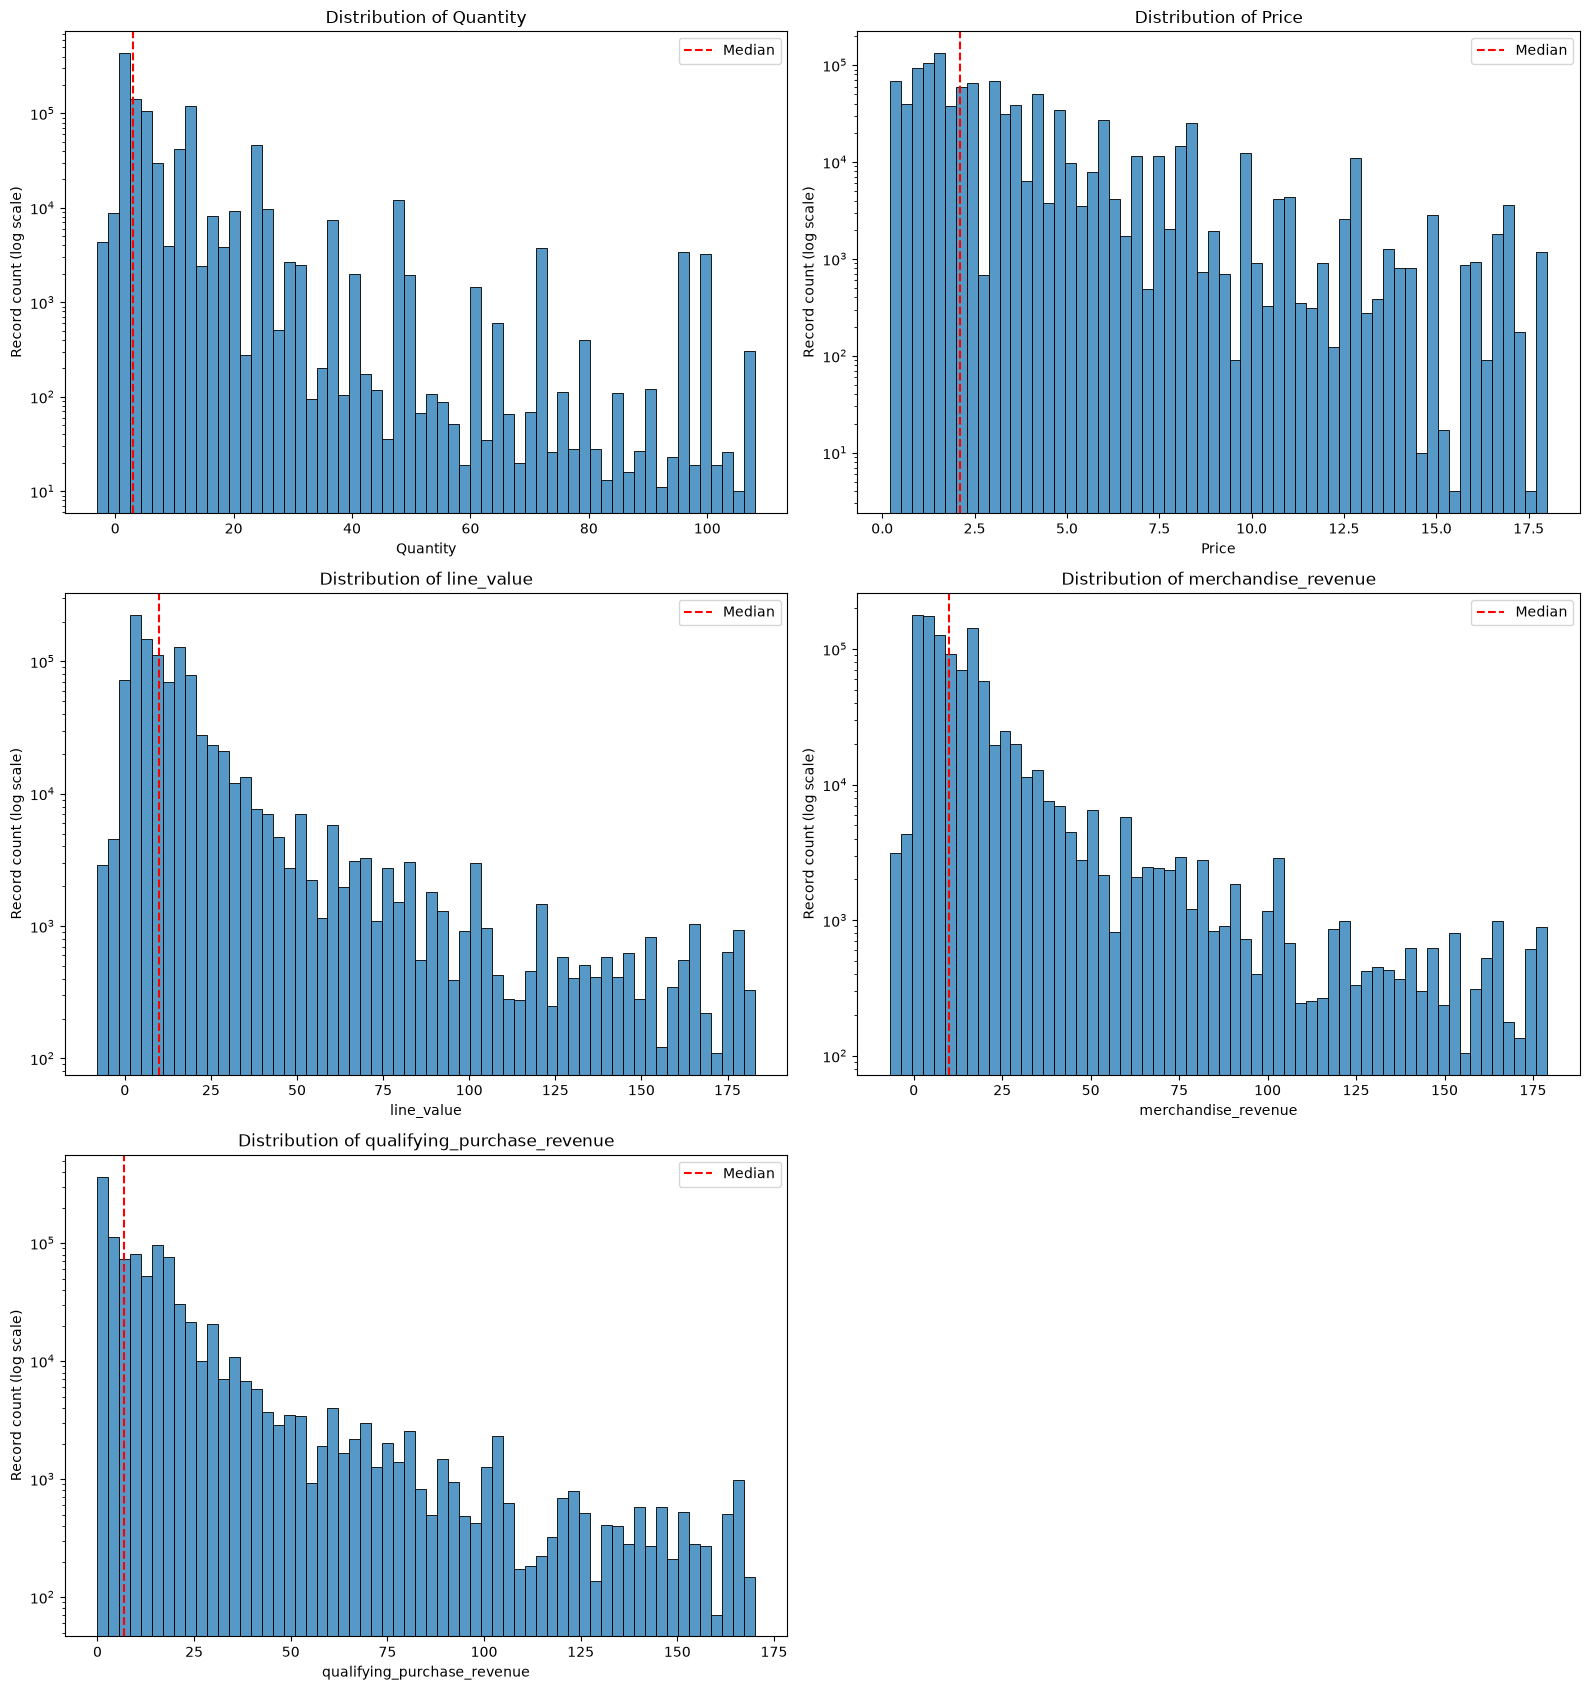

In [7]:
# Numerical distributions with percentile-based binning

fig, axes = plt.subplots(3, 2, figsize=(16, 17))

plot_columns = [
    "Quantity",
    "Price",
    "line_value",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]

for ax, column in zip(axes.flatten(), plot_columns):

    lower_limit = df[column].quantile(0.01)
    upper_limit = df[column].quantile(0.99)

    sns.histplot(
        data=df,
        x=column,
        bins=60,
        binrange=(lower_limit, upper_limit),
        ax=ax
    )

    ax.set_yscale("log")

    ax.axvline(
        df[column].median(),
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Median"
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Record count (log scale)")
    ax.legend()

fig.delaxes(axes.flatten()[5])

plt.tight_layout()
plt.show()

REVENUE ELIGIBILITY DISTRIBUTION


,record_count,percentage
Zero revenue,256532,24.83
Positive revenue,776504,75.17



POSITIVE REVENUE STATISTICS


,value
count,"776,504.00"
mean,21.98
std,225.94
min,0.00
25%,4.95
50%,12.45
75%,19.80
max,"168,469.60"
skewness,592.75
kurtosis,"416,545.62"



POSITIVE REVENUE HISTOGRAM — CENTRAL 98%
 bin_start  bin_end  record_count  percentage_of_all_positive_records
      0.62     7.32        254646                               32.79
      7.32    14.02        165999                               21.38
     14.02    20.72        189953                               24.46
     20.72    27.42         44071                                5.68
     27.42    34.12         30289                                3.90
     34.12    40.82         19850                                2.56
     40.82    47.52          7608                                0.98
     47.52    54.21          7976                                1.03
     54.21    60.91          4924                                0.63
     60.91    67.61          5359                                0.69
     67.61    74.31          4447                                0.57
     74.31    81.01          3769                                0.49
     81.01    87.71          3391               

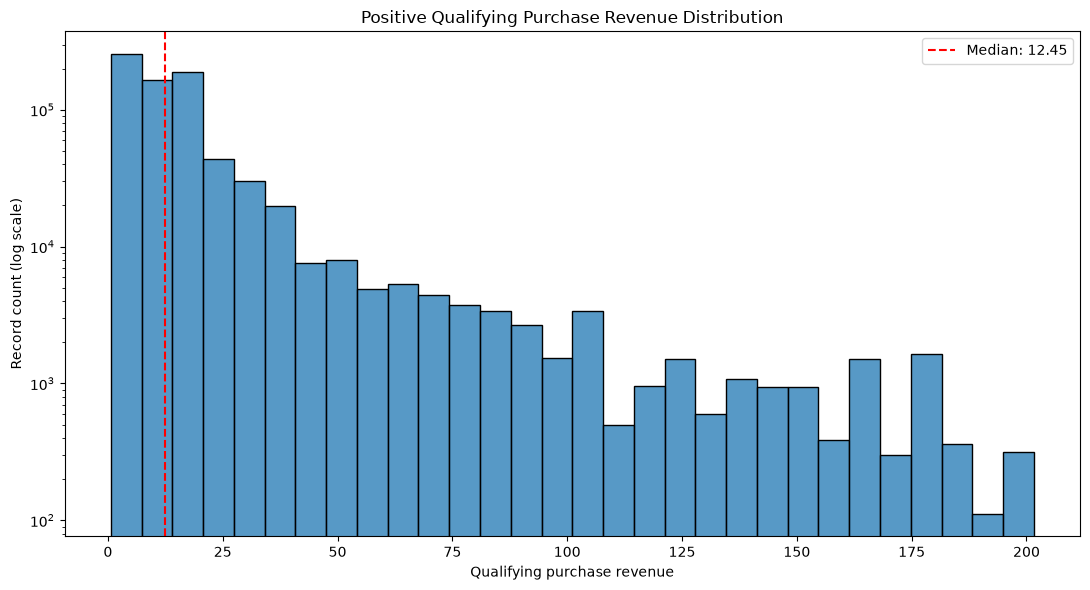

In [11]:

# Zero versus positive qualifying purchase revenue

revenue = df["qualifying_purchase_revenue"]

zero_count = (revenue == 0).sum()
positive_revenue = revenue[revenue > 0]

# 1. Revenue eligibility distribution

revenue_status = pd.DataFrame({
    "record_count": [
        zero_count,
        len(positive_revenue)
    ]
}, index=["Zero revenue", "Positive revenue"])

revenue_status["percentage"] = (
    revenue_status["record_count"] / len(df) * 100
)

print("REVENUE ELIGIBILITY DISTRIBUTION")
display(revenue_status.round(2))


# 2. Positive revenue descriptive statistics

print("\nPOSITIVE REVENUE STATISTICS")

positive_summary = positive_revenue.describe().to_frame(
    name="value"
)

positive_summary.loc["skewness"] = positive_revenue.skew()
positive_summary.loc["kurtosis"] = positive_revenue.kurtosis()

display(positive_summary.round(2))


# 3. Histogram bin counts — central 98%

lower_limit = positive_revenue.quantile(0.01)
upper_limit = positive_revenue.quantile(0.99)

hist_counts, bin_edges = np.histogram(
    positive_revenue,
    bins=30,
    range=(lower_limit, upper_limit)
)

histogram_summary = pd.DataFrame({
    "bin_start": bin_edges[:-1],
    "bin_end": bin_edges[1:],
    "record_count": hist_counts
})

histogram_summary["percentage_of_all_positive_records"] = (
    histogram_summary["record_count"]
    / len(positive_revenue) * 100
)

print("\nPOSITIVE REVENUE HISTOGRAM — CENTRAL 98%")
print(histogram_summary.round(2).to_string(index=False))


# 4. Histogram range information

below_range = (positive_revenue < lower_limit).sum()
above_range = (positive_revenue > upper_limit).sum()

print("\nHISTOGRAM RANGE INFORMATION")
print(f"Lower boundary (1st percentile): {lower_limit:.2f}")
print(f"Upper boundary (99th percentile): {upper_limit:.2f}")
print(f"Records below range: {below_range:,}")
print(f"Records above range: {above_range:,}")


# 5. Generate histogram visualization

plt.figure(figsize=(11, 6))

sns.histplot(
    positive_revenue,
    bins=30,
    binrange=(lower_limit, upper_limit)
)

plt.yscale("log")

plt.axvline(
    positive_revenue.median(),
    color="red",
    linestyle="--",
    label=f"Median: {positive_revenue.median():.2f}"
)

plt.title("Positive Qualifying Purchase Revenue Distribution")
plt.xlabel("Qualifying purchase revenue")
plt.ylabel("Record count (log scale)")
plt.legend()
plt.tight_layout()
plt.show()


QUANTITY STATISTICS


,value
count,"1,033,036.00"
mean,10.08
std,175.20
min,"-80,995.00"
25%,1.00
50%,3.00
75%,10.00
max,"80,995.00"
skewness,4.09
kurtosis,"151,283.09"



QUANTITY SIGN DISTRIBUTION


,record_count,percentage
Negative,22496,2.18
Zero,0,0.00
Positive,1010540,97.82



POSITIVE QUANTITIES
 bin_start  bin_end  record_count  percentage_of_group
      1.00     4.57        574697                56.87
      4.57     8.13        135512                13.41
      8.13    11.70         45966                 4.55
     11.70    15.27        122579                12.13
     15.27    18.83         11749                 1.16
     18.83    22.40          9758                 0.97
     22.40    25.97         55929                 5.53
     25.97    29.53           781                 0.08
     29.53    33.10          5147                 0.51
     33.10    36.67          7601                 0.75
     36.67    40.23          2111                 0.21
     40.23    43.80           230                 0.02
     43.80    47.37           197                 0.02
     47.37    50.93         13881                 1.37
     50.93    54.50           173                 0.02
     54.50    58.07           141                 0.01
     58.07    61.63          1478           

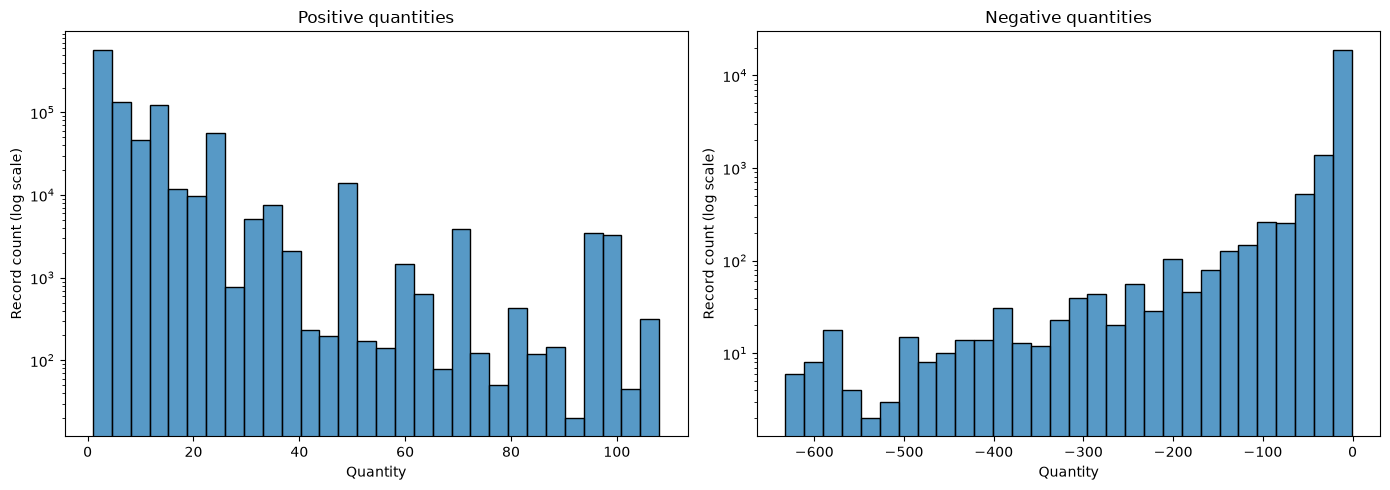

In [12]:

# Quantity distribution diagnostics

quantity = df["Quantity"]

# 1. Descriptive statistics

print("QUANTITY STATISTICS")

quantity_summary = quantity.describe().to_frame(name="value")
quantity_summary.loc["skewness"] = quantity.skew()
quantity_summary.loc["kurtosis"] = quantity.kurtosis()

display(quantity_summary.round(2))


# 2. Negative, zero, and positive observations

print("\nQUANTITY SIGN DISTRIBUTION")

quantity_status = pd.DataFrame({
    "record_count": [
        (quantity < 0).sum(),
        (quantity == 0).sum(),
        (quantity > 0).sum()
    ]
}, index=["Negative", "Zero", "Positive"])

quantity_status["percentage"] = (
    quantity_status["record_count"] / len(quantity) * 100
)

display(quantity_status.round(2))


# 3. Positive and negative quantity distributions separately

for label, values in [
    ("Positive quantities", quantity[quantity > 0]),
    ("Negative quantities", quantity[quantity < 0])
]:

    print(f"\n{label.upper()}")

    lower_limit = values.quantile(0.01)
    upper_limit = values.quantile(0.99)

    hist_counts, bin_edges = np.histogram(
        values,
        bins=30,
        range=(lower_limit, upper_limit)
    )

    histogram_summary = pd.DataFrame({
        "bin_start": bin_edges[:-1],
        "bin_end": bin_edges[1:],
        "record_count": hist_counts
    })

    histogram_summary["percentage_of_group"] = (
        histogram_summary["record_count"] / len(values) * 100
    )

    print(histogram_summary.round(2).to_string(index=False))

    print(f"\nLower boundary: {lower_limit:.2f}")
    print(f"Upper boundary: {upper_limit:.2f}")
    print(f"Records below range: {(values < lower_limit).sum():,}")
    print(f"Records above range: {(values > upper_limit).sum():,}")


# 4. Visualizations saved locally

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, label, values in [
    (axes[0], "Positive quantities", quantity[quantity > 0]),
    (axes[1], "Negative quantities", quantity[quantity < 0])
]:

    lower_limit = values.quantile(0.01)
    upper_limit = values.quantile(0.99)

    sns.histplot(
        values,
        bins=30,
        binrange=(lower_limit, upper_limit),
        ax=ax
    )

    ax.set_yscale("log")
    ax.set_title(label)
    ax.set_xlabel("Quantity")
    ax.set_ylabel("Record count (log scale)")

plt.tight_layout()
plt.show()


PRICE STATISTICS


,value
count,"1,033,036.00"
mean,4.61
std,122.40
min,"-53,594.36"
25%,1.25
50%,2.10
75%,4.15
max,"38,970.00"
skewness,-78.98
kurtosis,"78,532.76"



PRICE SIGN DISTRIBUTION


,record_count,percentage
Negative,5,0.00
Zero,6014,0.58
Positive,1027017,99.42



POSITIVE PRICES
 bin_start  bin_end  record_count  percentage_of_group
      0.29     0.90        191002                18.60
      0.90     1.52        138001                13.44
      1.52     2.13        201911                19.66
      2.13     2.74         68495                 6.67
      2.74     3.36         86076                 8.38
      3.36     3.97         59715                 5.81
      3.97     4.58         50569                 4.92
      4.58     5.19         47539                 4.63
      5.19     5.81         11495                 1.12
      5.81     6.42         31529                 3.07
      6.42     7.03         13382                 1.30
      7.03     7.65         12030                 1.17
      7.65     8.26         20175                 1.96
      8.26     8.87         21964                 2.14
      8.87     9.48          2638                 0.26
      9.48    10.10         12554                 1.22
     10.10    10.71          1585               

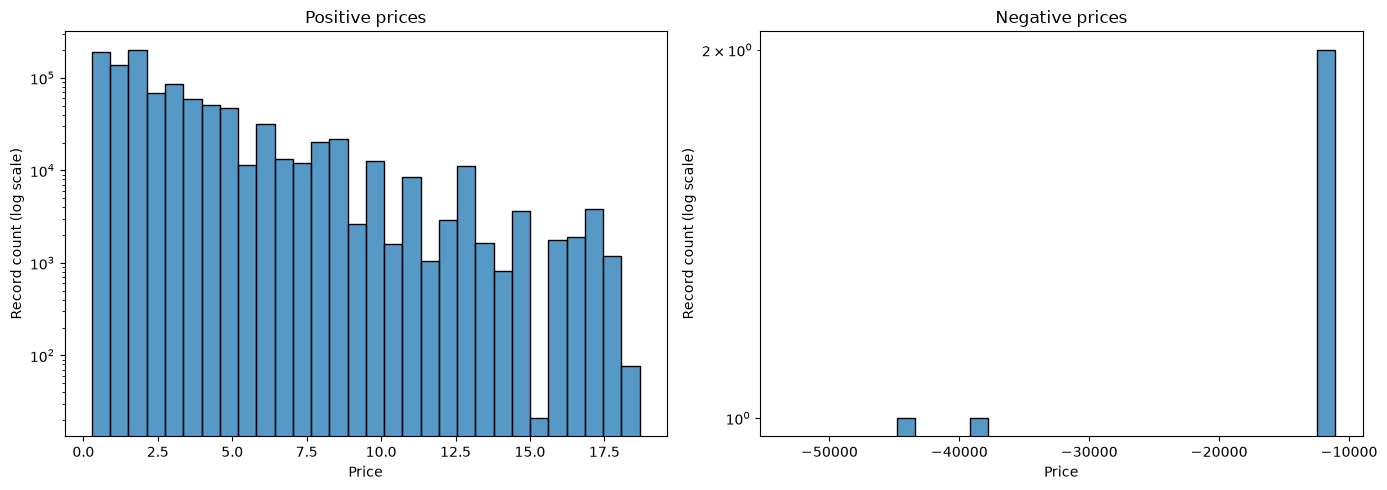

In [13]:

# Price distribution diagnostics

price = df["Price"]

# 1. Descriptive statistics

print("PRICE STATISTICS")

price_summary = price.describe().to_frame(name="value")
price_summary.loc["skewness"] = price.skew()
price_summary.loc["kurtosis"] = price.kurtosis()

display(price_summary.round(2))


# 2. Negative, zero, and positive price distribution

print("\nPRICE SIGN DISTRIBUTION")

price_status = pd.DataFrame({
    "record_count": [
        (price < 0).sum(),
        (price == 0).sum(),
        (price > 0).sum()
    ]
}, index=["Negative", "Zero", "Positive"])

price_status["percentage"] = (
    price_status["record_count"] / len(price) * 100
)

display(price_status.round(2))


# 3. Positive and negative price distributions separately

for label, values in [
    ("Positive prices", price[price > 0]),
    ("Negative prices", price[price < 0])
]:

    print(f"\n{label.upper()}")

    lower_limit = values.quantile(0.01)
    upper_limit = values.quantile(0.99)

    hist_counts, bin_edges = np.histogram(
        values,
        bins=30,
        range=(lower_limit, upper_limit)
    )

    histogram_summary = pd.DataFrame({
        "bin_start": bin_edges[:-1],
        "bin_end": bin_edges[1:],
        "record_count": hist_counts
    })

    histogram_summary["percentage_of_group"] = (
        histogram_summary["record_count"] / len(values) * 100
    )

    print(histogram_summary.round(2).to_string(index=False))

    print(f"\nLower boundary: {lower_limit:.2f}")
    print(f"Upper boundary: {upper_limit:.2f}")
    print(f"Records below range: {(values < lower_limit).sum():,}")
    print(f"Records above range: {(values > upper_limit).sum():,}")


# 4. Visualizations

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, label, values in [
    (axes[0], "Positive prices", price[price > 0]),
    (axes[1], "Negative prices", price[price < 0])
]:

    lower_limit = values.quantile(0.01)
    upper_limit = values.quantile(0.99)

    sns.histplot(
        values,
        bins=30,
        binrange=(lower_limit, upper_limit),
        ax=ax
    )

    ax.set_yscale("log")
    ax.set_title(label)
    ax.set_xlabel("Price")
    ax.set_ylabel("Record count (log scale)")

plt.tight_layout()
plt.show()


In [14]:

# Inspect all negative-price records

negative_price_records = df.loc[
    df["Price"] < 0,
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "Price",
        "Customer ID",
        "Country",
        "transaction_category",
        "zero_price_category",
        "merchandise_revenue_treatment",
        "line_value",
        "merchandise_revenue",
        "qualifying_purchase_revenue"
    ]
].sort_values("Price")

print(f"Negative-price records: {len(negative_price_records)}")

display(negative_price_records.to_string(index=False))


Negative-price records: 5


'Invoice StockCode     Description  Quantity         InvoiceDate      Price  Customer ID        Country transaction_category zero_price_category merchandise_revenue_treatment  line_value  merchandise_revenue  qualifying_purchase_revenue\nA506401         B Adjust bad debt         1 2010-04-29 13:36:00 -53,594.36          NaN United Kingdom  bad_debt_adjustment      not_zero_price                      separate  -53,594.36                 0.00                         0.00\nA516228         B Adjust bad debt         1 2010-07-19 11:24:00 -44,031.79          NaN United Kingdom  bad_debt_adjustment      not_zero_price                      separate  -44,031.79                 0.00                         0.00\nA528059         B Adjust bad debt         1 2010-10-20 12:04:00 -38,925.87          NaN United Kingdom  bad_debt_adjustment      not_zero_price                      separate  -38,925.87                 0.00                         0.00\nA563186         B Adjust bad debt         1 2011-08

In [15]:

# Zero-price transaction classification

zero_price_records = df[df["Price"] == 0].copy()

print(f"Zero-price records: {len(zero_price_records):,}")

print("\nZERO-PRICE CATEGORY BREAKDOWN")

zero_price_breakdown = (
    zero_price_records
    .groupby(
        ["zero_price_category", "transaction_category"],
        dropna=False
    )
    .agg(
        record_count=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("record_count", ascending=False)
)

zero_price_breakdown["percentage"] = (
    zero_price_breakdown["record_count"]
    / len(zero_price_records) * 100
)

display(zero_price_breakdown.round(2))


print("\nZERO-PRICE REVENUE TREATMENT")

display(
    zero_price_records[
        [
            "zero_price_category",
            "merchandise_revenue_treatment",
            "transaction_category"
        ]
    ]
    .value_counts(dropna=False)
    .rename("record_count")
    .reset_index()
)


Zero-price records: 6,014

ZERO-PRICE CATEGORY BREAKDOWN


,zero_price_category,transaction_category,record_count,unique_invoices,unique_customers,total_quantity,percentage
0,negative_zero_price,operational_adjustment_candidate,3393,3393,0,-569314,56.42
3,positive_zero_price_anonymous,zero_price_activity,2532,1908,0,228801,42.10
6,positive_zero_price_identified_customer,zero_price_activity,61,52,43,14736,1.01
1,positive_zero_price_anonymous,delivery_charge,18,18,0,7105,0.30
4,positive_zero_price_identified_customer,manual_transaction,7,7,7,7,0.12
5,positive_zero_price_identified_customer,test_transaction_candidate,2,2,2,10,0.03
2,positive_zero_price_anonymous,packing_charge,1,1,0,100,0.02



ZERO-PRICE REVENUE TREATMENT


,zero_price_category,merchandise_revenue_treatment,transaction_category,record_count
0,negative_zero_price,exclude,operational_adjustment_candidate,3393
1,positive_zero_price_anonymous,exclude,zero_price_activity,2532
2,positive_zero_price_identified_customer,exclude,zero_price_activity,61
3,positive_zero_price_anonymous,separate,delivery_charge,18
4,positive_zero_price_identified_customer,separate,manual_transaction,7
5,positive_zero_price_identified_customer,exclude,test_transaction_candidate,2
6,positive_zero_price_anonymous,separate,packing_charge,1


POSITIVE-QUANTITY, POSITIVE-PRICE RECORDS
Record count: 1,007,914

CORRELATION


,Quantity,Price,line_value
Quantity,1.00,-0.00,0.81
Price,-0.00,1.00,0.25
line_value,0.81,0.25,1.00



SPEARMAN CORRELATION


,Quantity,Price,line_value
Quantity,1.00,-0.43,0.68
Price,-0.43,1.00,0.31
line_value,0.68,0.31,1.00



PRICE STATISTICS BY QUANTITY GROUP


,record_count,median_price,mean_price,median_quantity,median_line_value,percentage
quantity_group,,,,,,
1,277336,3.29,7.38,1.00,3.29,27.52
2-5,318398,2.95,3.96,3.00,8.25,31.59
6-10,157159,2.08,2.59,6.00,16.50,15.59
11-20,144891,1.25,1.69,12.00,15.00,14.38
21-50,86171,0.85,1.28,24.00,20.40,8.55
51-100,13808,1.25,1.60,84.00,101.76,1.37
>100,10151,1.04,1.35,192.00,201.60,1.01


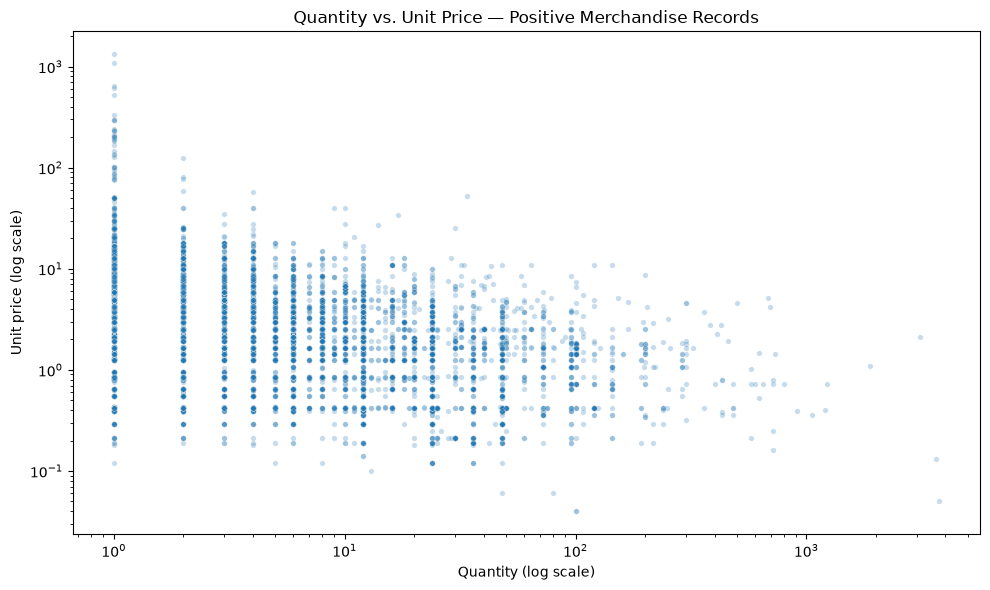

In [16]:

# Quantity and unit price relationship
# Focus on records with positive quantity and positive price

merchandise_records = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

print("POSITIVE-QUANTITY, POSITIVE-PRICE RECORDS")
print(f"Record count: {len(merchandise_records):,}")

# 1. Correlation

print("\nCORRELATION")

correlation = merchandise_records[
    ["Quantity", "Price", "line_value"]
].corr(method="pearson")

display(correlation.round(4))


# 2. Spearman correlation

print("\nSPEARMAN CORRELATION")

spearman_correlation = merchandise_records[
    ["Quantity", "Price", "line_value"]
].corr(method="spearman")

display(spearman_correlation.round(4))


# 3. Quantity groups and price statistics

print("\nPRICE STATISTICS BY QUANTITY GROUP")

merchandise_records["quantity_group"] = pd.cut(
    merchandise_records["Quantity"],
    bins=[0, 1, 5, 10, 20, 50, 100, np.inf],
    labels=[
        "1",
        "2-5",
        "6-10",
        "11-20",
        "21-50",
        "51-100",
        ">100"
    ]
)

quantity_price_summary = (
    merchandise_records
    .groupby("quantity_group", observed=False)
    .agg(
        record_count=("Price", "size"),
        median_price=("Price", "median"),
        mean_price=("Price", "mean"),
        median_quantity=("Quantity", "median"),
        median_line_value=("line_value", "median")
    )
)

quantity_price_summary["percentage"] = (
    quantity_price_summary["record_count"]
    / len(merchandise_records) * 100
)

display(quantity_price_summary.round(2))


# 4. Visualize the relationship using a sample

plot_sample = merchandise_records.sample(
    n=min(20000, len(merchandise_records)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_sample,
    x="Quantity",
    y="Price",
    alpha=0.25,
    s=15
)

plt.xscale("log")
plt.yscale("log")
plt.title("Quantity vs. Unit Price — Positive Merchandise Records")
plt.xlabel("Quantity (log scale)")
plt.ylabel("Unit price (log scale)")
plt.tight_layout()
plt.show()


QUANTITY-PRICE DENSITY TABLE
Number of sampled records in each combination


price_range,<0.50,0.50-1,1-2,2-3,3-5,5-10,10-20,20-50,50-100,>100
quantity_range,,,,,,,,,,
1,120,484,1051,1016,1178,1076,440,87,11,29
2,90,263,704,575,541,775,141,18,3,1
3-5,121,340,727,525,982,439,107,10,1,0
6-10,99,308,1000,1084,402,179,30,3,0,0
11-20,318,616,1298,374,150,71,20,3,0,0
21-50,587,453,412,159,93,29,5,1,1,0
51-100,41,39,127,30,25,7,1,0,0,0
101-500,44,29,56,13,10,3,2,0,0,0
>500,8,8,4,1,1,1,0,0,0,0



QUANTITY-PRICE DENSITY — PERCENTAGE


price_range,<0.50,0.50-1,1-2,2-3,3-5,5-10,10-20,20-50,50-100,>100
quantity_range,,,,,,,,,,
1,0.60,2.42,5.26,5.08,5.89,5.38,2.20,0.43,0.06,0.14
2,0.45,1.32,3.52,2.88,2.70,3.88,0.70,0.09,0.02,0.00
3-5,0.60,1.70,3.64,2.62,4.91,2.20,0.53,0.05,0.00,0.00
6-10,0.50,1.54,5.00,5.42,2.01,0.90,0.15,0.02,0.00,0.00
11-20,1.59,3.08,6.49,1.87,0.75,0.36,0.10,0.02,0.00,0.00
21-50,2.94,2.26,2.06,0.80,0.46,0.14,0.02,0.00,0.00,0.00
51-100,0.20,0.19,0.64,0.15,0.12,0.03,0.00,0.00,0.00,0.00
101-500,0.22,0.14,0.28,0.06,0.05,0.02,0.01,0.00,0.00,0.00
>500,0.04,0.04,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00



TOP 15 QUANTITY-PRICE COMBINATIONS


'quantity_range price_range  record_count  percentage\n         11-20         1-2          1298        6.49\n             1         3-5          1178        5.89\n          6-10         2-3          1084        5.42\n             1        5-10          1076        5.38\n             1         1-2          1051        5.26\n             1         2-3          1016        5.08\n          6-10         1-2          1000        5.00\n           3-5         3-5           982        4.91\n             2        5-10           775        3.88\n           3-5         1-2           727        3.64\n             2         1-2           704        3.52\n         11-20      0.50-1           616        3.08\n         21-50       <0.50           587        2.94\n             2         2-3           575        2.88\n             2         3-5           541        2.70'


SAMPLE CORRELATION


,Quantity,Price,line_value
Quantity,1.00,-0.02,0.58
Price,-0.02,1.00,0.21
line_value,0.58,0.21,1.00



SAMPLE SIZE
Records plotted: 20,000


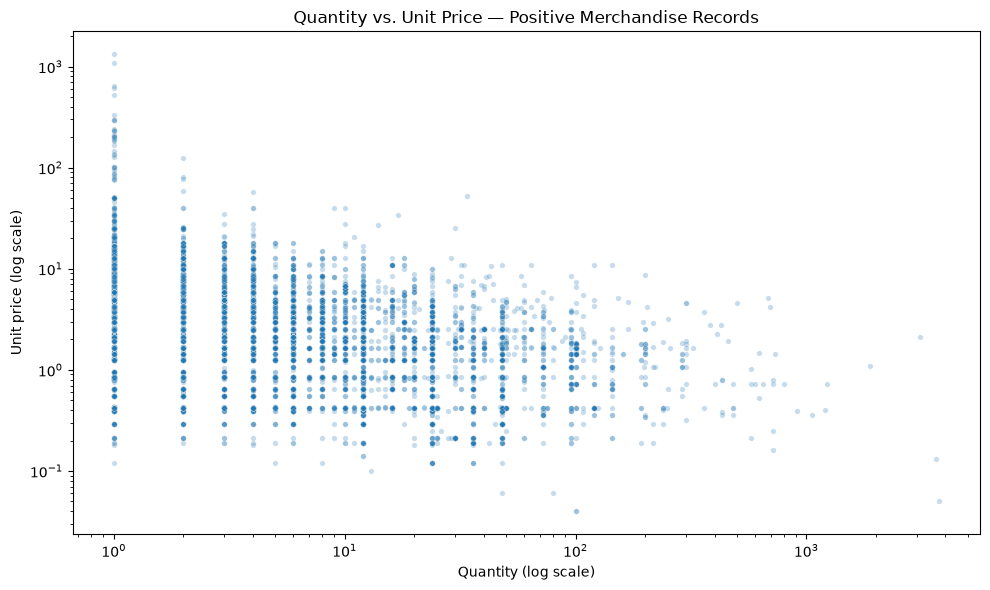

In [17]:

# Quantity vs. unit price: text-based density summary

# Use the same sample as the scatter plot
plot_sample = merchandise_records.sample(
    n=min(20000, len(merchandise_records)),
    random_state=42
).copy()

# 1. Define logarithmic bins for quantity and price
quantity_edges = [0, 1, 2, 5, 10, 20, 50, 100, 500, np.inf]
price_edges = [0, 0.5, 1, 2, 3, 5, 10, 20, 50, 100, np.inf]

quantity_labels = [
    "1", "2", "3-5", "6-10", "11-20",
    "21-50", "51-100", "101-500", ">500"
]

price_labels = [
    "<0.50", "0.50-1", "1-2", "2-3", "3-5",
    "5-10", "10-20", "20-50", "50-100", ">100"
]

plot_sample["quantity_range"] = pd.cut(
    plot_sample["Quantity"],
    bins=quantity_edges,
    labels=quantity_labels,
    right=True
)

plot_sample["price_range"] = pd.cut(
    plot_sample["Price"],
    bins=price_edges,
    labels=price_labels,
    right=True
)

# 2. Create a quantity-price density table
density_table = pd.crosstab(
    plot_sample["quantity_range"],
    plot_sample["price_range"],
    dropna=False
)

print("QUANTITY-PRICE DENSITY TABLE")
print("Number of sampled records in each combination")
display(density_table)

# 3. Convert counts into percentages
density_percentage = (
    density_table / len(plot_sample) * 100
)

print("\nQUANTITY-PRICE DENSITY — PERCENTAGE")
display(density_percentage.round(2))

# 4. Identify the most populated combinations
top_combinations = (
    plot_sample
    .groupby(
        ["quantity_range", "price_range"],
        observed=True
    )
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
    .head(15)
)

top_combinations["percentage"] = (
    top_combinations["record_count"] / len(plot_sample) * 100
)

print("\nTOP 15 QUANTITY-PRICE COMBINATIONS")
display(top_combinations.round(2).to_string(index=False))

# 5. Correlation statistics for the sample
print("\nSAMPLE CORRELATION")
display(
    plot_sample[
        ["Quantity", "Price", "line_value"]
    ].corr().round(4)
)

print("\nSAMPLE SIZE")
print(f"Records plotted: {len(plot_sample):,}")

# 6. Generate the scatter plot locally
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_sample,
    x="Quantity",
    y="Price",
    alpha=0.25,
    s=15
)

plt.xscale("log")
plt.yscale("log")
plt.title("Quantity vs. Unit Price — Positive Merchandise Records")
plt.xlabel("Quantity (log scale)")
plt.ylabel("Unit price (log scale)")
plt.tight_layout()
plt.show()


In [20]:

# Product-level quantity and unit price relationships
# With explicit handling of constant and insufficient data

product_data = merchandise_records[
    ["StockCode_normalized", "Description_normalized", "Quantity", "Price"]
].copy()


# 1. Calculate product-level correlations safely

def calculate_product_correlations(group):

    result = {
        "record_count": len(group),
        "unique_descriptions": group["Description_normalized"].nunique(),
        "unique_quantities": group["Quantity"].nunique(),
        "unique_prices": group["Price"].nunique(),
        "pearson_correlation": np.nan,
        "spearman_correlation": np.nan
    }

    # Correlations require at least two observations
    # and variation in both variables
    if (
        len(group) >= 2
        and group["Quantity"].nunique() > 1
        and group["Price"].nunique() > 1
    ):
        result["pearson_correlation"] = group["Quantity"].corr(
            group["Price"], method="pearson"
        )

        result["spearman_correlation"] = group["Quantity"].corr(
            group["Price"], method="spearman"
        )

    return pd.Series(result)


product_correlations = (
    product_data
    .groupby("StockCode_normalized")
    .apply(calculate_product_correlations)
    .reset_index()
)


# 2. Apply minimum record threshold

eligible_products = product_correlations[
    product_correlations["record_count"] >= 30
].copy()

valid_correlations = eligible_products.dropna(
    subset=["spearman_correlation"]
).copy()

print("PRODUCT-LEVEL ANALYSIS COVERAGE")
print(f"Total unique products: {len(product_correlations):,}")
print(f"Products with at least 30 records: {len(eligible_products):,}")
print(f"Products with valid Spearman correlation: {len(valid_correlations):,}")
print(
    "Eligible products with undefined correlation: "
    f"{len(eligible_products) - len(valid_correlations):,}"
)


# 3. Identify reasons for undefined correlations

print("\nVARIATION CHECK")

variation_summary = pd.DataFrame({
    "condition": [
        "Constant quantity",
        "Constant price",
        "Both quantity and price constant",
        "Both variables have variation"
    ],
    "product_count": [
        (
            eligible_products["unique_quantities"] == 1
        ).sum(),
        (
            eligible_products["unique_prices"] == 1
        ).sum(),
        (
            (eligible_products["unique_quantities"] == 1) &
            (eligible_products["unique_prices"] == 1)
        ).sum(),
        (
            (eligible_products["unique_quantities"] > 1) &
            (eligible_products["unique_prices"] > 1)
        ).sum()
    ]
})

display(variation_summary)


# 4. Product-level Spearman correlation distribution

print("\nPRODUCT-LEVEL SPEARMAN CORRELATION DISTRIBUTION")

display(
    valid_correlations["spearman_correlation"]
    .describe()
    .to_frame(name="value")
    .round(3)
)


# 5. Correlation direction

correlation_direction = pd.Series({
    "Negative": (
        valid_correlations["spearman_correlation"] < 0
    ).sum(),
    "Approximately zero": (
        valid_correlations["spearman_correlation"].between(-0.05, 0.05)
    ).sum(),
    "Positive": (
        valid_correlations["spearman_correlation"] > 0
    ).sum()
})

direction_summary = correlation_direction.to_frame(
    name="product_count"
)

direction_summary["percentage"] = (
    direction_summary["product_count"]
    / len(valid_correlations) * 100
)

print("\nPRODUCT-LEVEL CORRELATION DIRECTION")
display(direction_summary.round(2))


# 6. Strongest negative relationships

print("\n20 PRODUCTS WITH STRONGEST NEGATIVE SPEARMAN CORRELATIONS")

display(
    valid_correlations
    .sort_values("spearman_correlation")
    .head(20)
    .round(3)
    .to_string(index=False)
)


# 7. Strongest positive relationships

print("\n20 PRODUCTS WITH STRONGEST POSITIVE SPEARMAN CORRELATIONS")

display(
    valid_correlations
    .sort_values("spearman_correlation", ascending=False)
    .head(20)
    .round(3)
    .to_string(index=False)
)


# 8. Most frequently occurring products

print("\n50 MOST FREQUENT PRODUCTS")

most_frequent_products = (
    product_data
    .groupby(
        ["StockCode_normalized", "Description_normalized"],
        dropna=False
    )
    .agg(
        record_count=("Quantity", "size"),
        median_quantity=("Quantity", "median"),
        median_price=("Price", "median"),
        mean_price=("Price", "mean")
    )
    .sort_values("record_count", ascending=False)
    .head(50)
    .reset_index()
)

display(most_frequent_products.round(2).to_string(index=False))


PRODUCT-LEVEL ANALYSIS COVERAGE
Total unique products: 4,745
Products with at least 30 records: 3,455
Products with valid Spearman correlation: 3,418
Eligible products with undefined correlation: 37

VARIATION CHECK


,condition,product_count
0,Constant quantity,5
1,Constant price,33
2,Both quantity and price constant,1
3,Both variables have variation,3418



PRODUCT-LEVEL SPEARMAN CORRELATION DISTRIBUTION


,value
count,"3,418.00"
mean,-0.46
std,0.21
min,-1.00
25%,-0.59
50%,-0.49
75%,-0.36
max,0.52



PRODUCT-LEVEL CORRELATION DIRECTION


,product_count,percentage
Negative,3280,95.96
Approximately zero,68,1.99
Positive,138,4.04


... (2 outputs left out)


20 PRODUCTS WITH STRONGEST POSITIVE SPEARMAN CORRELATIONS


'StockCode_normalized  record_count  unique_descriptions  unique_quantities  unique_prices  pearson_correlation  spearman_correlation\n              90200B         84.00                 1.00               7.00           4.00                 0.28                  0.52\n              90200E         91.00                 1.00               9.00           5.00                -0.46                  0.51\n              90018A         56.00                 1.00               4.00           4.00                 0.26                  0.48\n              90129D         34.00                 1.00               6.00           4.00                 0.39                  0.46\n              90198A         84.00                 1.00               7.00           4.00                 0.20                  0.44\n               90166         31.00                 1.00               3.00           4.00                 0.27                  0.42\n              47592A        101.00                 2.00      


50 MOST FREQUENT PRODUCTS


"StockCode_normalized             Description_normalized  record_count  median_quantity  median_price  mean_price\n              85123A WHITE HANGING HEART T-LIGHT HOLDER          5601             6.00          2.95        3.14\n               22423           REGENCY CAKESTAND 3 TIER          3950             2.00         12.75       14.19\n              85099B            JUMBO BAG RED RETROSPOT          3312            10.00          2.08        2.38\n               84879      ASSORTED COLOUR BIRD ORNAMENT          2848            16.00          1.69        1.86\n               47566                      PARTY BUNTING          2705             4.00          4.95        5.72\n               20727             LUNCH BAG BLACK SKULL.          2402             7.00          1.65        2.02\n               22383              LUNCH BAG SUKI DESIGN          2401            10.00          1.65        2.08\n               21232     STRAWBERRY CERAMIC TRINKET BOX          2352            12.00 

QUANTITY AND LINE VALUE CORRELATION


,Quantity,Price,line_value
Quantity,1.00,-0.00,0.81
Price,-0.00,1.00,0.25
line_value,0.81,0.25,1.00



SPEARMAN CORRELATION


,Quantity,Price,line_value
Quantity,1.00,-0.43,0.68
Price,-0.43,1.00,0.31
line_value,0.68,0.31,1.00



LINE VALUE STATISTICS BY QUANTITY GROUP


,record_count,median_line_value,mean_line_value,q25_line_value,q75_line_value,median_quantity,median_price,percentage
quantity_group,,,,,,,,
1,277336,3.29,7.38,1.65,5.91,1.00,3.29,27.52
2-5,318398,8.25,10.92,3.90,15.00,3.00,2.95,31.59
6-10,157159,16.50,18.80,11.41,20.40,6.00,2.08,15.59
11-20,144891,15.00,22.29,10.20,25.00,12.00,1.25,14.38
21-50,86171,20.40,39.28,10.50,46.80,24.00,0.85,8.55
51-100,13808,101.76,128.67,61.20,165.00,84.00,1.25,1.37
>100,10151,201.60,355.47,96.00,360.00,192.00,1.04,1.01


... (4 outputs left out)


SAMPLE QUANTITY-LINE VALUE DENSITY


line_value_range,<=1,1-5,5-10,10-20,20-50,50-100,100-250,250-500,500-1000,>1000
quantity_range,,,,,,,,,,
1,604,3245,1076,440,87,11,20,4,3,2
2,90,1217,866,775,150,9,4,0,0,0
3-5,14,799,737,1267,368,62,5,0,0,0
6-10,1,158,559,1607,662,103,12,3,0,0
11-20,0,80,389,1512,670,152,45,1,1,0
21-50,0,21,114,634,575,251,129,13,2,1
51-100,0,3,0,5,39,63,137,19,4,0
101-500,0,0,0,0,9,35,53,34,17,9
>500,0,0,0,0,0,0,4,8,6,5



SAMPLE SIZE
Records plotted: 20,000

SAMPLE PEARSON CORRELATION


,Quantity,Price,line_value
Quantity,1.00,-0.02,0.58
Price,-0.02,1.00,0.21
line_value,0.58,0.21,1.00


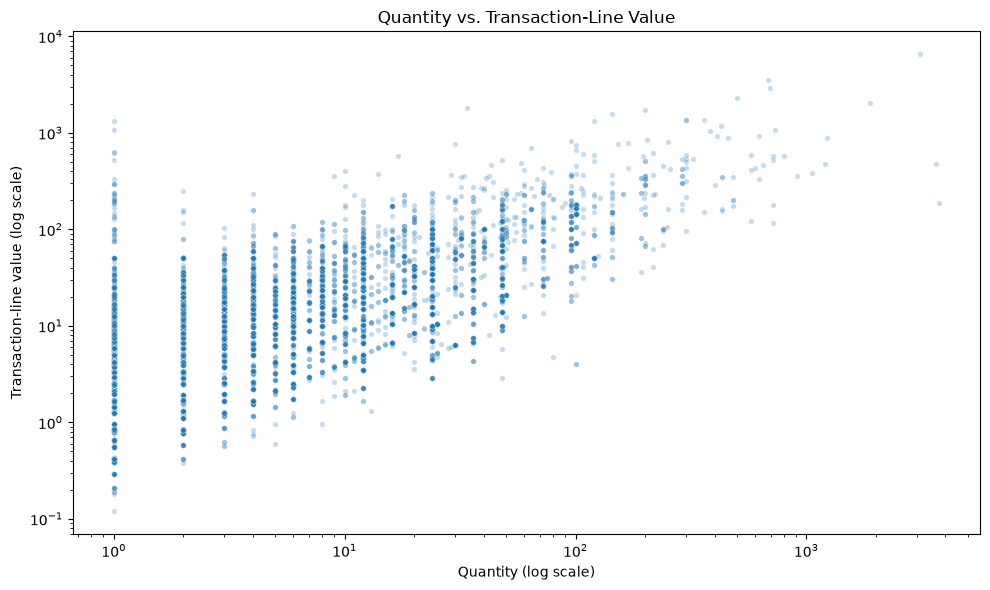

In [21]:

# Quantity versus transaction-line value

# Use positive-quantity, positive-price merchandise records
quantity_value_data = merchandise_records[
    ["Quantity", "Price", "line_value"]
].copy()


# 1. Correlation analysis

print("QUANTITY AND LINE VALUE CORRELATION")

correlation_results = quantity_value_data[
    ["Quantity", "Price", "line_value"]
].corr(method="pearson")

display(correlation_results.round(4))


print("\nSPEARMAN CORRELATION")

spearman_results = quantity_value_data[
    ["Quantity", "Price", "line_value"]
].corr(method="spearman")

display(spearman_results.round(4))


# 2. Line-value statistics by quantity group

print("\nLINE VALUE STATISTICS BY QUANTITY GROUP")

quantity_value_data["quantity_group"] = pd.cut(
    quantity_value_data["Quantity"],
    bins=[0, 1, 5, 10, 20, 50, 100, np.inf],
    labels=[
        "1",
        "2-5",
        "6-10",
        "11-20",
        "21-50",
        "51-100",
        ">100"
    ]
)

line_value_summary = (
    quantity_value_data
    .groupby("quantity_group", observed=False)
    .agg(
        record_count=("line_value", "size"),
        median_line_value=("line_value", "median"),
        mean_line_value=("line_value", "mean"),
        q25_line_value=("line_value", lambda x: x.quantile(0.25)),
        q75_line_value=("line_value", lambda x: x.quantile(0.75)),
        median_quantity=("Quantity", "median"),
        median_price=("Price", "median")
    )
)

line_value_summary["percentage"] = (
    line_value_summary["record_count"]
    / len(quantity_value_data) * 100
)

display(line_value_summary.round(2))


# 3. Text-based distribution of line values

print("\nLINE VALUE DISTRIBUTION")

line_value_edges = [
    0, 1, 5, 10, 20, 50, 100, 250, 500, 1000, np.inf
]

line_value_labels = [
    "<=1",
    "1-5",
    "5-10",
    "10-20",
    "20-50",
    "50-100",
    "100-250",
    "250-500",
    "500-1000",
    ">1000"
]

quantity_value_data["line_value_range"] = pd.cut(
    quantity_value_data["line_value"],
    bins=line_value_edges,
    labels=line_value_labels,
    include_lowest=True
)

line_value_distribution = pd.crosstab(
    quantity_value_data["quantity_group"],
    quantity_value_data["line_value_range"],
    dropna=False
)

print("LINE VALUE COUNTS BY QUANTITY GROUP")
display(line_value_distribution)

line_value_percentage = (
    line_value_distribution
    .div(line_value_distribution.sum(axis=1), axis=0) * 100
)

print("\nLINE VALUE PERCENTAGE WITHIN EACH QUANTITY GROUP")
display(line_value_percentage.round(2))


# 4. Sample scatter plot and text-based density summary

plot_sample = quantity_value_data.sample(
    n=min(20000, len(quantity_value_data)),
    random_state=42
).copy()

quantity_edges = [0, 1, 2, 5, 10, 20, 50, 100, 500, np.inf]

quantity_labels = [
    "1", "2", "3-5", "6-10", "11-20",
    "21-50", "51-100", "101-500", ">500"
]

plot_sample["quantity_range"] = pd.cut(
    plot_sample["Quantity"],
    bins=quantity_edges,
    labels=quantity_labels
)

plot_sample["line_value_range"] = pd.cut(
    plot_sample["line_value"],
    bins=line_value_edges,
    labels=line_value_labels,
    include_lowest=True
)

density_table = pd.crosstab(
    plot_sample["quantity_range"],
    plot_sample["line_value_range"]
)

print("\nSAMPLE QUANTITY-LINE VALUE DENSITY")
display(density_table)

print("\nSAMPLE SIZE")
print(f"Records plotted: {len(plot_sample):,}")

print("\nSAMPLE PEARSON CORRELATION")
display(
    plot_sample[
        ["Quantity", "Price", "line_value"]
    ].corr().round(4)
)


# 5. Visualization

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_sample,
    x="Quantity",
    y="line_value",
    alpha=0.25,
    s=15
)

plt.xscale("log")
plt.yscale("log")
plt.title("Quantity vs. Transaction-Line Value")
plt.xlabel("Quantity (log scale)")
plt.ylabel("Transaction-line value (log scale)")
plt.tight_layout()
plt.show()


MONTHLY TRANSACTION AND REVENUE SUMMARY


'YearMonth  transaction_lines  unique_invoices  identified_customers  merchandise_revenue  qualifying_purchase_revenue  average_line_value  transaction_lines_mom_pct  unique_invoices_mom_pct  identified_customers_mom_pct  merchandise_revenue_mom_pct  qualifying_purchase_revenue_mom_pct                           period_status\n  2009-12              44722             2330                  1045           778,561.45                   677,917.07               17.81                       <NA>                      NaN                           NaN                          NaN                                  NaN              Complete observation month\n  2010-01              31234             1633                   786           604,830.31                   533,712.98               19.93                     -30.16                   -29.91                        -24.78                       -22.31                               -21.27              Complete observation month\n  2010-02         


HIGHEST MONTHS BY METRIC
transaction_lines: 2011-11 (83,343.00)
unique_invoices: 2010-11 (3,669.00)
merchandise_revenue: 2011-11 (1,423,318.71)
qualifying_purchase_revenue: 2010-11 (1,155,978.39)

LOWEST MONTHS BY METRIC — EXCLUDING PARTIAL DECEMBER 2011
transaction_lines: 2011-02 (27,479.00)
unique_invoices: 2011-02 (1,393.00)
merchandise_revenue: 2011-04 (482,153.60)
qualifying_purchase_revenue: 2011-02 (442,293.59)


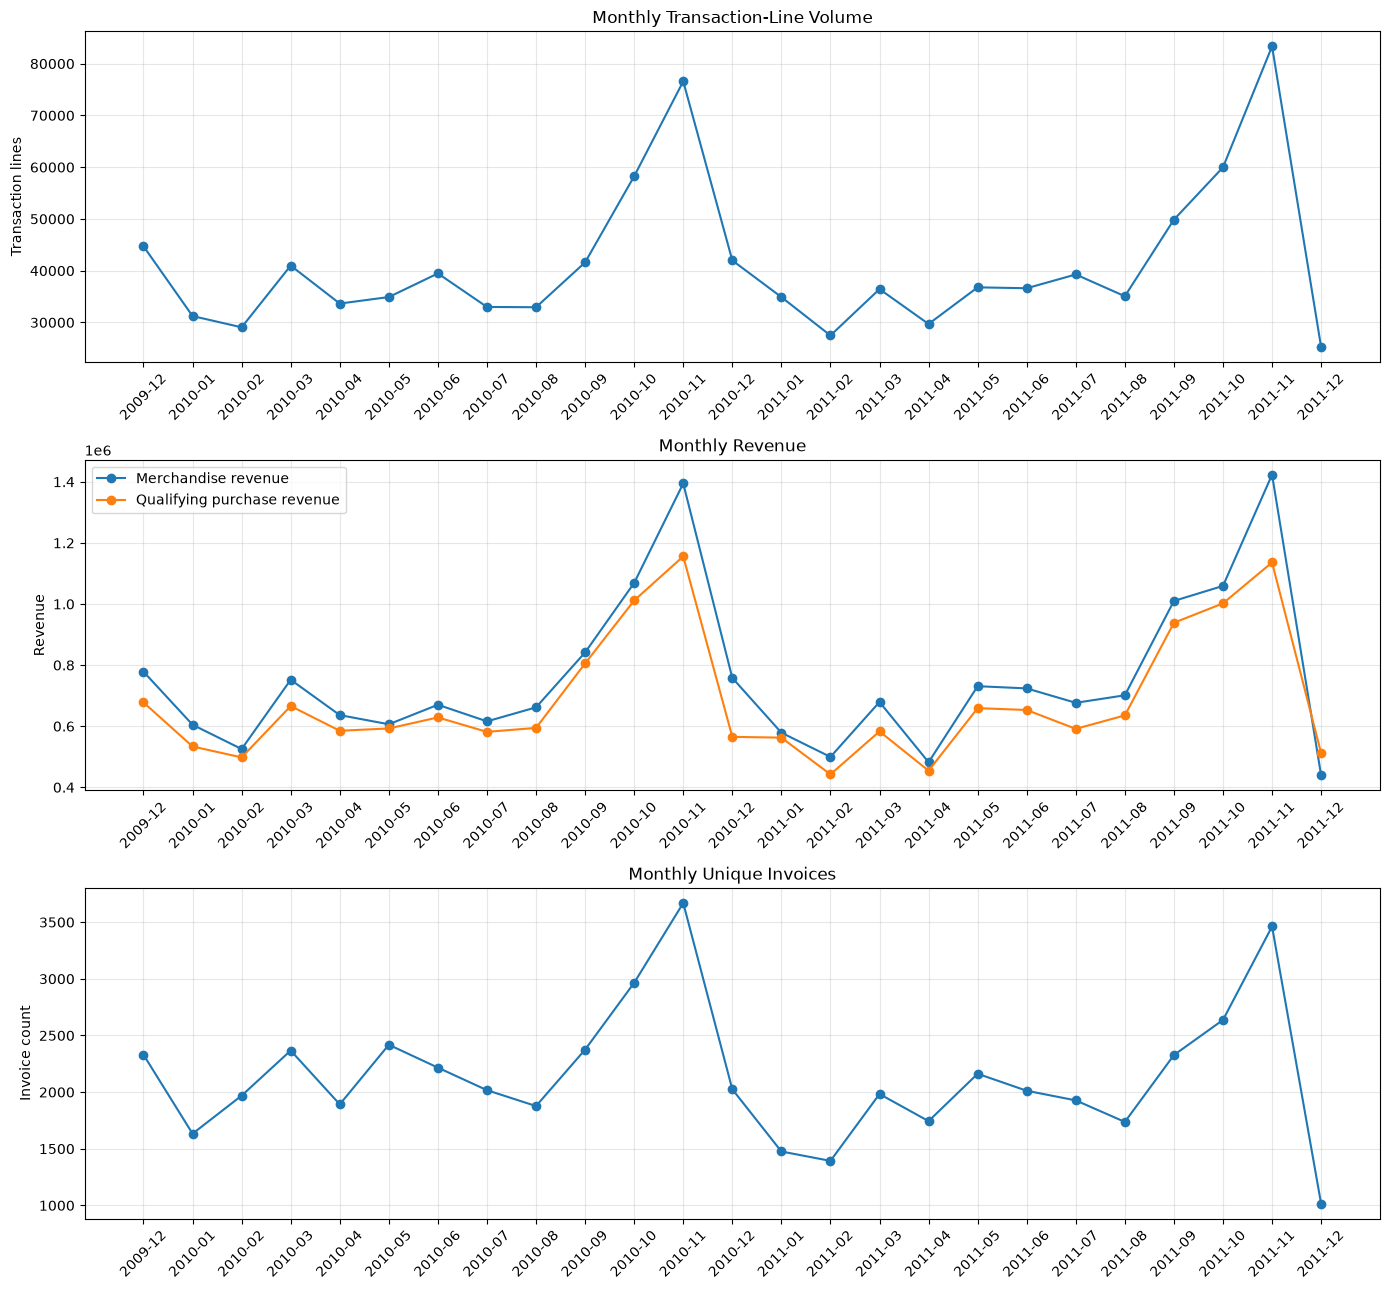

In [22]:

# Monthly transaction activity and revenue analysis

# 1. Aggregate monthly metrics

monthly_summary = (
    df
    .groupby("YearMonth", observed=True)
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        identified_customers=("Customer ID", "nunique"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=(
            "qualifying_purchase_revenue", "sum"
        ),
        average_line_value=("line_value", "mean")
    )
    .reset_index()
)

monthly_summary["YearMonth"] = (
    monthly_summary["YearMonth"].astype(str)
)

# 2. Calculate month-over-month changes

monthly_metrics = [
    "transaction_lines",
    "unique_invoices",
    "identified_customers",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]

for column in monthly_metrics:
    monthly_summary[f"{column}_mom_pct"] = (
        monthly_summary[column].pct_change() * 100
    )

# 3. Identify incomplete final month

monthly_summary["period_status"] = "Complete observation month"
monthly_summary.loc[
    monthly_summary["YearMonth"] == "2011-12",
    "period_status"
] = "Partial month — data through December 9"

print("MONTHLY TRANSACTION AND REVENUE SUMMARY")

display(
    monthly_summary.round(2).to_string(index=False)
)


# 4. Identify highest and lowest months

print("\nHIGHEST MONTHS BY METRIC")

for column in [
    "transaction_lines",
    "unique_invoices",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]:
    highest = monthly_summary.loc[
        monthly_summary[column].idxmax()
    ]

    print(
        f"{column}: {highest['YearMonth']} "
        f"({highest[column]:,.2f})"
    )


print("\nLOWEST MONTHS BY METRIC — EXCLUDING PARTIAL DECEMBER 2011")

complete_months = monthly_summary[
    monthly_summary["YearMonth"] != "2011-12"
]

for column in [
    "transaction_lines",
    "unique_invoices",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]:
    lowest = complete_months.loc[
        complete_months[column].idxmin()
    ]

    print(
        f"{column}: {lowest['YearMonth']} "
        f"({lowest[column]:,.2f})"
    )


# 5. Visualize monthly activity and revenue

fig, axes = plt.subplots(3, 1, figsize=(14, 13))

# Transaction lines
axes[0].plot(
    monthly_summary["YearMonth"],
    monthly_summary["transaction_lines"],
    marker="o"
)
axes[0].set_title("Monthly Transaction-Line Volume")
axes[0].set_ylabel("Transaction lines")

# Merchandise revenue
axes[1].plot(
    monthly_summary["YearMonth"],
    monthly_summary["merchandise_revenue"],
    marker="o",
    label="Merchandise revenue"
)
axes[1].plot(
    monthly_summary["YearMonth"],
    monthly_summary["qualifying_purchase_revenue"],
    marker="o",
    label="Qualifying purchase revenue"
)
axes[1].set_title("Monthly Revenue")
axes[1].set_ylabel("Revenue")
axes[1].legend()

# Unique invoices
axes[2].plot(
    monthly_summary["YearMonth"],
    monthly_summary["unique_invoices"],
    marker="o"
)
axes[2].set_title("Monthly Unique Invoices")
axes[2].set_ylabel("Invoice count")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [23]:
# Compare monthly metrics between 2010 and 2011
yoy_comparison = monthly_summary.copy()

yoy_comparison["YearMonth"] = pd.PeriodIndex(
    yoy_comparison["YearMonth"],
    freq="M"
)

yoy_comparison["year"] = yoy_comparison["YearMonth"].dt.year
yoy_comparison["month"] = yoy_comparison["YearMonth"].dt.month

yoy_metrics = [
    "transaction_lines",
    "unique_invoices",
    "identified_customers",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]

yoy_pivot = yoy_comparison.pivot(
    index="month",
    columns="year",
    values=yoy_metrics
)

print("YEAR-OVER-YEAR MONTHLY COMPARISON")
display(yoy_pivot.round(2))

YEAR-OVER-YEAR MONTHLY COMPARISON


transaction_lines               unique_invoices              \
year               2009   2010   2011            2009  2010  2011   
month                                                               
1                   NaN  31234  34900             NaN  1633  1476   
2                   NaN  29058  27479             NaN  1969  1393   
3                   NaN  40985  36439             NaN  2367  1983   
4                   NaN  33647  29701             NaN  1892  1744   
5                   NaN  34908  36782             NaN  2418  2162   
6                   NaN  39469  36609             NaN  2216  2012   
7                   NaN  32992  39267             NaN  2017  1927   
8                   NaN  32939  35064             NaN  1877  1737   
9                   NaN  41607  49861             NaN  2375  2327   
10                  NaN  58249  59969             NaN  2965  2637   
11                  NaN  76584  83343             NaN  3669  3462   
12                44722  41981  25247            2330  2025  1015   

      identified_customers             merchandise_revenue               \
year                  2009  2010  2011                2009         2010   
month                                                                     
1                      NaN   786   783                 NaN   604,830.31   
2                      NaN   807   798                 NaN   525,351.26   
3                      NaN  1111  1020                 NaN   752,144.68   
4                      NaN   998   899                 NaN   636,426.30   
5                      NaN  1062  1079                 NaN   606,392.75   
6                      NaN  1095  1051                 NaN   670,277.81   
7                      NaN   988   993                 NaN   615,946.69   
8                      NaN   964   980                 NaN   661,795.29   
9                      NaN  1202  1302                 NaN   841,590.74   
10                     NaN  1577  1425                 NaN 1,069,112.56   
11                     NaN  1683  1711                 NaN 1,394,652.86   
12                    1045   948   686          778,561.45   758,167.09   

                   qualifying_purchase_revenue                            
year          2011                        2009         2010         2011  
month                                                                     
1       578,914.41                         NaN   533,712.98   562,682.91  
2       499,531.02                         NaN   497,937.58   442,293.59  
3       679,337.54                         NaN   665,973.67   583,143.85  
4       482,153.60                         NaN   585,127.43   454,440.88  
5       731,073.10                         NaN   592,734.13   659,227.49  
6       723,820.15                         NaN   628,809.40   653,114.92  
7       676,687.91                         NaN   581,487.96   591,431.29  
8       701,244.99                         NaN   594,561.17   635,371.88  
9     1,010,099.81                         NaN   805,544.81   938,625.13  
10    1,059,297.26                         NaN 1,011,571.50 1,002,199.06  
11    1,423,318.71                         NaN 1,155,978.39 1,136,121.50  
12      439,149.95                  677,917.07   565,199.56   512,070.58

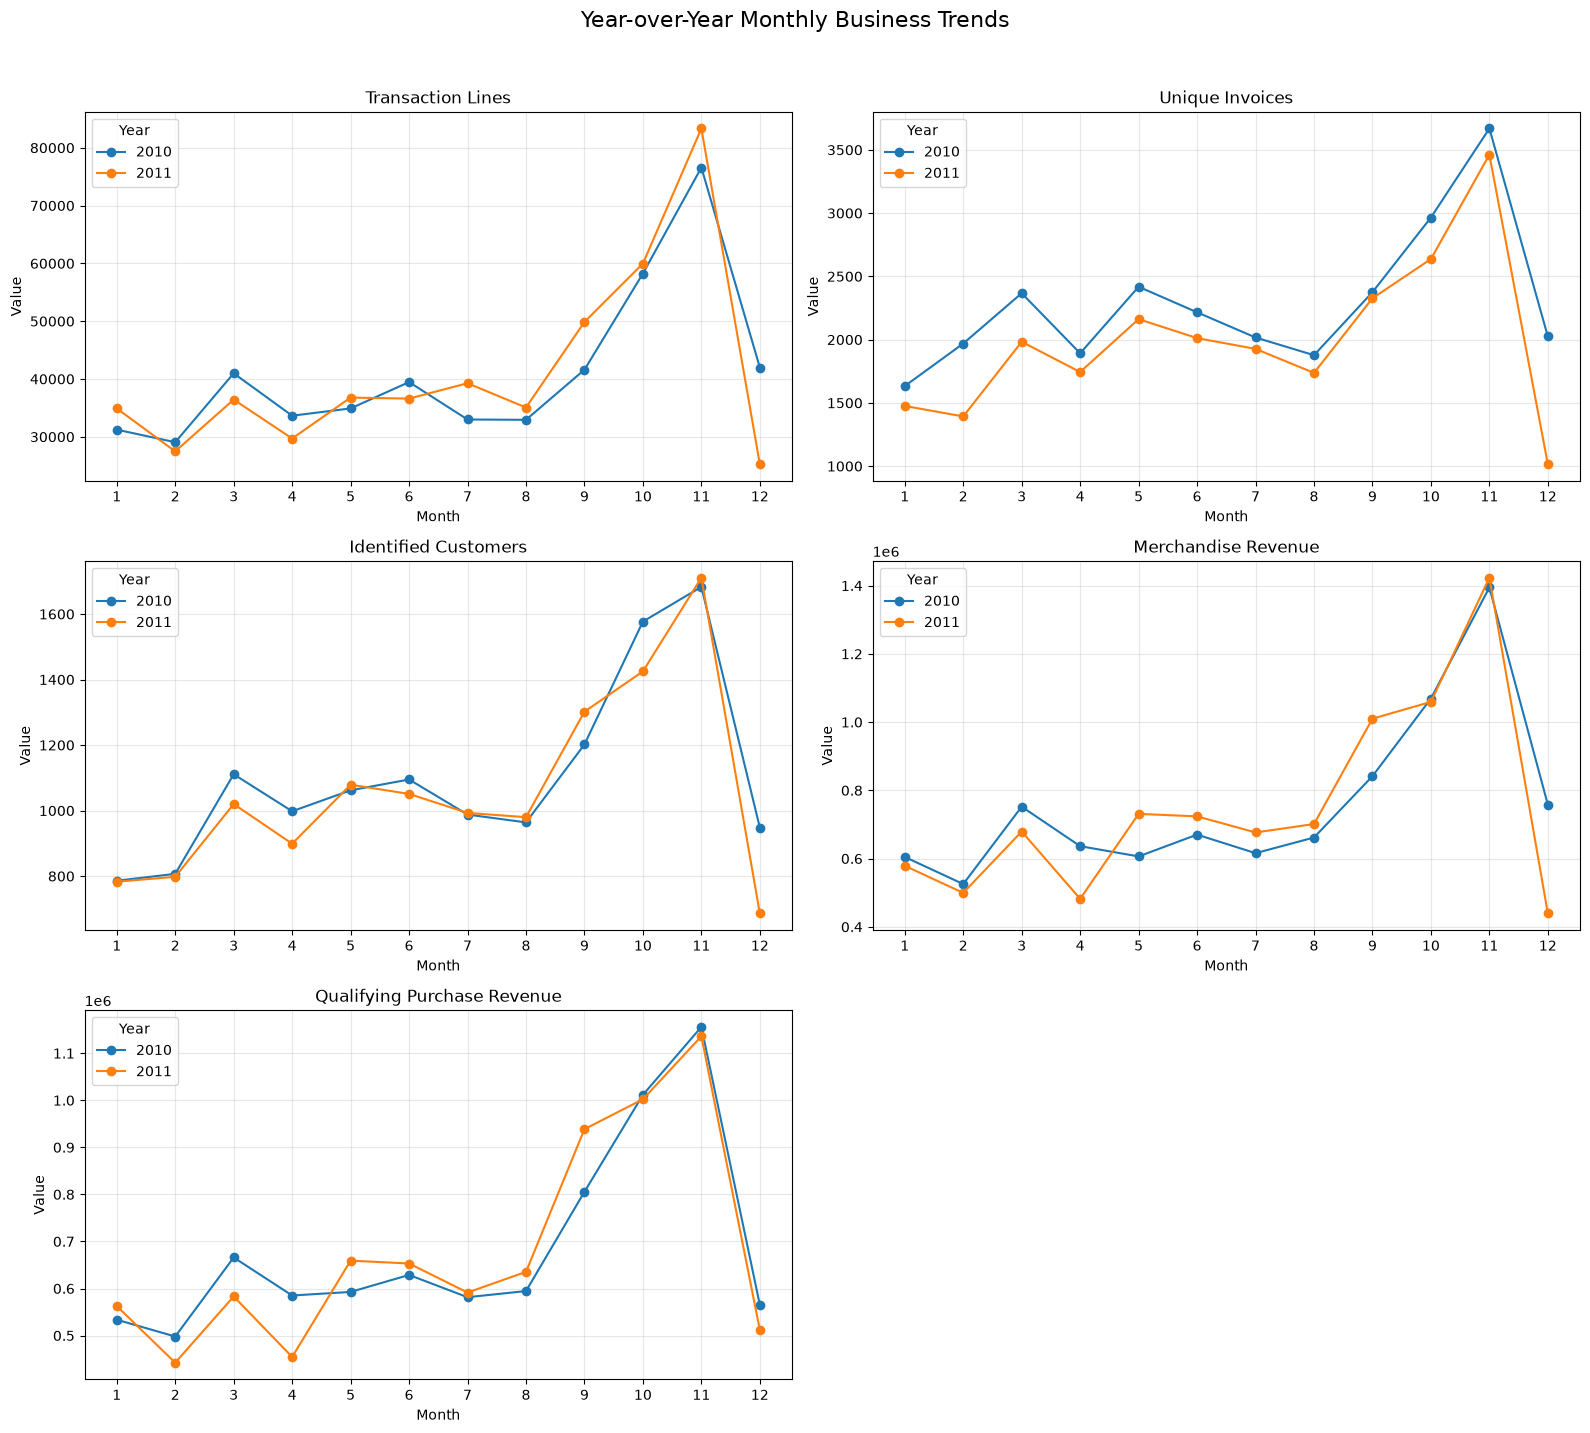

In [24]:
# Year-over-year monthly trend charts
plot_metrics = [
    ("transaction_lines", "Transaction Lines"),
    ("unique_invoices", "Unique Invoices"),
    ("identified_customers", "Identified Customers"),
    ("merchandise_revenue", "Merchandise Revenue"),
    ("qualifying_purchase_revenue", "Qualifying Purchase Revenue")
]

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()

for ax, (metric, title) in zip(axes, plot_metrics):

    for year in [2010, 2011]:
        yearly_data = yoy_comparison[
            yoy_comparison["year"] == year
        ].sort_values("month")

        ax.plot(
            yearly_data["month"],
            yearly_data[metric],
            marker="o",
            label=str(year)
        )

    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.set_ylabel("Value")
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=0.3)
    ax.legend(title="Year")

axes[-1].axis("off")

plt.suptitle(
    "Year-over-Year Monthly Business Trends",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

year,2009,2010,2011
month,,,
1,<NA>,19.13,23.64
2,<NA>,14.76,19.73
3,<NA>,17.32,18.38
4,<NA>,17.78,17.03
5,<NA>,14.44,17.01
6,<NA>,17.81,18.20
7,<NA>,16.36,20.38
8,<NA>,17.55,20.19
9,<NA>,17.52,21.43


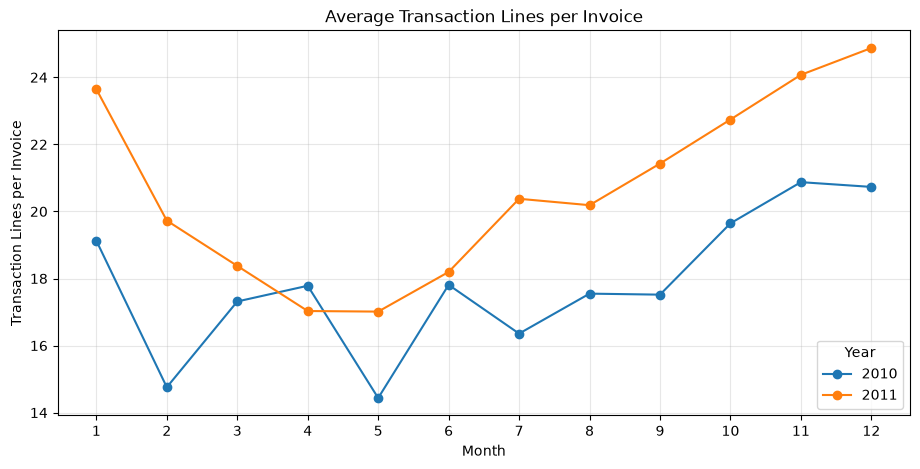

In [25]:
# Calculate average transaction lines per invoice by month
monthly_summary["lines_per_invoice"] = (
    monthly_summary["transaction_lines"]
    / monthly_summary["unique_invoices"]
)

# Compare 2010 and 2011
lines_per_invoice_comparison = yoy_comparison.copy()

lines_per_invoice_comparison["lines_per_invoice"] = (
    lines_per_invoice_comparison["transaction_lines"]
    / lines_per_invoice_comparison["unique_invoices"]
)

display(
    lines_per_invoice_comparison.pivot(
        index="month",
        columns="year",
        values="lines_per_invoice"
    ).round(2)
)

# Plot the comparison
plt.figure(figsize=(11, 5))

for year in [2010, 2011]:
    yearly_data = lines_per_invoice_comparison[
        lines_per_invoice_comparison["year"] == year
    ].sort_values("month")

    plt.plot(
        yearly_data["month"],
        yearly_data["lines_per_invoice"],
        marker="o",
        label=str(year)
    )

plt.title("Average Transaction Lines per Invoice")
plt.xlabel("Month")
plt.ylabel("Transaction Lines per Invoice")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend(title="Year")
plt.show()

DAY-OF-WEEK SUMMARY


,day_of_week,transaction_lines,unique_invoices,identified_customers,merchandise_revenue,qualifying_purchase_revenue,transaction_lines_pct,qualifying_revenue_pct
0,Monday,183699,8595,2756,"3,311,012.98","2,709,898.28",17.78,15.88
1,Tuesday,191972,10299,3040,"3,694,293.32","3,262,732.69",18.58,19.12
2,Wednesday,177445,9597,2958,"3,299,750.85","2,980,353.58",17.18,17.46
3,Thursday,196189,11335,3252,"3,904,960.64","3,687,563.25",18.99,21.61
4,Friday,150312,8505,2645,"2,932,339.85","2,658,999.68",14.55,15.58
5,Saturday,402,32,26,"9,803.05","9,803.05",0.04,0.06
6,Sunday,133017,5265,2162,"1,767,717.54","1,757,928.19",12.88,10.30


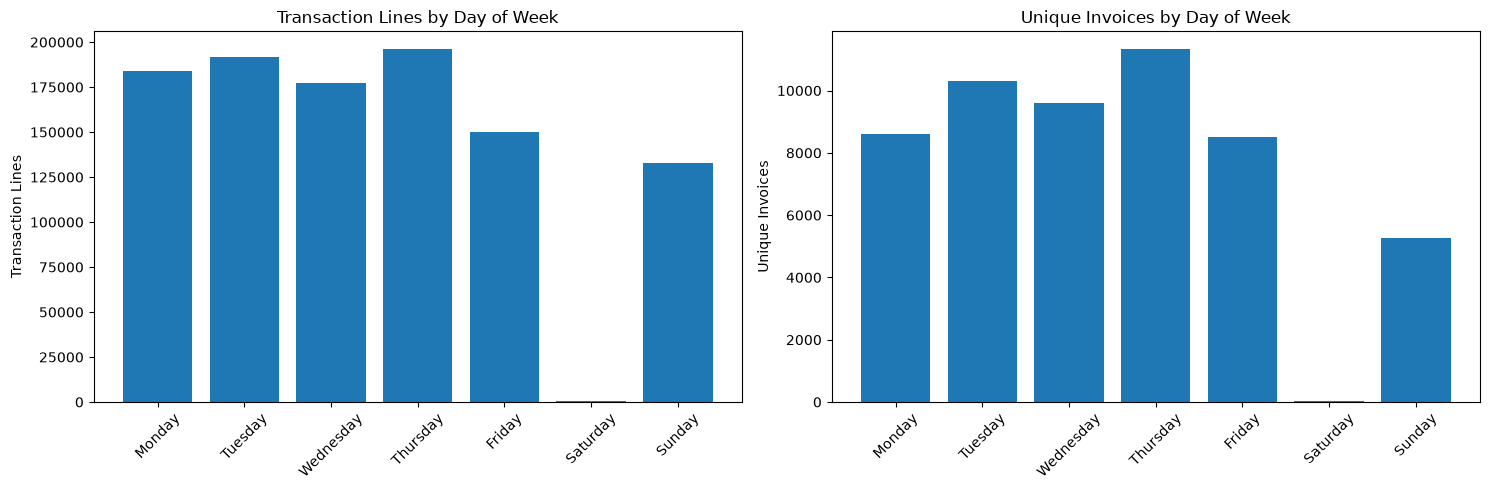

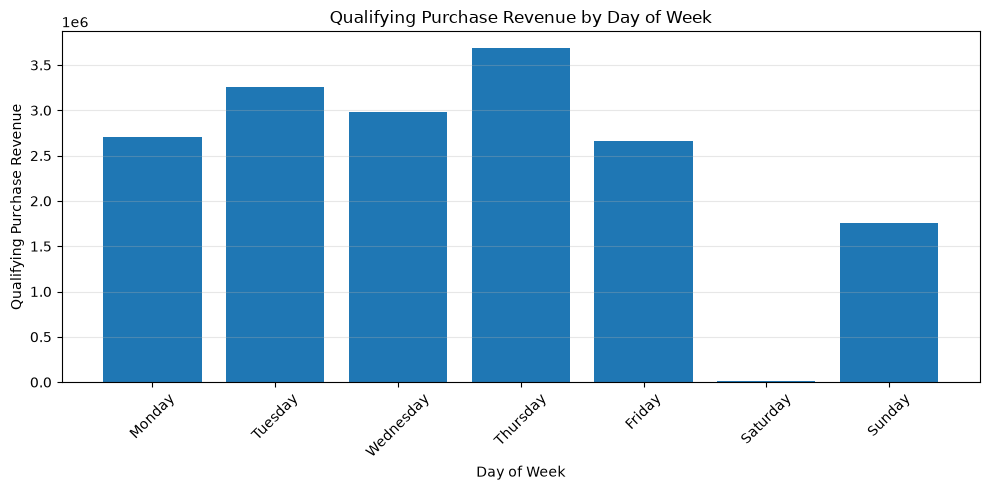

In [26]:
# Day-of-week analysis

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

df["day_of_week"] = df["InvoiceDate"].dt.day_name()

weekday_summary = (
    df.groupby("day_of_week")
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        identified_customers=("Customer ID", "nunique"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=("qualifying_purchase_revenue", "sum")
    )
    .reindex(weekday_order)
    .reset_index()
)

weekday_summary["transaction_lines_pct"] = (
    weekday_summary["transaction_lines"]
    / weekday_summary["transaction_lines"].sum() * 100
)

weekday_summary["qualifying_revenue_pct"] = (
    weekday_summary["qualifying_purchase_revenue"]
    / weekday_summary["qualifying_purchase_revenue"].sum() * 100
)

print("DAY-OF-WEEK SUMMARY")
display(weekday_summary.round(2))

# Plot transaction lines and invoices
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    weekday_summary["day_of_week"],
    weekday_summary["transaction_lines"]
)
axes[0].set_title("Transaction Lines by Day of Week")
axes[0].set_ylabel("Transaction Lines")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(
    weekday_summary["day_of_week"],
    weekday_summary["unique_invoices"]
)
axes[1].set_title("Unique Invoices by Day of Week")
axes[1].set_ylabel("Unique Invoices")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Plot qualifying purchase revenue
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_summary["day_of_week"],
    weekday_summary["qualifying_purchase_revenue"]
)

plt.title("Qualifying Purchase Revenue by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Qualifying Purchase Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

HOUR-OF-DAY SUMMARY


,hour_of_day,transaction_lines,unique_invoices,identified_customers,merchandise_revenue,qualifying_purchase_revenue,transaction_lines_pct,qualifying_revenue_pct
0,6,41,22,21,-281.35,4.25,0.00,0.00
1,7,1117,110,95,"72,738.22","75,029.57",0.11,0.44
2,8,15829,1150,772,"513,887.73","518,547.55",1.53,3.04
3,9,67120,3520,1564,"1,506,602.67","1,457,593.31",6.50,8.54
4,10,90832,6030,2203,"2,361,863.53","2,288,854.44",8.79,13.41
5,11,117515,6628,2356,"2,353,227.59","2,183,457.03",11.38,12.79
6,12,154256,8098,2753,"2,741,200.65","2,659,699.24",14.93,15.58
7,13,145596,7163,2737,"2,409,147.35","2,304,873.73",14.09,13.50
8,14,135791,6519,2514,"2,173,957.49","1,924,112.97",13.14,11.27
9,15,130840,6168,2320,"2,184,547.18","1,804,305.06",12.67,10.57



PEAK HOURS
transaction_lines: 12:00 (154,256.00)
unique_invoices: 12:00 (8,098.00)
qualifying_purchase_revenue: 12:00 (2,659,699.24)


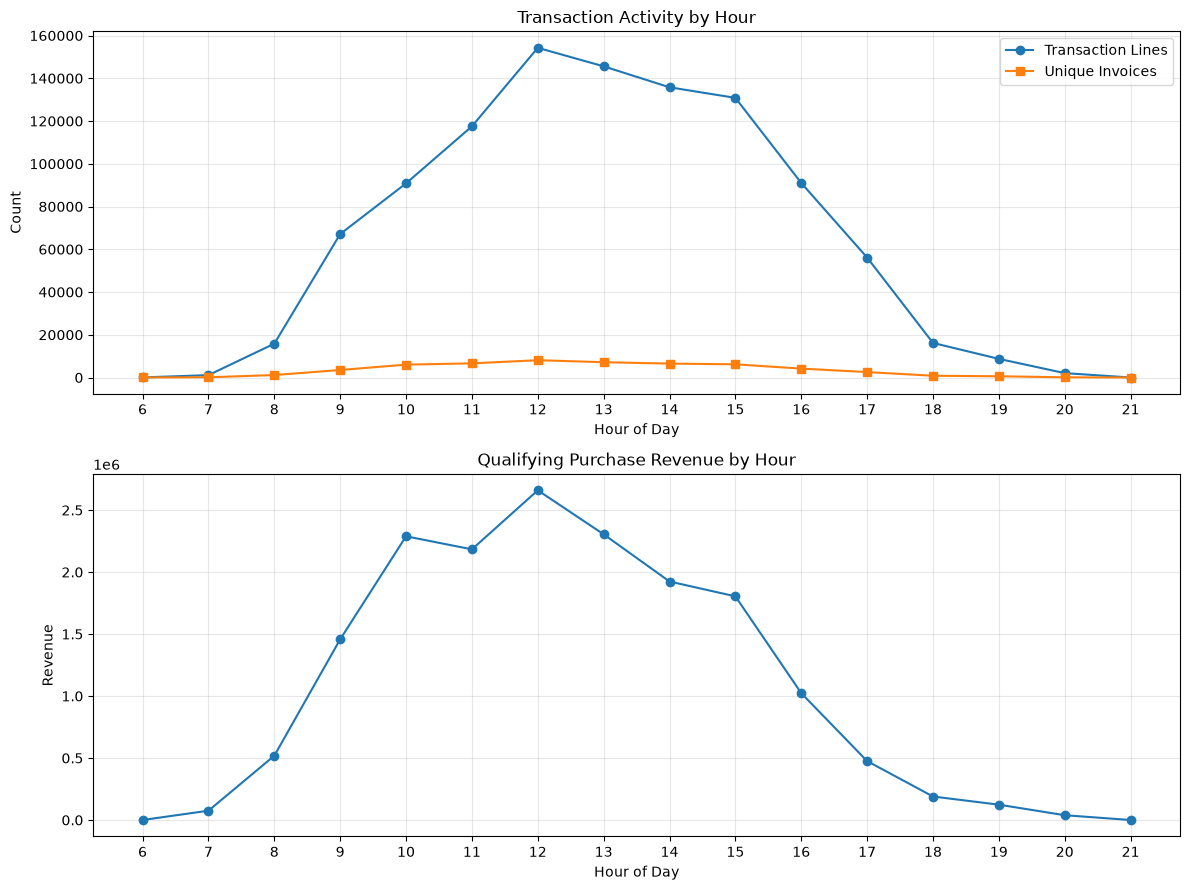

In [27]:
# Hour-of-day analysis

df["hour_of_day"] = df["InvoiceDate"].dt.hour

hourly_summary = (
    df.groupby("hour_of_day")
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        identified_customers=("Customer ID", "nunique"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=("qualifying_purchase_revenue", "sum")
    )
    .reset_index()
)

hourly_summary["transaction_lines_pct"] = (
    hourly_summary["transaction_lines"]
    / hourly_summary["transaction_lines"].sum() * 100
)

hourly_summary["qualifying_revenue_pct"] = (
    hourly_summary["qualifying_purchase_revenue"]
    / hourly_summary["qualifying_purchase_revenue"].sum() * 100
)

print("HOUR-OF-DAY SUMMARY")
display(hourly_summary.round(2))

# Identify peak hours
print("\nPEAK HOURS")

for metric in [
    "transaction_lines",
    "unique_invoices",
    "qualifying_purchase_revenue"
]:
    peak = hourly_summary.loc[hourly_summary[metric].idxmax()]

    print(
        f"{metric}: {int(peak['hour_of_day']):02d}:00 "
        f"({peak[metric]:,.2f})"
    )

# Visualize transaction activity and revenue
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

axes[0].plot(
    hourly_summary["hour_of_day"],
    hourly_summary["transaction_lines"],
    marker="o",
    label="Transaction Lines"
)

axes[0].plot(
    hourly_summary["hour_of_day"],
    hourly_summary["unique_invoices"],
    marker="s",
    label="Unique Invoices"
)

axes[0].set_title("Transaction Activity by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Count")
axes[0].set_xticks(hourly_summary["hour_of_day"])
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    hourly_summary["hour_of_day"],
    hourly_summary["qualifying_purchase_revenue"],
    marker="o"
)

axes[1].set_title("Qualifying Purchase Revenue by Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Revenue")
axes[1].set_xticks(hourly_summary["hour_of_day"])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Product-level aggregation

product_summary = (
    df.groupby("StockCode_normalized", dropna=False)
    .agg(
        description=("Description_normalized", "first"),
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        identified_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=("qualifying_purchase_revenue", "sum")
    )
    .reset_index()
)

# Top 20 products by transaction-line count
top_products_volume = (
    product_summary
    .sort_values("transaction_lines", ascending=False)
    .head(20)
)

print("TOP 20 PRODUCTS BY TRANSACTION-LINE COUNT")
display(top_products_volume.round(2))

# Top 20 products by qualifying purchase revenue
top_products_revenue = (
    product_summary
    .sort_values("qualifying_purchase_revenue", ascending=False)
    .head(20)
)

print("TOP 20 PRODUCTS BY QUALIFYING PURCHASE REVENUE")
display(top_products_revenue.round(2))

TOP 20 PRODUCTS BY TRANSACTION-LINE COUNT


,StockCode_normalized,description,transaction_lines,unique_invoices,identified_customers,total_quantity,merchandise_revenue,qualifying_purchase_revenue
4494,85123A,WHITE HANGING HEART T-LIGHT HOLDER,5752,5606,1494,94639,"251,781.63","247,203.36"
1749,22423,REGENCY CAKESTAND 3 TIER,4306,4272,1316,24696,"314,045.02","277,656.25"
4470,85099B,JUMBO BAG RED WHITE SPOTTY,4157,4102,978,94570,"180,512.16","167,920.64"
687,21212,PACK OF 72 RETRO SPOT CAKE CASES,3209,3144,1116,93774,"51,275.49","43,390.03"
288,20725,LUNCH BAG RED SPOTTY,3170,3135,845,39386,"69,722.54","59,375.10"
4207,84879,ASSORTED COLOUR BIRD ORNAMENT,2870,2829,1012,78978,"128,550.42","124,351.86"
3319,47566,PARTY BUNTING,2733,2702,894,27113,"147,079.73","103,283.38"
705,21232,STRAWBERRY CERAMIC TRINKET BOX,2666,2618,693,37194,"48,350.48","40,994.71"
1715,22383,LUNCHBAG SUKI DESIGN,2469,2431,664,24871,"42,968.55","38,007.55"
1543,22197,"POPCORN HOLDER , SMALL",2465,2421,601,77969,"78,903.62","58,267.74"


TOP 20 PRODUCTS BY QUALIFYING PURCHASE REVENUE


,StockCode_normalized,description,transaction_lines,unique_invoices,identified_customers,total_quantity,merchandise_revenue,qualifying_purchase_revenue
1749,22423,REGENCY CAKESTAND 3 TIER,4306,4272,1316,24696,"314,045.02","277,656.25"
4494,85123A,WHITE HANGING HEART T-LIGHT HOLDER,5752,5606,1494,94639,"251,781.63","247,203.36"
2912,23843,"PAPER CRAFT , LITTLE BIRDIE",2,2,1,0,0.00,"168,469.60"
4470,85099B,JUMBO BAG RED WHITE SPOTTY,4157,4102,978,94570,"180,512.16","167,920.64"
4207,84879,ASSORTED COLOUR BIRD ORNAMENT,2870,2829,1012,78978,"128,550.42","124,351.86"
3319,47566,PARTY BUNTING,2733,2702,894,27113,"147,079.73","103,283.38"
2466,23166,MEDIUM CERAMIC TOP STORAGE JAR,260,257,138,3539,"4,221.28","81,416.73"
1435,22086,PAPER CHAIN KIT 50'S CHRISTMAS,2086,2036,896,34434,"116,298.59","76,598.18"
3645,79321,CHILLI LIGHTS,1179,1172,306,15652,"79,905.13","69,084.30"
1718,22386,JUMBO BAG PINK WITH WHITE SPOTS,2294,2270,601,38955,"75,457.64","67,769.76"


In [29]:
# Investigate the unusual revenue contribution of StockCode 23843

anomalous_product = df[
    df["StockCode_normalized"] == "23843"
].copy()

investigation_columns = [
    "Invoice",
    "StockCode",
    "StockCode_normalized",
    "Description",
    "Quantity",
    "InvoiceDate",
    "Price",
    "Customer ID",
    "line_value",
    "transaction_category",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]

print("UNDERLYING TRANSACTION RECORDS")
display(
    anomalous_product[investigation_columns]
    .sort_values("InvoiceDate")
)

print("\nRECORD-LEVEL SUMMARY")
display(
    anomalous_product[
        [
            "Quantity",
            "Price",
            "line_value",
            "merchandise_revenue",
            "qualifying_purchase_revenue"
        ]
    ].sum().to_frame("total")
)

UNDERLYING TRANSACTION RECORDS


,Invoice,StockCode,StockCode_normalized,Description,Quantity,InvoiceDate,Price,Customer ID,line_value,transaction_category,merchandise_revenue,qualifying_purchase_revenue
1031554,581483,23843,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,"16,446.00","168,469.60",merchandise_candidate,"168,469.60","168,469.60"
1031555,C581484,23843,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,"16,446.00","-168,469.60",merchandise_cancellation_candidate,"-168,469.60",0.00



RECORD-LEVEL SUMMARY


,total
Quantity,0.00
Price,4.16
line_value,0.00
merchandise_revenue,0.00
qualifying_purchase_revenue,"168,469.60"


In [30]:
# Top 20 products by net merchandise revenue

top_products_net_revenue = (
    product_summary
    .sort_values("merchandise_revenue", ascending=False)
    .head(20)
)

print("TOP 20 PRODUCTS BY NET MERCHANDISE REVENUE")
display(top_products_net_revenue.round(2))

TOP 20 PRODUCTS BY NET MERCHANDISE REVENUE


,StockCode_normalized,description,transaction_lines,unique_invoices,identified_customers,total_quantity,merchandise_revenue,qualifying_purchase_revenue
1749,22423,REGENCY CAKESTAND 3 TIER,4306,4272,1316,24696,"314,045.02","277,656.25"
4494,85123A,WHITE HANGING HEART T-LIGHT HOLDER,5752,5606,1494,94639,"251,781.63","247,203.36"
4470,85099B,JUMBO BAG RED WHITE SPOTTY,4157,4102,978,94570,"180,512.16","167,920.64"
3319,47566,PARTY BUNTING,2733,2702,894,27113,"147,079.73","103,283.38"
4207,84879,ASSORTED COLOUR BIRD ORNAMENT,2870,2829,1012,78978,"128,550.42","124,351.86"
1435,22086,PAPER CHAIN KIT 50'S CHRISTMAS,2086,2036,896,34434,"116,298.59","76,598.18"
3645,79321,CHILLI LIGHTS,1179,1172,306,15652,"79,905.13","69,084.30"
1543,22197,"POPCORN HOLDER , SMALL",2465,2421,601,77969,"78,903.62","58,267.74"
1718,22386,JUMBO BAG PINK WITH WHITE SPOTS,2294,2270,601,38955,"75,457.64","67,769.76"
3807,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,792,767,300,21401,"70,969.95","55,880.17"


In [31]:
# Product revenue concentration

product_concentration = product_summary.sort_values(
    "merchandise_revenue",
    ascending=False
).copy()

total_net_merchandise_revenue = (
    product_concentration["merchandise_revenue"].sum()
)

product_concentration["revenue_share_pct"] = (
    product_concentration["merchandise_revenue"]
    / total_net_merchandise_revenue * 100
)

product_concentration["cumulative_revenue_share_pct"] = (
    product_concentration["revenue_share_pct"].cumsum()
)

print("TOTAL NET MERCHANDISE REVENUE:")
print(f"{total_net_merchandise_revenue:,.2f}")

print("\nPRODUCT REVENUE CONCENTRATION")

for n in [10, 20, 50, 100]:
    share = product_concentration.head(n)[
        "revenue_share_pct"
    ].sum()

    print(f"Top {n} products: {share:.2f}%")

# Number of products needed to reach revenue thresholds
for threshold in [50, 70, 80, 90]:
    required = (
        product_concentration[
            product_concentration["cumulative_revenue_share_pct"]
            < threshold
        ].shape[0] + 1
    )

    print(
        f"Products needed to reach {threshold}% "
        f"of net merchandise revenue: {required}"
    )

print("\nTOP 20 PRODUCT CONTRIBUTIONS")
display(
    product_concentration[
        [
            "StockCode_normalized",
            "description",
            "merchandise_revenue",
            "revenue_share_pct",
            "cumulative_revenue_share_pct"
        ]
    ].head(20).round(2)
)

TOTAL NET MERCHANDISE REVENUE:
18,919,878.25

PRODUCT REVENUE CONCENTRATION
Top 10 products: 7.63%
Top 20 products: 11.03%
Top 50 products: 19.07%
Top 100 products: 28.96%
Products needed to reach 50% of net merchandise revenue: 289
Products needed to reach 70% of net merchandise revenue: 674
Products needed to reach 80% of net merchandise revenue: 1036
Products needed to reach 90% of net merchandise revenue: 1684

TOP 20 PRODUCT CONTRIBUTIONS


,StockCode_normalized,description,merchandise_revenue,revenue_share_pct,cumulative_revenue_share_pct
1749,22423,REGENCY CAKESTAND 3 TIER,"314,045.02",1.66,1.66
4494,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"251,781.63",1.33,2.99
4470,85099B,JUMBO BAG RED WHITE SPOTTY,"180,512.16",0.95,3.94
3319,47566,PARTY BUNTING,"147,079.73",0.78,4.72
4207,84879,ASSORTED COLOUR BIRD ORNAMENT,"128,550.42",0.68,5.40
1435,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"116,298.59",0.61,6.02
3645,79321,CHILLI LIGHTS,"79,905.13",0.42,6.44
1543,22197,"POPCORN HOLDER , SMALL","78,903.62",0.42,6.86
1718,22386,JUMBO BAG PINK WITH WHITE SPOTS,"75,457.64",0.40,7.25
3807,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,"70,969.95",0.38,7.63


In [32]:
# Country-level analysis

country_summary = (
    df.groupby("Country")
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        identified_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=("qualifying_purchase_revenue", "sum")
    )
    .reset_index()
)

country_summary = country_summary.sort_values(
    "merchandise_revenue",
    ascending=False
)

country_summary["revenue_share_pct"] = (
    country_summary["merchandise_revenue"]
    / country_summary["merchandise_revenue"].sum() * 100
)

country_summary["cumulative_revenue_share_pct"] = (
    country_summary["revenue_share_pct"].cumsum()
)

print("COUNTRY-LEVEL SUMMARY")
display(country_summary.round(2))

print("\nTOP 10 COUNTRIES BY NET MERCHANDISE REVENUE")
display(country_summary.head(10).round(2))

COUNTRY-LEVEL SUMMARY


,Country,transaction_lines,unique_invoices,identified_customers,total_quantity,merchandise_revenue,qualifying_purchase_revenue,revenue_share_pct,cumulative_revenue_share_pct
40,United Kingdom,948321,49108,5410,8513706,"16,161,392.63","14,287,484.52",85.42,85.42
11,EIRE,17667,806,5,327431,"603,116.61","586,618.58",3.19,88.61
26,Netherlands,5137,250,23,381853,"546,095.43","549,773.41",2.89,91.49
15,Germany,17339,1095,107,221816,"374,573.51","383,289.00",1.98,93.47
14,France,14025,746,95,181572,"293,423.70","309,395.66",1.55,95.02
0,Australia,1890,117,15,103375,"166,282.15","167,800.01",0.88,95.90
36,Switzerland,3175,123,22,52256,"92,918.06","93,400.94",0.49,96.39
34,Spain,3754,188,41,44667,"84,811.56","97,766.75",0.45,96.84
35,Sweden,1362,129,19,87858,"84,345.17","86,045.14",0.45,97.29
10,Denmark,797,53,12,234764,"63,355.59","67,422.69",0.33,97.62



TOP 10 COUNTRIES BY NET MERCHANDISE REVENUE


,Country,transaction_lines,unique_invoices,identified_customers,total_quantity,merchandise_revenue,qualifying_purchase_revenue,revenue_share_pct,cumulative_revenue_share_pct
40,United Kingdom,948321,49108,5410,8513706,"16,161,392.63","14,287,484.52",85.42,85.42
11,EIRE,17667,806,5,327431,"603,116.61","586,618.58",3.19,88.61
26,Netherlands,5137,250,23,381853,"546,095.43","549,773.41",2.89,91.49
15,Germany,17339,1095,107,221816,"374,573.51","383,289.00",1.98,93.47
14,France,14025,746,95,181572,"293,423.70","309,395.66",1.55,95.02
0,Australia,1890,117,15,103375,"166,282.15","167,800.01",0.88,95.90
36,Switzerland,3175,123,22,52256,"92,918.06","93,400.94",0.49,96.39
34,Spain,3754,188,41,44667,"84,811.56","97,766.75",0.45,96.84
35,Sweden,1362,129,19,87858,"84,345.17","86,045.14",0.45,97.29
10,Denmark,797,53,12,234764,"63,355.59","67,422.69",0.33,97.62


In [33]:
# Country-level transaction efficiency metrics

country_summary["revenue_per_invoice"] = (
    country_summary["qualifying_purchase_revenue"]
    / country_summary["unique_invoices"]
)

country_summary["lines_per_invoice"] = (
    country_summary["transaction_lines"]
    / country_summary["unique_invoices"]
)

country_summary["revenue_per_transaction_line"] = (
    country_summary["qualifying_purchase_revenue"]
    / country_summary["transaction_lines"]
)

print("TOP 15 COUNTRIES BY QUALIFYING REVENUE PER INVOICE")

display(
    country_summary[
        [
            "Country",
            "unique_invoices",
            "transaction_lines",
            "qualifying_purchase_revenue",
            "revenue_per_invoice",
            "lines_per_invoice",
            "revenue_per_transaction_line"
        ]
    ]
    .sort_values("revenue_per_invoice", ascending=False)
    .head(15)
    .round(2)
)

print("\nTOP 15 COUNTRIES BY INVOICE COUNT")

display(
    country_summary[
        [
            "Country",
            "unique_invoices",
            "identified_customers",
            "revenue_per_invoice",
            "lines_per_invoice"
        ]
    ]
    .sort_values("unique_invoices", ascending=False)
    .head(15)
    .round(2)
)

TOP 15 COUNTRIES BY QUALIFYING REVENUE PER INVOICE


,Country,unique_invoices,transaction_lines,qualifying_purchase_revenue,revenue_per_invoice,lines_per_invoice,revenue_per_transaction_line
26,Netherlands,250,5137,"549,773.41","2,199.09",20.55,107.02
37,Thailand,2,76,"3,070.54","1,535.27",38.00,40.40
0,Australia,117,1890,"167,800.01","1,434.19",16.15,88.78
10,Denmark,53,797,"67,422.69","1,272.13",15.04,84.60
19,Israel,11,368,"10,415.24",946.84,33.45,28.30
33,Singapore,14,346,"13,158.16",939.87,24.71,38.03
16,Greece,21,663,"18,711.19",891.01,31.57,28.22
24,Lithuania,6,154,"4,892.68",815.45,25.67,31.77
21,Japan,56,565,"43,023.91",768.28,10.09,76.15
36,Switzerland,123,3175,"93,400.94",759.36,25.81,29.42



TOP 15 COUNTRIES BY INVOICE COUNT


,Country,unique_invoices,identified_customers,revenue_per_invoice,lines_per_invoice
40,United Kingdom,49108,5410,290.94,19.31
15,Germany,1095,107,350.04,15.83
11,EIRE,806,5,727.81,21.92
14,France,746,95,414.74,18.80
26,Netherlands,250,23,"2,199.09",20.55
34,Spain,188,41,520.04,19.97
3,Belgium,183,29,311.44,16.99
35,Sweden,129,19,667.02,10.56
30,Portugal,124,24,375.88,20.39
36,Switzerland,123,22,759.36,25.81


In [34]:
# Product mix in selected countries

selected_countries = [
    "United Kingdom",
    "Netherlands",
    "Australia",
    "EIRE",
    "Germany"
]

country_product_summary = (
    df[df["Country"].isin(selected_countries)]
    .groupby(["Country", "StockCode_normalized"])
    .agg(
        description=("Description_normalized", "first"),
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        total_quantity=("Quantity", "sum"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=("qualifying_purchase_revenue", "sum")
    )
    .reset_index()
)

for country in selected_countries:

    print(f"\nTOP 10 PRODUCTS IN {country.upper()}")

    country_top_products = (
        country_product_summary[
            country_product_summary["Country"] == country
        ]
        .sort_values(
            "qualifying_purchase_revenue",
            ascending=False
        )
        .head(10)
    )

    display(
        country_top_products.drop(columns="Country").round(2)
    )


TOP 10 PRODUCTS IN UNITED KINGDOM


,StockCode_normalized,description,transaction_lines,unique_invoices,total_quantity,merchandise_revenue,qualifying_purchase_revenue
11552,85123A,WHITE HANGING HEART T-LIGHT HOLDER,5540,5397,87036,"231,784.78","227,965.51"
8808,22423,REGENCY CAKESTAND 3 TIER,3764,3733,20321,"264,174.67","225,862.45"
9971,23843,"PAPER CRAFT , LITTLE BIRDIE",2,2,0,0.00,"168,469.60"
11528,85099B,JUMBO BAG RED WHITE SPOTTY,3874,3821,85422,"164,057.17","151,512.58"
11266,84879,ASSORTED COLOUR BIRD ORNAMENT,2709,2668,73206,"119,448.54","115,444.33"
10378,47566,PARTY BUNTING,2591,2560,25068,"138,236.48","94,525.03"
9525,23166,MEDIUM CERAMIC TOP STORAGE JAR,234,231,2569,"3,129.32","80,291.44"
8494,22086,PAPER CHAIN KIT 50'S CHRISTMAS,2026,1977,33439,"113,571.34","73,564.93"
10704,79321,CHILLI LIGHTS,1155,1148,15439,"78,821.98","67,996.20"
7684,21137,BLACK RECORD COVER FRAME,605,604,18192,"63,339.43","61,324.55"



TOP 10 PRODUCTS IN NETHERLANDS


,StockCode_normalized,description,transaction_lines,unique_invoices,total_quantity,merchandise_revenue,qualifying_purchase_revenue
6276,22326,ROUND SNACK BOXES SET OF4 WOODLAND,45,45,5210,"13,315.10","13,315.10"
7030,85123A,WHITE HANGING HEART T-LIGHT HOLDER,29,29,4238,"10,850.90","10,932.50"
6463,22630,DOLLY GIRL LUNCH BOX,42,42,6586,"10,797.90","10,797.90"
6462,22629,SPACEBOY LUNCH BOX,47,47,6460,"10,696.20","10,696.20"
6696,23084,RABBIT NIGHT LIGHT,7,7,4801,"9,568.48","9,568.48"
6075,21731,RED TOADSTOOL LED NIGHT LIGHT,36,36,6154,"8,973.30","8,973.30"
6278,22328,ROUND SNACK BOXES SET OF 4 FRUITS,33,33,2960,"7,560.80","7,560.80"
7027,85099B,JUMBO BAG RED WHITE SPOTTY,29,29,4460,"7,545.00","7,545.00"
6342,22423,REGENCY CAKESTAND 3 TIER,20,20,621,"6,805.35","6,871.05"
6236,22243,"HOOK, 5 HANGER ,MAGIC TOADSTOOL RED",26,26,4669,"6,782.25","6,782.25"



TOP 10 PRODUCTS IN AUSTRALIA


,StockCode_normalized,description,transaction_lines,unique_invoices,total_quantity,merchandise_revenue,qualifying_purchase_revenue
553,23084,RABBIT NIGHT LIGHT,6,6,1884,"3,375.84","3,375.84"
323,22423,REGENCY CAKESTAND 3 TIER,10,10,264,"2,905.20","2,930.70"
147,21731,RED TOADSTOOL LED NIGHT LIGHT,13,13,1668,"2,464.20","2,464.20"
404,22630,DOLLY GIRL LUNCH BOX,8,8,1316,"2,182.20","2,182.20"
95,21217,RED SPOTTY ROUND CAKE TINS,6,6,234,"2,100.30","2,110.25"
441,22722,SET OF 6 SPICE TINS PANTRY DESIGN,6,6,600,"2,082.00","2,082.00"
403,22629,SPACEBOY LUNCH BOX,9,9,1200,"1,994.40","1,994.40"
440,22720,SET OF 3 CAKE TINS PANTRY DESIGN,10,10,463,"1,978.25","1,983.20"
179,21915,RED HARMONICA IN BOX,9,9,1728,"1,840.80","1,840.80"
523,22969,HOMEMADE JAM SCENTED CANDLES,7,7,1282,"1,664.90","1,772.40"



TOP 10 PRODUCTS IN EIRE


,StockCode_normalized,description,transaction_lines,unique_invoices,total_quantity,merchandise_revenue,qualifying_purchase_revenue
1940,22423,REGENCY CAKESTAND 3 TIER,154,153,1275,"14,537.55","14,636.85"
989,20914,SET/5 RED SPOTTY LID GLASS BOWLS,62,62,2922,"7,698.70","7,710.10"
1518,21843,RETRO SPOT CAKE STAND,56,56,565,"6,162.75","6,075.15"
1112,21166,COOK WITH WINE METAL SIGN,48,48,3091,"5,528.08","5,495.84"
1120,21181,PLEASE ONE PERSON METAL SIGN,40,40,2670,"5,031.00","4,968.00"
3439,85123A,WHITE HANGING HEART T-LIGHT HOLDER,88,88,2071,"5,560.65","4,728.90"
1310,21523,FANCY FONT HOME SWEET HOME DOORMAT,47,47,692,"4,574.40","4,439.40"
893,20685,RED SPOTTY COIR DOORMAT,27,27,696,"4,490.42","4,422.92"
2299,22838,3 TIER CAKE TIN RED AND CREAM,13,13,241,"3,101.35","4,265.55"
1113,21169,YOU'RE CONFUSING ME METAL SIGN,26,26,2855,"4,179.83","4,140.96"



TOP 10 PRODUCTS IN GERMANY


,StockCode_normalized,description,transaction_lines,unique_invoices,total_quantity,merchandise_revenue,qualifying_purchase_revenue
4543,22423,REGENCY CAKESTAND 3 TIER,129,129,1109,"12,363.15","13,548.90"
4471,22326,"ROUND SNACK BOXES ,SET4, WOODLAND",218,218,2678,"7,631.30","7,690.30"
4473,22328,"ROUND SNACK BOXES ,SET 4, FRUITS",144,144,1591,"4,520.65","4,573.75"
4135,21731,RED TOADSTOOL LED NIGHT LIGHT,112,112,1757,"2,899.05","2,963.40"
4580,22467,GUMBALL COAT RACK,86,86,990,"2,290.05","2,469.90"
4657,22554,PLASTERS IN TIN WOODLAND ANIMALS,111,111,1475,"2,433.75","2,461.80"
4490,22352,LUNCHBOX WITH CUTLERY RETROSPOT,67,67,1037,"2,374.35","2,392.20"
4307,22077,6 RIBBONS RUSTIC CHARM,88,88,1364,"2,351.40","2,382.75"
4723,22629,SPACEBOY LUNCH BOX,71,71,1262,"2,364.90","2,368.80"
3715,20712,JUMBO BAG WOODLAND ANIMALS,77,77,1169,"2,274.41","2,284.42"


In [35]:
# Product revenue concentration by country

country_product_concentration = country_product_summary.copy()

country_product_concentration = country_product_concentration.sort_values(
    ["Country", "qualifying_purchase_revenue"],
    ascending=[True, False]
)

country_product_concentration["country_total_revenue"] = (
    country_product_concentration
    .groupby("Country")["qualifying_purchase_revenue"]
    .transform("sum")
)

country_product_concentration["revenue_share_pct"] = (
    country_product_concentration["qualifying_purchase_revenue"]
    / country_product_concentration["country_total_revenue"] * 100
)

country_product_concentration["cumulative_revenue_share_pct"] = (
    country_product_concentration
    .groupby("Country")["revenue_share_pct"]
    .cumsum()
)

print("PRODUCT REVENUE CONCENTRATION BY COUNTRY")

for country in selected_countries:

    country_data = country_product_concentration[
        country_product_concentration["Country"] == country
    ]

    print(f"\n{country.upper()}")

    for n in [5, 10, 20]:
        share = country_data.head(n)["revenue_share_pct"].sum()

        print(f"Top {n} products: {share:.2f}%")

    print("Top 10 products:")
    display(
        country_data[
            [
                "StockCode_normalized",
                "description",
                "qualifying_purchase_revenue",
                "revenue_share_pct",
                "cumulative_revenue_share_pct"
            ]
        ].head(10).round(2)
    )

PRODUCT REVENUE CONCENTRATION BY COUNTRY

UNITED KINGDOM
Top 5 products: 6.22%
Top 10 products: 8.87%
Top 20 products: 12.70%
Top 10 products:


,StockCode_normalized,description,qualifying_purchase_revenue,revenue_share_pct,cumulative_revenue_share_pct
11552,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"227,965.51",1.60,1.60
8808,22423,REGENCY CAKESTAND 3 TIER,"225,862.45",1.58,3.18
9971,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",1.18,4.36
11528,85099B,JUMBO BAG RED WHITE SPOTTY,"151,512.58",1.06,5.42
11266,84879,ASSORTED COLOUR BIRD ORNAMENT,"115,444.33",0.81,6.22
10378,47566,PARTY BUNTING,"94,525.03",0.66,6.89
9525,23166,MEDIUM CERAMIC TOP STORAGE JAR,"80,291.44",0.56,7.45
8494,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"73,564.93",0.51,7.96
10704,79321,CHILLI LIGHTS,"67,996.20",0.48,8.44
7684,21137,BLACK RECORD COVER FRAME,"61,324.55",0.43,8.87



NETHERLANDS
Top 5 products: 10.06%
Top 10 products: 16.92%
Top 20 products: 25.11%
Top 10 products:


,StockCode_normalized,description,qualifying_purchase_revenue,revenue_share_pct,cumulative_revenue_share_pct
6276,22326,ROUND SNACK BOXES SET OF4 WOODLAND,"13,315.10",2.42,2.42
7030,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"10,932.50",1.99,4.41
6463,22630,DOLLY GIRL LUNCH BOX,"10,797.90",1.96,6.37
6462,22629,SPACEBOY LUNCH BOX,"10,696.20",1.95,8.32
6696,23084,RABBIT NIGHT LIGHT,"9,568.48",1.74,10.06
6075,21731,RED TOADSTOOL LED NIGHT LIGHT,"8,973.30",1.63,11.69
6278,22328,ROUND SNACK BOXES SET OF 4 FRUITS,"7,560.80",1.38,13.07
7027,85099B,JUMBO BAG RED WHITE SPOTTY,"7,545.00",1.37,14.44
6342,22423,REGENCY CAKESTAND 3 TIER,"6,871.05",1.25,15.69
6236,22243,"HOOK, 5 HANGER ,MAGIC TOADSTOOL RED","6,782.25",1.23,16.92



AUSTRALIA
Top 5 products: 7.78%
Top 10 products: 13.55%
Top 20 products: 21.49%
Top 10 products:


,StockCode_normalized,description,qualifying_purchase_revenue,revenue_share_pct,cumulative_revenue_share_pct
553,23084,RABBIT NIGHT LIGHT,"3,375.84",2.01,2.01
323,22423,REGENCY CAKESTAND 3 TIER,"2,930.70",1.75,3.76
147,21731,RED TOADSTOOL LED NIGHT LIGHT,"2,464.20",1.47,5.23
404,22630,DOLLY GIRL LUNCH BOX,"2,182.20",1.30,6.53
95,21217,RED SPOTTY ROUND CAKE TINS,"2,110.25",1.26,7.78
441,22722,SET OF 6 SPICE TINS PANTRY DESIGN,"2,082.00",1.24,9.03
403,22629,SPACEBOY LUNCH BOX,"1,994.40",1.19,10.21
440,22720,SET OF 3 CAKE TINS PANTRY DESIGN,"1,983.20",1.18,11.40
179,21915,RED HARMONICA IN BOX,"1,840.80",1.10,12.49
523,22969,HOMEMADE JAM SCENTED CANDLES,"1,772.40",1.06,13.55



EIRE
Top 5 products: 6.63%
Top 10 products: 10.38%
Top 20 products: 15.91%
Top 10 products:


,StockCode_normalized,description,qualifying_purchase_revenue,revenue_share_pct,cumulative_revenue_share_pct
1940,22423,REGENCY CAKESTAND 3 TIER,"14,636.85",2.50,2.50
989,20914,SET/5 RED SPOTTY LID GLASS BOWLS,"7,710.10",1.31,3.81
1518,21843,RETRO SPOT CAKE STAND,"6,075.15",1.04,4.85
1112,21166,COOK WITH WINE METAL SIGN,"5,495.84",0.94,5.78
1120,21181,PLEASE ONE PERSON METAL SIGN,"4,968.00",0.85,6.63
3439,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"4,728.90",0.81,7.43
1310,21523,FANCY FONT HOME SWEET HOME DOORMAT,"4,439.40",0.76,8.19
893,20685,RED SPOTTY COIR DOORMAT,"4,422.92",0.75,8.95
2299,22838,3 TIER CAKE TIN RED AND CREAM,"4,265.55",0.73,9.67
1113,21169,YOU'RE CONFUSING ME METAL SIGN,"4,140.96",0.71,10.38



GERMANY
Top 5 products: 8.15%
Top 10 products: 11.25%
Top 20 products: 16.51%
Top 10 products:


,StockCode_normalized,description,qualifying_purchase_revenue,revenue_share_pct,cumulative_revenue_share_pct
4543,22423,REGENCY CAKESTAND 3 TIER,"13,548.90",3.53,3.53
4471,22326,"ROUND SNACK BOXES ,SET4, WOODLAND","7,690.30",2.01,5.54
4473,22328,"ROUND SNACK BOXES ,SET 4, FRUITS","4,573.75",1.19,6.73
4135,21731,RED TOADSTOOL LED NIGHT LIGHT,"2,963.40",0.77,7.51
4580,22467,GUMBALL COAT RACK,"2,469.90",0.64,8.15
4657,22554,PLASTERS IN TIN WOODLAND ANIMALS,"2,461.80",0.64,8.79
4490,22352,LUNCHBOX WITH CUTLERY RETROSPOT,"2,392.20",0.62,9.42
4307,22077,6 RIBBONS RUSTIC CHARM,"2,382.75",0.62,10.04
4723,22629,SPACEBOY LUNCH BOX,"2,368.80",0.62,10.66
3715,20712,JUMBO BAG WOODLAND ANIMALS,"2,284.42",0.60,11.25


In [37]:
# Extreme transaction-level merchandise revenue analysis

transaction_columns = [
    "Invoice",
    "InvoiceDate",
    "StockCode_normalized",
    "Description_normalized",
    "Quantity",
    "Price",
    "line_value",
    "Customer ID",
    "Country",
    "transaction_category",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]

# Largest positive merchandise revenue transactions
top_positive_transactions = (
    df[df["merchandise_revenue"] > 0]
    .nlargest(20, "merchandise_revenue")
    [transaction_columns]
)

# Largest negative merchandise revenue transactions
top_negative_transactions = (
    df[df["merchandise_revenue"] < 0]
    .nsmallest(20, "merchandise_revenue")
    [transaction_columns]
)

def display_rounded(data):
    numeric_columns = data.select_dtypes(include="number").columns

    display(
        data.style.format({
            col: "{:,.2f}" for col in numeric_columns
        })
    )

display_rounded(top_positive_transactions)
display_rounded(top_negative_transactions)

# Summary of extreme transaction contributions
print("\nEXTREME TRANSACTION SUMMARY")

print(
    "Top 20 positive transactions:",
    f"{top_positive_transactions['merchandise_revenue'].sum():,.2f}"
)

print(
    "Top 20 negative transactions:",
    f"{top_negative_transactions['merchandise_revenue'].sum():,.2f}"
)

print(
    "Total net merchandise revenue:",
    f"{df['merchandise_revenue'].sum():,.2f}"
)

,Invoice,InvoiceDate,StockCode_normalized,Description_normalized,Quantity,Price,line_value,Customer ID,Country,transaction_category,merchandise_revenue,qualifying_purchase_revenue
1031554,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE","80,995.00",2.08,"168,469.60","16,446.00",United Kingdom,merchandise_candidate,"168,469.60","168,469.60"
557400,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,"74,215.00",1.04,"77,183.60","12,346.00",United Kingdom,merchandise_candidate,"77,183.60","77,183.60"
717210,556444,2011-06-10 15:28:00,22502,PICNIC BASKET WICKER 60 PIECES,60.00,649.50,"38,970.00","15,098.00",United Kingdom,merchandise_candidate,"38,970.00","38,970.00"
426971,530715,2010-11-04 11:36:00,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,"9,360.00",1.69,"15,818.40","15,838.00",United Kingdom,merchandise_candidate,"15,818.40","15,818.40"
225363,511465,2010-06-08 12:59:00,15044A,PINK PAPER PARASOL,"3,500.00",2.55,"8,925.00","18,008.00",United Kingdom,merchandise_candidate,"8,925.00","8,925.00"
842021,567423,2011-09-20 11:05:00,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,"1,412.00",5.06,"7,144.72","17,450.00",United Kingdom,merchandise_candidate,"7,144.72","7,144.72"
548563,540815,2011-01-11 12:55:00,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,"3,114.00",2.10,"6,539.40","15,749.00",United Kingdom,merchandise_candidate,"6,539.40","6,539.40"
655495,550461,2011-04-18 13:20:00,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,"3,114.00",2.10,"6,539.40","15,749.00",United Kingdom,merchandise_candidate,"6,539.40","6,539.40"
455824,533027,2010-11-15 16:02:00,22086,PAPER CHAIN KIT 50'S CHRISTMAS,835.00,6.95,"5,803.25",nan,United Kingdom,anonymous_merchandise_candidate,"5,803.25",0.00
375425,525968,2010-10-08 10:10:00,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,"3,120.00",1.66,"5,179.20","15,838.00",United Kingdom,merchandise_candidate,"5,179.20","5,179.20"


,Invoice,InvoiceDate,StockCode_normalized,Description_normalized,Quantity,Price,line_value,Customer ID,Country,transaction_category,merchandise_revenue,qualifying_purchase_revenue
1031555,C581484,2011-12-09 09:27:00,23843,"PAPER CRAFT , LITTLE BIRDIE","-80,995.00",2.08,"-168,469.60","16,446.00",United Kingdom,merchandise_cancellation_candidate,"-168,469.60",0.00
557405,C541433,2011-01-18 10:17:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,"-74,215.00",1.04,"-77,183.60","12,346.00",United Kingdom,merchandise_cancellation_candidate,"-77,183.60",0.00
655096,C550456,2011-04-18 13:08:00,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,"-3,114.00",2.10,"-6,539.40","15,749.00",United Kingdom,merchandise_cancellation_candidate,"-6,539.40",0.00
655094,C550456,2011-04-18 13:08:00,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"-1,930.00",2.55,"-4,921.50","15,749.00",United Kingdom,merchandise_cancellation_candidate,"-4,921.50",0.00
655092,C550456,2011-04-18 13:08:00,48185,DOORMAT FAIRY CAKE,-670.00,6.75,"-4,522.50","15,749.00",United Kingdom,merchandise_cancellation_candidate,"-4,522.50",0.00
843423,C567527,2011-09-21 09:16:00,23113,PANTRY CHOPPING BOARD,-756.00,5.06,"-3,825.36","17,450.00",United Kingdom,merchandise_cancellation_candidate,"-3,825.36",0.00
655095,C550456,2011-04-18 13:08:00,21175,GIN + TONIC DIET METAL SIGN,"-2,000.00",1.85,"-3,700.00","15,749.00",United Kingdom,merchandise_cancellation_candidate,"-3,700.00",0.00
92645,C498151,2010-02-17 10:37:00,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,"-2,504.00",1.45,"-3,630.80","13,902.00",Denmark,merchandise_cancellation_candidate,"-3,630.80",0.00
655093,C550456,2011-04-18 13:08:00,47566B,TEA TIME PARTY BUNTING,"-1,300.00",2.55,"-3,315.00","15,749.00",United Kingdom,merchandise_cancellation_candidate,"-3,315.00",0.00
413842,C529352,2010-10-28 09:32:00,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,"-1,152.00",2.75,"-3,168.00","17,450.00",United Kingdom,merchandise_cancellation_candidate,"-3,168.00",0.00



EXTREME TRANSACTION SUMMARY
Top 20 positive transactions: 385,894.39
Top 20 negative transactions: -297,795.03
Total net merchandise revenue: 18,919,878.25


In [39]:
# Match the 20 largest cancellation transactions to earlier purchases

positive = df[
    (df["merchandise_revenue"] > 0) &
    (df["Customer ID"].notna())
].copy()

negative = top_negative_transactions.copy()

# Preserve the cancellation invoice and transaction details
negative = negative.rename(columns={
    "Invoice": "cancellation_invoice",
    "InvoiceDate": "cancellation_date",
    "Quantity": "cancellation_quantity",
    "Price": "cancellation_price",
    "merchandise_revenue": "cancellation_value"
})

negative["match_quantity"] = negative["cancellation_quantity"].abs()

# Prepare original purchase records
positive["match_quantity"] = positive["Quantity"].abs()

positive = positive.rename(columns={
    "Invoice": "purchase_invoice",
    "InvoiceDate": "purchase_date",
    "Quantity": "purchase_quantity",
    "Price": "purchase_price",
    "merchandise_revenue": "purchase_value"
})

# Exact matching on customer, product, quantity, and price
candidate_matches = negative.merge(
    positive[
        [
            "Customer ID",
            "StockCode_normalized",
            "match_quantity",
            "purchase_price",
            "purchase_invoice",
            "purchase_date",
            "purchase_quantity",
            "purchase_value"
        ]
    ],
    left_on=[
        "Customer ID",
        "StockCode_normalized",
        "match_quantity",
        "cancellation_price"
    ],
    right_on=[
        "Customer ID",
        "StockCode_normalized",
        "match_quantity",
        "purchase_price"
    ],
    how="left"
)

# Keep only purchases that occurred before the cancellation
candidate_matches = candidate_matches[
    candidate_matches["purchase_date"] <
    candidate_matches["cancellation_date"]
].copy()

candidate_matches["time_gap_minutes"] = (
    candidate_matches["cancellation_date"] -
    candidate_matches["purchase_date"]
).dt.total_seconds() / 60

candidate_matches = candidate_matches.sort_values(
    ["cancellation_invoice", "time_gap_minutes"]
)

match_columns = [
    "cancellation_invoice",
    "purchase_invoice",
    "Customer ID",
    "StockCode_normalized",
    "match_quantity",
    "cancellation_price",
    "purchase_value",
    "cancellation_value",
    "purchase_date",
    "cancellation_date",
    "time_gap_minutes"
]

print("EXACT MATCH CANDIDATES")
display(
    candidate_matches[match_columns].style.format({
        "match_quantity": "{:,.0f}",
        "cancellation_price": "{:,.2f}",
        "purchase_value": "{:,.2f}",
        "cancellation_value": "{:,.2f}",
        "time_gap_minutes": "{:,.2f}"
    })
)

print("\nMATCH SUMMARY")
print("Cancellation records examined:", len(negative))
print(
    "Cancellation records with at least one earlier exact match:",
    candidate_matches["cancellation_invoice"].nunique()
)
print("Total candidate matches:", len(candidate_matches))

EXACT MATCH CANDIDATES


,cancellation_invoice,purchase_invoice,Customer ID,StockCode_normalized,match_quantity,cancellation_price,purchase_value,cancellation_value,purchase_date,cancellation_date,time_gap_minutes
8,C498151,497946,13902.000000,85220,"2,504",1.45,"3,630.80","-3,630.80",2010-02-15 11:57:00,2010-02-17 10:37:00,"2,800.00"
12,C515299,515296,13734.000000,84078A,85,34.95,"2,970.75","-2,970.75",2010-07-09 15:20:00,2010-07-09 15:26:00,6.00
11,C515299,515281,13734.000000,84078A,85,34.95,"2,970.75","-2,970.75",2010-07-09 13:53:00,2010-07-09 15:26:00,93.00
18,C524235,518505,14277.000000,85184D,"3,936",0.42,"1,653.12","-1,653.12",2010-08-09 13:10:00,2010-09-28 11:02:00,"71,872.00"
10,C529352,529350,17450.000000,71477,"1,152",2.75,"3,168.00","-3,168.00",2010-10-28 09:29:00,2010-10-28 09:32:00,3.00
1,C541433,541431,12346.000000,23166,"74,215",1.04,"77,183.60","-77,183.60",2011-01-18 10:01:00,2011-01-18 10:17:00,16.00
5,C550456,540818,15749.000000,48185,670,6.75,"4,522.50","-4,522.50",2011-01-11 12:57:00,2011-04-18 13:08:00,"139,691.00"
2,C550456,540815,15749.000000,21108,"3,114",2.10,"6,539.40","-6,539.40",2011-01-11 12:55:00,2011-04-18 13:08:00,"139,693.00"
4,C550456,540815,15749.000000,85123A,"1,930",2.55,"4,921.50","-4,921.50",2011-01-11 12:55:00,2011-04-18 13:08:00,"139,693.00"
7,C550456,540815,15749.000000,21175,"2,000",1.85,"3,700.00","-3,700.00",2011-01-11 12:55:00,2011-04-18 13:08:00,"139,693.00"



MATCH SUMMARY
Cancellation records examined: 20
Cancellation records with at least one earlier exact match: 11
Total candidate matches: 17


In [41]:
# Classify each of the 20 cancellation lines by matching ambiguity

match_keys = [
    "cancellation_invoice",
    "Customer ID",
    "StockCode_normalized",
    "match_quantity",
    "cancellation_price"
]

# Count candidate purchase matches for each cancellation line
match_counts = (
    candidate_matches
    .groupby(match_keys, dropna=False)
    .agg(
        candidate_count=("purchase_invoice", "size"),
        unique_purchase_invoices=("purchase_invoice", "nunique")
    )
    .reset_index()
)

# Identify the nearest earlier purchase for each cancellation line
nearest_matches = (
    candidate_matches
    .sort_values("time_gap_minutes")
    .drop_duplicates(match_keys)
    [match_keys + [
        "purchase_invoice",
        "purchase_date",
        "time_gap_minutes"
    ]]
)

# Start with all 20 cancellation lines, including unmatched lines
cancellation_review = negative.merge(
    match_counts,
    on=match_keys,
    how="left"
).merge(
    nearest_matches,
    on=match_keys,
    how="left"
)

cancellation_review["candidate_count"] = (
    cancellation_review["candidate_count"]
    .fillna(0)
    .astype(int)
)

cancellation_review["match_status"] = np.select(
    [
        cancellation_review["candidate_count"].eq(0),
        cancellation_review["candidate_count"].eq(1),
        cancellation_review["candidate_count"].gt(1)
    ],
    [
        "No exact match",
        "One candidate",
        "Multiple candidates"
    ],
    default="Unknown"
)

review_columns = [
    "cancellation_invoice",
    "Customer ID",
    "StockCode_normalized",
    "match_quantity",
    "cancellation_value",
    "candidate_count",
    "match_status",
    "purchase_invoice",
    "purchase_date",
    "cancellation_date",
    "time_gap_minutes"
]

display(cancellation_review[review_columns])

print("\nMATCH STATUS SUMMARY")
display(
    cancellation_review["match_status"]
    .value_counts()
    .rename_axis("match_status")
    .to_frame("cancellation_line_count")
)

print(
    "\nTotal cancellation lines:",
    len(cancellation_review)
)

,cancellation_invoice,Customer ID,StockCode_normalized,match_quantity,cancellation_value,candidate_count,match_status,purchase_invoice,purchase_date,cancellation_date,time_gap_minutes
0,C581484,"16,446.00",23843,80995,"-168,469.60",1,One candidate,581483,2011-12-09 09:15:00,2011-12-09 09:27:00,12.00
1,C541433,"12,346.00",23166,74215,"-77,183.60",1,One candidate,541431,2011-01-18 10:01:00,2011-01-18 10:17:00,16.00
2,C550456,"15,749.00",21108,3114,"-6,539.40",1,One candidate,540815,2011-01-11 12:55:00,2011-04-18 13:08:00,"139,693.00"
3,C550456,"15,749.00",85123A,1930,"-4,921.50",1,One candidate,540815,2011-01-11 12:55:00,2011-04-18 13:08:00,"139,693.00"
4,C550456,"15,749.00",48185,670,"-4,522.50",1,One candidate,540818,2011-01-11 12:57:00,2011-04-18 13:08:00,"139,691.00"
5,C567527,"17,450.00",23113,756,"-3,825.36",1,One candidate,567423,2011-09-20 11:05:00,2011-09-21 09:16:00,"1,331.00"
6,C550456,"15,749.00",21175,2000,"-3,700.00",1,One candidate,540815,2011-01-11 12:55:00,2011-04-18 13:08:00,"139,693.00"
7,C498151,"13,902.00",85220,2504,"-3,630.80",1,One candidate,497946,2010-02-15 11:57:00,2010-02-17 10:37:00,"2,800.00"
8,C550456,"15,749.00",47566B,1300,"-3,315.00",0,No exact match,<NA>,NaT,2011-04-18 13:08:00,NaN
9,C529352,"17,450.00",71477,1152,"-3,168.00",1,One candidate,529350,2010-10-28 09:29:00,2010-10-28 09:32:00,3.00



MATCH STATUS SUMMARY


,cancellation_line_count
match_status,
One candidate,13
No exact match,5
Multiple candidates,2



Total cancellation lines: 20


In [43]:
# Inspect the complete cancellation invoice and its candidate purchase invoices

invoices_to_review = [
    "540815",
    "540818",
    "550456"
]

invoice_detail = df[
    df["Invoice"].isin(invoices_to_review)
].copy()

invoice_detail = invoice_detail.sort_values(
    ["Invoice", "StockCode_normalized"]
)

invoice_columns = [
    "Invoice",
    "InvoiceDate",
    "Customer ID",
    "StockCode_normalized",
    "Description_normalized",
    "Quantity",
    "Price",
    "line_value",
    "transaction_category",
    "merchandise_revenue",
    "qualifying_purchase_revenue"
]

print("FULL TRANSACTION DETAILS")
display(invoice_detail[invoice_columns])

print("\nINVOICE-LEVEL SUMMARY")

invoice_summary = (
    invoice_detail
    .groupby(["Invoice", "InvoiceDate", "Customer ID"], dropna=False)
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_products=("StockCode_normalized", "nunique"),
        total_quantity=("Quantity", "sum"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=(
            "qualifying_purchase_revenue", "sum"
        )
    )
    .reset_index()
)

def display_numeric_rounded(data, decimals=2):
    numeric_columns = data.select_dtypes(include="number").columns

    display(
        data.style.format({
            col: f"{{:,.{decimals}f}}"
            for col in numeric_columns
        })
    )

display_numeric_rounded(invoice_summary)

FULL TRANSACTION DETAILS


,Invoice,InvoiceDate,Customer ID,StockCode_normalized,Description_normalized,Quantity,Price,line_value,transaction_category,merchandise_revenue,qualifying_purchase_revenue
548563,540815,2011-01-11 12:55:00,"15,749.00",21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40",merchandise_candidate,"6,539.40","6,539.40"
548562,540815,2011-01-11 12:55:00,"15,749.00",21175,GIN + TONIC DIET METAL SIGN,2000,1.85,"3,700.00",merchandise_candidate,"3,700.00","3,700.00"
548561,540815,2011-01-11 12:55:00,"15,749.00",85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,"4,921.50",merchandise_candidate,"4,921.50","4,921.50"
548622,540818,2011-01-11 12:57:00,"15,749.00",47556B,TEA TIME TEA TOWELS,1300,2.55,"3,315.00",merchandise_candidate,"3,315.00","3,315.00"
548623,540818,2011-01-11 12:57:00,"15,749.00",48185,DOORMAT FAIRY CAKE,670,6.75,"4,522.50",merchandise_candidate,"4,522.50","4,522.50"



INVOICE-LEVEL SUMMARY


,Invoice,InvoiceDate,Customer ID,transaction_lines,unique_products,total_quantity,merchandise_revenue,qualifying_purchase_revenue
0,540815,2011-01-11 12:55:00,"15,749.00",3.00,3.00,"7,044.00","15,160.90","15,160.90"
1,540818,2011-01-11 12:57:00,"15,749.00",2.00,2.00,"1,970.00","7,837.50","7,837.50"


In [44]:
# Inspect all lines from both purchase invoices and the cancellation invoice

invoice_detail = df[
    df["Invoice"].isin(["540815", "540818", "C550456"])
].copy()

invoice_detail = invoice_detail.sort_values(
    ["Invoice", "StockCode_normalized"]
)

display(invoice_detail[invoice_columns])

print("\nINVOICE-LEVEL RECONCILIATION")

invoice_summary = (
    invoice_detail
    .groupby("Invoice", dropna=False)
    .agg(
        invoice_date=("InvoiceDate", "first"),
        customer_id=("Customer ID", "first"),
        transaction_lines=("Invoice", "size"),
        unique_products=("StockCode_normalized", "nunique"),
        total_quantity=("Quantity", "sum"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=(
            "qualifying_purchase_revenue", "sum"
        )
    )
    .reset_index()
)

display_numeric_rounded(invoice_summary)

,Invoice,InvoiceDate,Customer ID,StockCode_normalized,Description_normalized,Quantity,Price,line_value,transaction_category,merchandise_revenue,qualifying_purchase_revenue
548563,540815,2011-01-11 12:55:00,"15,749.00",21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40",merchandise_candidate,"6,539.40","6,539.40"
548562,540815,2011-01-11 12:55:00,"15,749.00",21175,GIN + TONIC DIET METAL SIGN,2000,1.85,"3,700.00",merchandise_candidate,"3,700.00","3,700.00"
548561,540815,2011-01-11 12:55:00,"15,749.00",85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,"4,921.50",merchandise_candidate,"4,921.50","4,921.50"
548622,540818,2011-01-11 12:57:00,"15,749.00",47556B,TEA TIME TEA TOWELS,1300,2.55,"3,315.00",merchandise_candidate,"3,315.00","3,315.00"
548623,540818,2011-01-11 12:57:00,"15,749.00",48185,DOORMAT FAIRY CAKE,670,6.75,"4,522.50",merchandise_candidate,"4,522.50","4,522.50"
655096,C550456,2011-04-18 13:08:00,"15,749.00",21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,2.10,"-6,539.40",merchandise_cancellation_candidate,"-6,539.40",0.00
655095,C550456,2011-04-18 13:08:00,"15,749.00",21175,GIN + TONIC DIET METAL SIGN,-2000,1.85,"-3,700.00",merchandise_cancellation_candidate,"-3,700.00",0.00
655093,C550456,2011-04-18 13:08:00,"15,749.00",47566B,TEA TIME PARTY BUNTING,-1300,2.55,"-3,315.00",merchandise_cancellation_candidate,"-3,315.00",0.00
655092,C550456,2011-04-18 13:08:00,"15,749.00",48185,DOORMAT FAIRY CAKE,-670,6.75,"-4,522.50",merchandise_cancellation_candidate,"-4,522.50",0.00
655094,C550456,2011-04-18 13:08:00,"15,749.00",85123A,WHITE HANGING HEART T-LIGHT HOLDER,-1930,2.55,"-4,921.50",merchandise_cancellation_candidate,"-4,921.50",0.00



INVOICE-LEVEL RECONCILIATION


,Invoice,invoice_date,customer_id,transaction_lines,unique_products,total_quantity,merchandise_revenue,qualifying_purchase_revenue
0,540815,2011-01-11 12:55:00,"15,749.00",3.00,3.00,"7,044.00","15,160.90","15,160.90"
1,540818,2011-01-11 12:57:00,"15,749.00",2.00,2.00,"1,970.00","7,837.50","7,837.50"
2,C550456,2011-04-18 13:08:00,"15,749.00",5.00,5.00,"-9,014.00","-22,998.40",0.00


In [46]:
# Investigate unmatched extreme cancellation lines

unmatched_cancellations = cancellation_review[
    cancellation_review["match_status"] == "No exact match"
].copy()

# Keep only the required cancellation fields
cancellation_base = unmatched_cancellations[
    [
        "cancellation_invoice",
        "Customer ID",
        "StockCode_normalized",
        "match_quantity",
        "cancellation_price",
        "cancellation_date"
    ]
].copy()

# Prepare positive merchandise transactions
positive_records = df[
    (df["merchandise_revenue"] > 0) &
    (df["Customer ID"].notna())
][
    [
        "Customer ID",
        "StockCode_normalized",
        "Invoice",
        "InvoiceDate",
        "Quantity",
        "Price",
        "merchandise_revenue"
    ]
].rename(columns={
    "Invoice": "purchase_invoice",
    "InvoiceDate": "purchase_date",
    "Quantity": "purchase_quantity",
    "Price": "purchase_price",
    "merchandise_revenue": "purchase_value"
})

# Match by customer and product only
relaxed_matches = cancellation_base.merge(
    positive_records,
    on=["Customer ID", "StockCode_normalized"],
    how="left"
)

# Retain only purchases preceding the cancellation
relaxed_matches = relaxed_matches[
    relaxed_matches["purchase_date"] <
    relaxed_matches["cancellation_date"]
].copy()

# Compare purchase and cancellation attributes
relaxed_matches["quantity_match"] = (
    relaxed_matches["purchase_quantity"].abs()
    == relaxed_matches["match_quantity"]
)

relaxed_matches["price_match"] = np.isclose(
    relaxed_matches["purchase_price"],
    relaxed_matches["cancellation_price"]
)

relaxed_matches["time_gap_days"] = (
    relaxed_matches["cancellation_date"]
    - relaxed_matches["purchase_date"]
).dt.total_seconds() / 86400

# Sort by nearest earlier purchase
relaxed_matches = relaxed_matches.sort_values(
    ["cancellation_invoice", "time_gap_days"]
)

relaxed_columns = [
    "cancellation_invoice",
    "Customer ID",
    "StockCode_normalized",
    "match_quantity",
    "cancellation_price",
    "purchase_invoice",
    "purchase_date",
    "purchase_quantity",
    "purchase_price",
    "purchase_value",
    "quantity_match",
    "price_match",
    "time_gap_days"
]

print("RELAXED MATCH CANDIDATES")
display_numeric_rounded(relaxed_matches[relaxed_columns])

print("\nRELAXED MATCH SUMMARY")
print("Unmatched cancellation lines:", len(unmatched_cancellations))
print("Earlier same-customer, same-product candidates:",
      len(relaxed_matches))
print("Cancellation lines with at least one candidate:",
      relaxed_matches["cancellation_invoice"].nunique())

RELAXED MATCH CANDIDATES


,cancellation_invoice,Customer ID,StockCode_normalized,match_quantity,cancellation_price,purchase_invoice,purchase_date,purchase_quantity,purchase_price,purchase_value,quantity_match,price_match,time_gap_days
3,C508455,"16,077.00",79341,312.00,5.45,502333,2010-03-24 10:42:00,288.00,5.45,"1,569.60",False,True,51.25
11,C530185,"17,389.00",21735,148.00,10.95,524933,2010-10-01 11:49:00,20.00,10.95,219.00,False,True,31.96
10,C530185,"17,389.00",21735,148.00,10.95,524931,2010-10-01 11:43:00,20.00,12.75,255.00,False,False,31.96
9,C530185,"17,389.00",21735,148.00,10.95,524909,2010-10-01 11:34:00,114.00,10.95,"1,248.30",False,True,31.97
8,C530185,"17,389.00",21735,148.00,10.95,512798,2010-06-18 10:32:00,60.00,10.95,657.00,False,True,137.01
7,C530185,"17,389.00",21735,148.00,10.95,508245,2010-05-14 09:17:00,36.00,12.75,459.00,False,False,172.07
6,C530185,"17,389.00",21735,148.00,10.95,508002,2010-05-12 11:47:00,16.00,12.75,204.00,False,False,173.96
5,C530185,"17,389.00",21735,148.00,10.95,504884,2010-04-18 13:27:00,4.00,12.75,51.00,False,False,197.89
4,C530185,"17,389.00",21735,148.00,10.95,502241,2010-03-23 13:21:00,1.00,12.75,12.75,False,False,223.90
16,C548731,"12,755.00",22328,624.00,2.55,537899,2010-12-09 10:44:00,"1,488.00",2.55,"3,794.40",False,True,115.98



RELAXED MATCH SUMMARY
Unmatched cancellation lines: 5
Earlier same-customer, same-product candidates: 16
Cancellation lines with at least one candidate: 4


In [47]:
# Summarize relaxed matching evidence by cancellation line

relaxed_summary = (
    relaxed_matches
    .groupby(
        [
            "cancellation_invoice",
            "Customer ID",
            "StockCode_normalized",
            "match_quantity",
            "cancellation_price"
        ],
        dropna=False
    )
    .agg(
        candidate_purchase_count=("purchase_invoice", "nunique"),
        any_quantity_match=("quantity_match", "any"),
        any_price_match=("price_match", "any"),
        nearest_purchase_days=("time_gap_days", "min"),
        earliest_purchase_days=("time_gap_days", "max")
    )
    .reset_index()
)

display_numeric_rounded(relaxed_summary)

print("\nRELAXED MATCH CLASSIFICATION")

print(
    "Cancellation lines with earlier same-product candidates:",
    len(relaxed_summary)
)

print(
    "Candidates with any matching quantity:",
    relaxed_summary["any_quantity_match"].sum()
)

print(
    "Candidates with any matching unit price:",
    relaxed_summary["any_price_match"].sum()
)

,cancellation_invoice,Customer ID,StockCode_normalized,match_quantity,cancellation_price,candidate_purchase_count,any_quantity_match,any_price_match,nearest_purchase_days,earliest_purchase_days
0,C508455,"16,077.00",79341,312.00,5.45,1.00,False,True,51.25,51.25
1,C530185,"17,389.00",21735,148.00,10.95,8.00,False,True,31.96,223.90
2,C548731,"12,755.00",22328,624.00,2.55,5.00,False,True,115.98,443.93
3,C565044,"12,931.00",22191,318.00,7.65,2.00,False,True,20.04,26.96



RELAXED MATCH CLASSIFICATION
Cancellation lines with earlier same-product candidates: 4
Candidates with any matching quantity: 0
Candidates with any matching unit price: 4


## 5.6 Anomaly and Pattern Investigation

### 5.6.1 Extreme Merchandise Revenue Transactions

An investigation of the 20 largest positive and 20 largest negative transaction-level merchandise revenue records was conducted to identify unusually large contributions to net merchandise revenue.

The results were:

| Measure | Amount |
|---|---:|
| Top 20 positive transactions | 385,894.39 |
| Top 20 negative transactions | -297,795.03 |
| Combined net contribution | 88,099.36 |
| Total net merchandise revenue | 18,919,878.25 |

The largest positive and negative records included unusually high quantities and, in some cases, high unit prices. Several transactions were associated with corresponding cancellation records.

Two particularly significant examples involved:

- **Customer 16,446 — PAPER CRAFT, LITTLE BIRDIE:** An original purchase of 80,995 units at 2.08 per unit generated 168,469.60 in merchandise revenue. A cancellation for the same quantity and unit price was recorded 12 minutes later, reversing the entire amount.
- **Customer 12,346 — MEDIUM CERAMIC TOP STORAGE JAR:** An original purchase of 74,215 units at 1.04 per unit generated 77,183.60. A corresponding cancellation was recorded 16 minutes later, reversing the entire amount.

Both cases demonstrate that exceptionally large positive transaction values should not automatically be interpreted as retained revenue.

### 5.6.2 Matching Extreme Cancellation Transactions to Earlier Purchases

To investigate the relationship between large cancellation records and earlier purchases, the 20 largest negative merchandise revenue transactions were compared against earlier positive merchandise transactions.

The initial exact matching criteria were:

1. Same customer ID.
2. Same normalized product code.
3. Same absolute transaction quantity.
4. Same unit price.
5. Original purchase timestamp earlier than the cancellation timestamp.

The results were:

| Match classification | Cancellation lines | Percentage |
|---|---:|---:|
| One candidate | 13 | 65.0% |
| Multiple candidates | 2 | 10.0% |
| No exact match | 5 | 25.0% |
| **Total** | **20** | **100.0%** |

The 15 cancellation lines with at least one exact candidate generated 17 candidate purchase matches. Multiple earlier purchases could satisfy the matching criteria for the same cancellation line.

These results identify potential purchase–cancellation relationships rather than definitive transaction-level links. The dataset does not provide an explicit reference connecting an individual cancellation line to its original purchase.

### 5.6.3 Case Study: Customer 15,749

A closer examination was conducted on cancellation invoice `C550456`, associated with customer 15,749.

Two earlier purchase invoices were identified:

| Purchase invoice | Transaction lines | Merchandise revenue |
|---|---:|---:|
| 540815 | 3 | 15,160.90 |
| 540818 | 2 | 7,837.50 |
| **Combined** | **5** | **22,998.40** |

The subsequent cancellation invoice contained five lines:

| Cancellation invoice | Transaction lines | Merchandise revenue |
|---|---:|---:|
| C550456 | 5 | -22,998.40 |

The combined merchandise revenue across all three invoices was exactly zero:

\[
15,160.90 + 7,837.50 - 22,998.40 = 0
\]

At the product level, four cancellation lines matched earlier purchases by customer, normalized product code, absolute quantity, and unit price:

| Product | Purchase quantity | Cancellation quantity | Net quantity |
|---|---:|---:|---:|
| FAIRY CAKE FLANNEL ASSORTED COLOUR | 3,114 | -3,114 | 0 |
| GIN + TONIC DIET METAL SIGN | 2,000 | -2,000 | 0 |
| WHITE HANGING HEART T-LIGHT HOLDER | 1,930 | -1,930 | 0 |
| DOORMAT FAIRY CAKE | 670 | -670 | 0 |

The fifth cancellation line presented a discrepancy:

- Earlier purchase: StockCode `47556B`, TEA TIME TEA TOWELS, quantity 1,300.
- Cancellation: StockCode `47566B`, TEA TIME PARTY BUNTING, quantity -1,300.
- Both transactions had a unit price of 2.55 and an absolute transaction value of 3,315.00.

Although the values and quantities matched, the product codes and descriptions differed. Consequently, this transaction was not classified as an exact product-level match.

This case demonstrates that an invoice-level financial reversal can be exact even when one product-level correspondence remains unresolved.

### 5.6.4 Relaxed Matching of Initially Unmatched Cancellation Lines

The five cancellation lines without an exact earlier purchase match were investigated further using relaxed matching criteria.

The relaxed matching required:

1. Same customer ID.
2. Same normalized product code.
3. An earlier positive merchandise transaction.

Quantity and unit price were no longer required to match. Instead, they were compared after candidate records were identified.

The results were:

| Measure | Result |
|---|---:|
| Initially unmatched cancellation lines | 5 |
| Lines with earlier same-customer, same-product candidates | 4 |
| Lines without earlier same-customer, same-product candidates | 1 |
| Candidate purchase records across the four matched lines | 16 |
| Lines with at least one matching unit price | 4 |
| Lines with a matching purchase quantity | 0 |

The four cancellation lines with earlier same-product candidates were:

| Cancellation invoice | Customer ID | Product code | Cancellation quantity | Cancellation price | Candidate purchases |
|---|---:|---|---:|---:|---:|
| C508455 | 16,077 | 79341 | -312 | 5.45 | 1 |
| C530185 | 17,389 | 21735 | -148 | 10.95 | 8 |
| C548731 | 12,755 | 22328 | -624 | 2.55 | 5 |
| C565044 | 12,931 | 22191 | -318 | 7.65 | 2 |

All four cancellation lines had at least one earlier purchase with a matching unit price. However, none had an earlier purchase with the same quantity.

The candidate records also differed in their time gaps:

- C508455: 51.25 days before cancellation.
- C530185: approximately 31.96 to 223.90 days before cancellation.
- C548731: approximately 115.98 to 443.93 days before cancellation.
- C565044: approximately 20.04 to 26.96 days before cancellation.

The results indicate that earlier purchases of the same products existed for four cancellation lines, but they do not establish that those purchases were the transactions being reversed.

The fifth line without an earlier same-customer, same-product candidate was the `47566B` cancellation in invoice `C550456`, discussed in the customer 15,749 case study.

The relaxed matching results therefore remain exploratory evidence. Matching customer, product, and unit price without matching quantity is insufficient to confirm a purchase–cancellation relationship.

### 5.6.5 Key Findings and Analytical Implications

The investigation produced several findings:

1. **Extreme positive transactions can be fully reversed.** Large transaction values do not necessarily represent retained merchandise revenue.
2. **Cancellation activity can span multiple purchase invoices.** The customer 15,749 case showed one cancellation invoice offsetting two earlier purchase invoices.
3. **Invoice-level and product-level reconciliation provide different evidence.** Exact invoice-value reconciliation does not guarantee exact product-level correspondence.
4. **Strict matching criteria may not identify every related transaction.** Product-code discrepancies, multiple candidate purchases, and incomplete transaction history can prevent definitive matching.
5. **Relaxed matching identifies additional possible relationships but increases ambiguity.** Earlier purchases of the same product may have different quantities or prices and cannot automatically be considered the original transactions.
6. **Gross qualifying purchase revenue and net merchandise revenue serve different analytical purposes.** Qualifying purchase revenue includes eligible positive purchase records but excludes cancellation records. Merchandise revenue incorporates both positive and negative merchandise transactions.

These findings reinforce the importance of retaining transaction-level classifications and distinguishing gross purchase activity from net merchandise revenue.

### 5.6.6 Limitations

This investigation has several limitations:

- Only the 20 largest negative merchandise revenue transactions were examined in the matching exercise. The results should not be generalized to all cancellation transactions.
- Matching was based on customer, product code, quantity, unit price, and chronological order. The dataset does not provide an explicit purchase-to-cancellation reference linking individual records.
- Multiple candidate matches prevent definitive identification of the original purchase.
- A missing exact match does not establish that a cancellation is unrelated to an earlier purchase.
- Relaxed matching can identify earlier same-product purchases but cannot establish a reversal relationship when quantities or prices differ.
- Product-code or description inconsistencies require additional evidence before transactions can be treated as equivalent.
- Financial reconciliation alone does not establish the operational reason for a cancellation.

### 5.6.7 Conclusion

Extreme transaction-level observations revealed substantial purchase–cancellation relationships, including cases where large purchases were reversed within minutes.

The customer 15,749 case provided a particularly useful example of exact invoice-level financial reconciliation despite one unresolved product-code discrepancy.

The subsequent matching analysis also demonstrated that some cancellation records have earlier same-customer, same-product purchases even when exact quantity-and-price matching fails. However, these relaxed matches remain potential relationships rather than confirmed reversals.

Rather than removing these observations as statistical outliers, the analysis preserved them and investigated their transaction classifications and financial treatment. This approach maintains the integrity of the dataset while providing a more accurate interpretation of merchandise revenue and cancellation activity.

In [48]:
# Invoice-level aggregation

invoice_analysis = (
    df.groupby(
        ["Invoice", "InvoiceDate", "Customer ID", "Country"],
        dropna=False
    )
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_products=("StockCode_normalized", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_merchandise_revenue=("merchandise_revenue", "sum"),
        total_qualifying_purchase_revenue=(
            "qualifying_purchase_revenue", "sum"
        ),
        mean_unit_price=("Price", "mean"),
        max_unit_price=("Price", "max"),
        min_unit_price=("Price", "min"),
        max_line_value=("line_value", "max"),
        min_line_value=("line_value", "min")
    )
    .reset_index()
)

print("Invoice-level dataset shape:", invoice_analysis.shape)

print("\nInvoice-level descriptive statistics:")
display(invoice_analysis.describe(include="all").T)

Invoice-level dataset shape: (53711, 14)

Invoice-level descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,53711,53628,492807,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InvoiceDate,53711,NaN,NaN,NaN,2010-12-14 17:28:39.610880,2009-12-01 07:45:00,2010-06-10 13:04:30,2010-11-23 15:55:00,2011-06-26 12:43:30,2011-12-09 12:50:00,NaN
Customer ID,"44,941.00",NaN,NaN,NaN,"15,262.40","12,346.00","13,777.00","15,159.00","16,754.00","18,287.00","1,719.79"
Country,53711,43,United Kingdom,49183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_lines,"53,711.00",<NA>,<NA>,<NA>,19.23,1.00,1.00,9.00,23.00,"1,114.00",38.09
unique_products,"53,711.00",NaN,NaN,NaN,19.02,1.00,1.00,9.00,22.00,"1,108.00",37.76
total_quantity,"53,711.00",NaN,NaN,NaN,193.81,"-87,167.00",2.00,91.00,228.00,"87,167.00","1,228.07"
total_merchandise_revenue,"53,711.00",NaN,NaN,NaN,352.25,"-168,469.60",0.00,186.40,385.63,"168,469.60","1,511.65"
total_qualifying_purchase_revenue,"53,711.00",NaN,NaN,NaN,317.76,0.00,0.00,166.10,362.12,"168,469.60","1,142.37"
mean_unit_price,"53,711.00",NaN,NaN,NaN,20.86,"-53,594.36",1.77,2.82,4.33,"38,970.00",531.99


In [49]:
# Check invoice identifiers appearing in multiple aggregated rows

duplicate_invoice_ids = (
    invoice_analysis
    .groupby("Invoice", dropna=False)
    .agg(
        row_count=("Invoice", "size"),
        date_count=("InvoiceDate", "nunique"),
        customer_count=("Customer ID", "nunique"),
        country_count=("Country", "nunique")
    )
    .query("row_count > 1")
    .reset_index()
    .sort_values("row_count", ascending=False)
)

print("Repeated invoice identifiers:", len(duplicate_invoice_ids))
print(
    "Excess invoice-level rows:",
    duplicate_invoice_ids["row_count"].sum()
    - len(duplicate_invoice_ids)
)

display(duplicate_invoice_ids)

print("\nREPEATED INVOICE IDENTIFIER DETAILS")

repeated_ids = duplicate_invoice_ids["Invoice"]

display(
    df[df["Invoice"].isin(repeated_ids)][
        [
            "Invoice",
            "InvoiceDate",
            "Customer ID",
            "Country",
            "transaction_category",
            "merchandise_revenue"
        ]
    ].sort_values(["Invoice", "InvoiceDate"])
)

Repeated invoice identifiers: 83
Excess invoice-level rows: 83


,Invoice,row_count,date_count,customer_count,country_count
0,492807,2,2,1,1
1,494166,2,2,0,1
2,499967,2,2,1,1
3,500353,2,2,1,1
4,500827,2,2,0,1
5,501618,2,2,1,1
6,501871,2,2,1,1
7,503609,2,2,1,1
8,505791,2,2,1,1
9,509851,2,2,1,1



REPEATED INVOICE IDENTIFIER DETAILS


,Invoice,InvoiceDate,Customer ID,Country,transaction_category,merchandise_revenue
41153,492807,2009-12-20 12:28:00,"17,211.00",United Kingdom,merchandise_candidate,1.25
41154,492807,2009-12-20 12:28:00,"17,211.00",United Kingdom,merchandise_candidate,2.50
41155,492807,2009-12-20 12:28:00,"17,211.00",United Kingdom,merchandise_candidate,5.00
41156,492807,2009-12-20 12:28:00,"17,211.00",United Kingdom,merchandise_candidate,3.75
41157,492807,2009-12-20 12:28:00,"17,211.00",United Kingdom,merchandise_candidate,3.75
...,...,...,...,...,...,...
990719,578548,2011-11-24 15:03:00,"17,345.00",United Kingdom,merchandise_candidate,7.65
990720,578548,2011-11-24 15:03:00,"17,345.00",United Kingdom,merchandise_candidate,2.08
604320,C545569,2011-03-03 16:25:00,"14,239.00",United Kingdom,merchandise_cancellation_candidate,-9.90
604321,C545569,2011-03-03 16:26:00,"14,239.00",United Kingdom,merchandise_cancellation_candidate,-38.25


In [50]:
# Inspect repeated invoice identifiers at invoice-aggregation level

repeated_invoice_details = (
    invoice_analysis[
        invoice_analysis["Invoice"].isin(
            duplicate_invoice_ids["Invoice"]
        )
    ]
    .sort_values(["Invoice", "InvoiceDate"])
)

display_numeric_rounded(repeated_invoice_details)

print("\nREPEATED INVOICE ID SUMMARY")

print(
    "Repeated invoice identifiers:",
    repeated_invoice_details["Invoice"].nunique()
)

print(
    "Aggregated rows:",
    len(repeated_invoice_details)
)

print(
    "Invoice identifiers with multiple dates:",
    repeated_invoice_details.groupby("Invoice")["InvoiceDate"]
    .nunique()
    .gt(1)
    .sum()
)

,Invoice,InvoiceDate,Customer ID,Country,transaction_lines,unique_products,total_quantity,total_merchandise_revenue,total_qualifying_purchase_revenue,mean_unit_price,max_unit_price,min_unit_price,max_line_value,min_line_value
1657,492807,2009-12-20 12:28:00,"17,211.00",United Kingdom,25.00,24.00,142.00,229.37,229.37,2.40,4.95,0.42,29.70,1.25
1658,492807,2009-12-20 12:29:00,"17,211.00",United Kingdom,5.00,5.00,35.00,113.45,113.45,4.09,6.75,0.85,29.70,10.20
2245,494166,2010-01-12 09:47:00,nan,United Kingdom,206.00,206.00,417.00,"1,454.27",0.00,4.09,29.74,0.64,66.12,0.81
2246,494166,2010-01-12 09:48:00,nan,United Kingdom,34.00,34.00,53.00,177.22,0.00,12.98,291.71,0.64,291.71,0.84
5234,499967,2010-03-03 14:06:00,"16,636.00",United Kingdom,28.00,28.00,671.00,"1,115.33","1,115.33",2.56,10.65,0.42,102.00,10.08
5235,499967,2010-03-03 14:07:00,"16,636.00",United Kingdom,3.00,3.00,124.00,196.12,196.12,1.60,1.69,1.45,81.12,39.60
5476,500353,2010-03-07 15:24:00,"12,668.00",Germany,23.00,23.00,233.00,439.55,439.55,3.24,10.95,0.55,53.10,12.50
5477,500353,2010-03-07 15:25:00,"12,668.00",Germany,87.00,87.00,881.00,"1,527.29","1,527.29",2.67,12.75,0.10,46.80,2.50
5693,500827,2010-03-10 11:10:00,nan,United Kingdom,163.00,163.00,247.00,"1,365.41",0.00,6.21,25.49,0.43,50.98,0.43
5694,500827,2010-03-10 11:11:00,nan,United Kingdom,50.00,50.00,87.00,529.19,0.00,10.12,268.44,0.43,268.44,0.81



REPEATED INVOICE ID SUMMARY
Repeated invoice identifiers: 83
Aggregated rows: 166
Invoice identifiers with multiple dates: 83


In [51]:
# Create a stable identifier for each analytical invoice group

invoice_analysis = invoice_analysis.sort_values(
    ["InvoiceDate", "Invoice", "Customer ID", "Country"],
    na_position="last"
).reset_index(drop=True)

invoice_analysis.insert(
    0,
    "invoice_group_id",
    range(1, len(invoice_analysis) + 1)
)

# Validate the analytical grouping
grouping_columns = [
    "Invoice",
    "InvoiceDate",
    "Customer ID",
    "Country"
]

print("Analytical invoice groups:", len(invoice_analysis))

print(
    "Duplicate analytical groups:",
    invoice_analysis.duplicated(
        subset=grouping_columns
    ).sum()
)

print(
    "Unique original invoice identifiers:",
    invoice_analysis["Invoice"].nunique()
)

print(
    "Repeated original invoice identifiers:",
    invoice_analysis["Invoice"].duplicated().sum()
)

Analytical invoice groups: 53711
Duplicate analytical groups: 0
Unique original invoice identifiers: 53628
Repeated original invoice identifiers: 83


In [53]:
invoice_group_mapping = invoice_analysis[
    [
        "invoice_group_id",
        "Invoice",
        "InvoiceDate",
        "Customer ID",
        "Country"
    ]
]

df = df.merge(
    invoice_group_mapping,
    on=["Invoice", "InvoiceDate", "Customer ID", "Country"],
    how="left",
    validate="many_to_one"
)

print("Rows in df:", len(df))
print("Missing invoice group IDs:", df["invoice_group_id"].isna().sum())
print("Unique invoice groups:", df["invoice_group_id"].nunique())

Rows in df: 1033036
Missing invoice group IDs: 0
Unique invoice groups: 53711


In [54]:
invoice_composition = (
    df.groupby("invoice_group_id")
    .agg(
        has_positive_merchandise=(
            "merchandise_revenue",
            lambda x: (x > 0).any()
        ),
        has_negative_merchandise=(
            "merchandise_revenue",
            lambda x: (x < 0).any()
        ),
        positive_merchandise_lines=(
            "merchandise_revenue",
            lambda x: (x > 0).sum()
        ),
        negative_merchandise_lines=(
            "merchandise_revenue",
            lambda x: (x < 0).sum()
        ),
        qualifying_purchase_lines=(
            "qualifying_purchase_revenue",
            lambda x: (x > 0).sum()
        ),
        total_lines=("Invoice", "size")
    )
    .reset_index()
)

invoice_composition["invoice_composition"] = np.select(
    [
        invoice_composition["has_positive_merchandise"]
        & invoice_composition["has_negative_merchandise"],

        invoice_composition["has_positive_merchandise"],

        invoice_composition["has_negative_merchandise"]
    ],
    [
        "mixed_positive_and_negative",
        "positive_merchandise_only",
        "negative_merchandise_only"
    ],
    default="no_merchandise_revenue"
)

composition_summary = (
    invoice_composition
    .groupby("invoice_composition")
    .agg(
        invoice_groups=("invoice_group_id", "count"),
        total_transaction_lines=("total_lines", "sum"),
        groups_with_qualifying_purchases=(
            "qualifying_purchase_lines",
            lambda x: (x > 0).sum()
        )
    )
    .sort_values("invoice_groups", ascending=False)
)

display(composition_summary)

,invoice_groups,total_transaction_lines,groups_with_qualifying_purchases
invoice_composition,,,
positive_merchandise_only,39599,1007471,36659
negative_merchandise_only,7422,18085,0
no_merchandise_revenue,6690,7480,0


In [55]:
invoice_analysis = invoice_analysis.merge(
    invoice_composition[
        ["invoice_group_id", "invoice_composition"]
    ],
    on="invoice_group_id",
    how="left",
    validate="one_to_one"
)

positive_invoice_groups = invoice_analysis[
    invoice_analysis["invoice_composition"]
    == "positive_merchandise_only"
].copy()

negative_invoice_groups = invoice_analysis[
    invoice_analysis["invoice_composition"]
    == "negative_merchandise_only"
].copy()

print("Positive invoice groups:", len(positive_invoice_groups))
print("Negative invoice groups:", len(negative_invoice_groups))

print("\nPositive invoice merchandise revenue:")
display(
    positive_invoice_groups["total_merchandise_revenue"]
    .describe(percentiles=[0.90, 0.95, 0.99, 0.995])
    .to_frame()
)

print("\nNegative invoice merchandise revenue:")
display(
    negative_invoice_groups["total_merchandise_revenue"]
    .describe(percentiles=[0.90, 0.95, 0.99, 0.995])
    .to_frame()
)

Positive invoice groups: 39599
Negative invoice groups: 7422

Positive invoice merchandise revenue:


,total_merchandise_revenue
count,"39,599.00"
mean,496.08
std,"1,456.74"
min,0.19
90%,904.69
95%,"1,432.00"
99%,"4,099.08"
99.5%,"5,737.46"
max,"168,469.60"



Negative invoice merchandise revenue:


,total_merchandise_revenue
count,"7,422.00"
mean,-97.61
std,"2,188.68"
min,"-168,469.60"
90%,-3.75
95%,-2.50
99%,-1.25
99.5%,-0.95
max,-0.39


In [56]:
invoice_detail_columns = [
    "invoice_group_id",
    "Invoice",
    "InvoiceDate",
    "Customer ID",
    "Country",
    "transaction_lines",
    "unique_products",
    "total_quantity",
    "total_merchandise_revenue",
    "total_qualifying_purchase_revenue"
]

largest_positive_invoices = (
    positive_invoice_groups
    .nlargest(20, "total_merchandise_revenue")
    [invoice_detail_columns]
)

largest_negative_invoices = (
    negative_invoice_groups
    .nsmallest(20, "total_merchandise_revenue")
    [invoice_detail_columns]
)

print("20 largest positive invoice groups:")
display(largest_positive_invoices)

print("\n20 largest negative invoice groups:")
display(largest_negative_invoices)

20 largest positive invoice groups:


,invoice_group_id,Invoice,InvoiceDate,Customer ID,Country,transaction_lines,unique_products,total_quantity,total_merchandise_revenue,total_qualifying_purchase_revenue
53670,53671,581483,2011-12-09 09:15:00,"16,446.00",United Kingdom,1,1,80995,"168,469.60","168,469.60"
30519,30520,541431,2011-01-18 10:01:00,"12,346.00",United Kingdom,1,1,74215,"77,183.60","77,183.60"
49937,49938,574941,2011-11-07 17:42:00,NaN,United Kingdom,101,101,14149,"52,940.94",0.00
50753,50754,576365,2011-11-14 17:55:00,NaN,United Kingdom,99,99,13956,"50,653.91",0.00
25928,25929,533027,2010-11-15 16:02:00,NaN,United Kingdom,111,111,13387,"49,844.99",0.00
25106,25107,531516,2010-11-08 16:45:00,NaN,United Kingdom,115,115,12410,"45,332.97",0.00
2489,2490,493819,2010-01-07 12:34:00,"14,156.00",EIRE,94,94,25018,"44,051.60","44,051.60"
39333,39334,556444,2011-06-10 15:28:00,"15,098.00",United Kingdom,1,1,60,"38,970.00","38,970.00"
20693,20694,524181,2010-09-27 16:59:00,"17,450.00",United Kingdom,14,14,8820,"33,167.80","33,167.80"
45590,45591,567423,2011-09-20 11:05:00,"17,450.00",United Kingdom,12,12,12572,"31,698.16","31,698.16"



20 largest negative invoice groups:


,invoice_group_id,Invoice,InvoiceDate,Customer ID,Country,transaction_lines,unique_products,total_quantity,total_merchandise_revenue,total_qualifying_purchase_revenue
53671,53672,C581484,2011-12-09 09:27:00,"16,446.00",United Kingdom,1,1,-80995,"-168,469.60",0.00
30521,30522,C541433,2011-01-18 10:17:00,"12,346.00",United Kingdom,1,1,-74215,"-77,183.60",0.00
35806,35807,C550456,2011-04-18 13:08:00,"15,749.00",United Kingdom,5,5,-9014,"-22,998.40",0.00
20729,20730,C524235,2010-09-28 11:02:00,"14,277.00",France,45,45,-87167,"-11,880.84",0.00
47469,47470,C570556,2011-10-11 11:10:00,"16,029.00",United Kingdom,9,8,-4896,"-9,466.56",0.00
14572,14573,C513771,2010-06-28 13:49:00,"16,754.00",United Kingdom,14,14,-6584,"-7,500.32",0.00
23807,23808,C529352,2010-10-28 09:32:00,"17,450.00",United Kingdom,9,9,-2760,"-6,325.08",0.00
11196,11197,C508132,2010-05-13 10:54:00,"12,931.00",United Kingdom,11,11,-3564,"-4,815.80",0.00
11197,11198,C508134,2010-05-13 10:56:00,"12,931.00",United Kingdom,11,11,-3560,"-4,798.80",0.00
22924,22925,C527790,2010-10-19 11:12:00,"12,454.00",Spain,8,8,-2232,"-4,733.52",0.00


In [59]:
print("df Invoice dtype:", df["Invoice"].dtype)
print("invoice_analysis Invoice dtype:", invoice_analysis["Invoice"].dtype)

print("\nSample invoice values in df:")
print(df["Invoice"].head().tolist())

print("\nMatching rows before correction:")
print(
    df["Invoice"]
    .isin(investigation_invoice_ids)
    .sum()
)

df Invoice dtype: string
invoice_analysis Invoice dtype: string

Sample invoice values in df:
['489434', '489434', '489434', '489434', '489434']

Matching rows before correction:
0


In [60]:
investigation_invoice_ids = [
    "581483",
    "541431",
    "574941",
    "576365",
    "533027",
    "531516",
    "556444"
]

investigation_groups = invoice_analysis[
    invoice_analysis["Invoice"].isin(investigation_invoice_ids)
][["invoice_group_id", "Invoice", "total_merchandise_revenue"]]

investigation_group_ids = investigation_groups["invoice_group_id"]

print("Matched invoice groups:", len(investigation_groups))

category_breakdown = (
    df[df["invoice_group_id"].isin(investigation_group_ids)]
    .groupby(["Invoice", "transaction_category"], dropna=False)
    .agg(
        transaction_lines=("Invoice", "size"),
        total_quantity=("Quantity", "sum"),
        merchandise_revenue=("merchandise_revenue", "sum")
    )
    .reset_index()
    .sort_values(["Invoice", "merchandise_revenue"], ascending=[True, False])
)

print("\nTransaction category breakdown:")
display(category_breakdown)

detail_columns = [
    "Invoice", "InvoiceDate", "Customer ID",
    "StockCode", "Description", "Quantity",
    "Price", "line_value", "transaction_category"
]

notable_transaction_lines = (
    df[df["invoice_group_id"].isin(investigation_group_ids)]
    [detail_columns]
    .sort_values(["Invoice", "line_value"], ascending=[True, False])
)

print("\nUnderlying transaction records:")
display(notable_transaction_lines)

Matched invoice groups: 7

Transaction category breakdown:


,Invoice,transaction_category,transaction_lines,total_quantity,merchandise_revenue
0,531516,anonymous_merchandise_candidate,115,12410,"45,332.97"
1,533027,anonymous_merchandise_candidate,111,13387,"49,844.99"
2,541431,merchandise_candidate,1,74215,"77,183.60"
3,556444,merchandise_candidate,1,60,"38,970.00"
4,574941,anonymous_merchandise_candidate,101,14149,"52,940.94"
5,576365,anonymous_merchandise_candidate,99,13956,"50,653.91"
6,581483,merchandise_candidate,1,80995,"168,469.60"



Underlying transaction records:


,Invoice,InvoiceDate,Customer ID,StockCode,Description,Quantity,Price,line_value,transaction_category
437366,531516,2010-11-08 16:45:00,NaN,22086,PAPER CHAIN KIT 50'S CHRISTMAS,524,6.95,"3,641.80",anonymous_merchandise_candidate
437362,531516,2010-11-08 16:45:00,NaN,22197,SMALL POPCORN HOLDER,1540,1.95,"3,003.00",anonymous_merchandise_candidate
437276,531516,2010-11-08 16:45:00,NaN,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,367,6.95,"2,550.65",anonymous_merchandise_candidate
437365,531516,2010-11-08 16:45:00,NaN,22130,PARTY CONE CHRISTMAS DECORATION,1116,1.66,"1,852.56",anonymous_merchandise_candidate
437280,531516,2010-11-08 16:45:00,NaN,22900,SET 2 TEA TOWELS I LOVE LONDON,156,6.95,"1,084.20",anonymous_merchandise_candidate
...,...,...,...,...,...,...,...,...,...
959962,576365,2011-11-14 17:55:00,NaN,23515,EMBROIDERED RIBBON REEL DAISY,6,4.95,29.70,anonymous_merchandise_candidate
959961,576365,2011-11-14 17:55:00,NaN,23516,EMBROIDERED RIBBON REEL SOPHIE,4,6.95,27.80,anonymous_merchandise_candidate
959955,576365,2011-11-14 17:55:00,NaN,23536,WALL ART VILLAGE SHOW,1,14.95,14.95,anonymous_merchandise_candidate
959959,576365,2011-11-14 17:55:00,NaN,23518,EMBROIDERED RIBBON REEL RACHEL,2,6.95,13.90,anonymous_merchandise_candidate


In [61]:
single_line_invoice_details = (
    df[
        df["Invoice"].isin(["556444", "581483", "541431"])
    ][
        [
            "Invoice",
            "InvoiceDate",
            "Customer ID",
            "Country",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "line_value",
            "transaction_category",
            "merchandise_revenue",
            "qualifying_purchase_revenue"
        ]
    ]
)

display(single_line_invoice_details)

,Invoice,InvoiceDate,Customer ID,Country,StockCode,Description,Quantity,Price,line_value,transaction_category,merchandise_revenue,qualifying_purchase_revenue
557400,541431,2011-01-18 10:01:00,"12,346.00",United Kingdom,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60",merchandise_candidate,"77,183.60","77,183.60"
717210,556444,2011-06-10 15:28:00,"15,098.00",United Kingdom,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",merchandise_candidate,"38,970.00","38,970.00"
1031554,581483,2011-12-09 09:15:00,"16,446.00",United Kingdom,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60",merchandise_candidate,"168,469.60","168,469.60"


In [62]:
basket_cancellation_check = df[
    (df["Customer ID"] == 15098)
    & (df["StockCode_normalized"] == "22502")
].sort_values("InvoiceDate")

display(
    basket_cancellation_check[
        [
            "Invoice",
            "InvoiceDate",
            "Customer ID",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "line_value",
            "transaction_category",
            "merchandise_revenue"
        ]
    ]
)

,Invoice,InvoiceDate,Customer ID,StockCode,Description,Quantity,Price,line_value,transaction_category,merchandise_revenue
717209,556442,2011-06-10 15:22:00,"15,098.00",22502,PICNIC BASKET WICKER SMALL,60,4.95,297.00,merchandise_candidate,297.00
717210,556444,2011-06-10 15:28:00,"15,098.00",22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",merchandise_candidate,"38,970.00"
717221,556446,2011-06-10 15:33:00,"15,098.00",22502,PICNIC BASKET WICKER 60 PIECES,1,649.50,649.50,merchandise_candidate,649.50
717231,C556448,2011-06-10 15:39:00,"15,098.00",22502,PICNIC BASKET WICKER SMALL,-60,4.95,-297.00,merchandise_cancellation_candidate,-297.00


In [63]:
product_22502_history = (
    df[df["StockCode_normalized"] == "22502"]
    .groupby(
        ["Description_normalized", "Price"],
        dropna=False
    )
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_merchandise_revenue=("merchandise_revenue", "sum")
    )
    .reset_index()
    .sort_values(
        ["transaction_lines", "Price"],
        ascending=[False, True]
    )
)

display(product_22502_history)

,Description_normalized,Price,transaction_lines,unique_invoices,unique_customers,total_quantity,total_merchandise_revenue
8,PICNIC BASKET WICKER SMALL,5.95,335,330,227,1046,"6,223.70"
6,PICNIC BASKET WICKER SMALL,4.25,191,191,144,577,"2,452.25"
10,PICNIC BASKET WICKER SMALL,8.47,155,155,0,319,"2,701.93"
12,PICNIC BASKET WICKER SMALL,10.79,98,98,0,150,"1,618.50"
9,PICNIC BASKET WICKER SMALL,8.29,96,96,0,185,"1,533.65"
7,PICNIC BASKET WICKER SMALL,4.95,45,45,27,923,"4,568.85"
5,PICNIC BASKET WICKER SMALL,3.75,23,23,12,388,"1,455.00"
3,PICNIC BASKET WICKER SMALL,0.00,5,5,0,67,0.00
14,<NA>,0.00,4,4,0,79,0.00
2,PICNIC BASKET WICKER 60 PIECES,649.50,2,2,1,61,"39,619.50"


In [64]:
high_price_transactions = (
    df[df["Price"] >= 100]
    .groupby(
        ["StockCode_normalized", "Description_normalized", "Price"],
        dropna=False
    )
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_merchandise_revenue=("merchandise_revenue", "sum")
    )
    .reset_index()
    .sort_values("Price", ascending=False)
)

display(high_price_transactions)

,StockCode_normalized,Description_normalized,Price,transaction_lines,unique_invoices,unique_customers,total_quantity,total_merchandise_revenue
1405,M,MANUAL,"38,970.00",1,1,1,-1,0.00
1404,M,MANUAL,"25,111.09",2,2,1,0,0.00
121,BANK CHARGES,BANK CHARGES,"18,910.69",1,1,0,-1,0.00
81,AMAZONFEE,AMAZON FEE,"17,836.46",1,1,0,-1,0.00
80,AMAZONFEE,AMAZON FEE,"16,888.02",1,1,0,-1,0.00
...,...,...,...,...,...,...,...,...
161,DOT,DOTCOM POSTAGE,100.51,1,1,0,1,0.00
160,DOT,DOTCOM POSTAGE,100.17,1,1,0,1,0.00
22,22833,HALL CABINET WITH 3 DRAWERS,100.00,1,1,0,1,100.00
1097,M,MANUAL,100.00,3,3,2,1,0.00


In [65]:
high_price_merchandise = df[
    (df["transaction_category"] == "merchandise_candidate")
    & (df["Price"] >= 100)
    & (df["Quantity"] > 0)
].copy()

high_price_merchandise_summary = (
    high_price_merchandise
    .groupby(
        ["StockCode_normalized", "Description_normalized", "Price"],
        dropna=False
    )
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_merchandise_revenue=("merchandise_revenue", "sum")
    )
    .reset_index()
    .sort_values("Price", ascending=False)
)

print("High-priced positive merchandise records:",
      len(high_price_merchandise))

print("Distinct product-price combinations:",
      len(high_price_merchandise_summary))

display(high_price_merchandise_summary)

High-priced positive merchandise records: 178
Distinct product-price combinations: 19


,StockCode_normalized,Description_normalized,Price,transaction_lines,unique_invoices,unique_customers,total_quantity,total_merchandise_revenue
2,22502,PICNIC BASKET WICKER 60 PIECES,649.50,2,2,1,61,"39,619.50"
6,22656,VINTAGE BLUE KITCHEN CABINET,295.00,20,20,17,22,"6,490.00"
4,22655,VINTAGE RED KITCHEN CABINET,295.00,19,19,17,20,"5,900.00"
10,22826,LOVE SEAT ANTIQUE WHITE METAL,195.00,10,10,9,10,"1,950.00"
9,22826,LOVE SEAT ANTIQUE WHITE METAL,175.00,1,1,1,2,350.00
14,22827,RUSTIC SEVENTEEN DRAWER SIDEBOARD,165.00,20,20,20,20,"3,300.00"
16,22828,REGENCY MIRROR WITH SHUTTERS,165.00,5,5,5,5,825.00
12,22827,GIANT SEVENTEEN DRAWER SIDEBOARD,165.00,4,4,4,4,660.00
15,22828,REGENCY MIRROR WITH SHUTTERS,145.00,6,6,4,12,"1,740.00"
13,22827,RUSTIC SEVENTEEN DRAWER SIDEBOARD,145.00,9,9,6,18,"2,610.00"


In [66]:
other_high_price_merchandise = high_price_merchandise[
    high_price_merchandise["StockCode_normalized"] != "22502"
].copy()

high_price_product_summary = (
    other_high_price_merchandise
    .groupby(
        ["StockCode_normalized", "Description_normalized", "Price"],
        dropna=False
    )
    .agg(
        transaction_lines=("Invoice", "size"),
        unique_customers=("Customer ID", "nunique"),
        min_quantity=("Quantity", "min"),
        median_quantity=("Quantity", "median"),
        max_quantity=("Quantity", "max"),
        total_revenue=("merchandise_revenue", "sum")
    )
    .reset_index()
    .sort_values("Price", ascending=False)
)

display(high_price_product_summary)

,StockCode_normalized,Description_normalized,Price,transaction_lines,unique_customers,min_quantity,median_quantity,max_quantity,total_revenue
5,22656,VINTAGE BLUE KITCHEN CABINET,295.00,20,17,1,1.00,2,"6,490.00"
3,22655,VINTAGE RED KITCHEN CABINET,295.00,19,17,1,1.00,2,"5,900.00"
9,22826,LOVE SEAT ANTIQUE WHITE METAL,195.00,10,9,1,1.00,1,"1,950.00"
8,22826,LOVE SEAT ANTIQUE WHITE METAL,175.00,1,1,2,2.00,2,350.00
13,22827,RUSTIC SEVENTEEN DRAWER SIDEBOARD,165.00,20,20,1,1.00,1,"3,300.00"
15,22828,REGENCY MIRROR WITH SHUTTERS,165.00,5,5,1,1.00,1,825.00
11,22827,GIANT SEVENTEEN DRAWER SIDEBOARD,165.00,4,4,1,1.00,1,660.00
14,22828,REGENCY MIRROR WITH SHUTTERS,145.00,6,4,2,2.00,2,"1,740.00"
12,22827,RUSTIC SEVENTEEN DRAWER SIDEBOARD,145.00,9,6,2,2.00,2,"2,610.00"
10,22827,GIANT SEVENTEEN DRAWER SIDEBOARD,145.00,2,2,2,2.00,2,580.00


In [67]:
largest_negative_invoice_ids = (
    negative_invoice_groups
    .nsmallest(20, "total_merchandise_revenue")["invoice_group_id"]
)

negative_invoice_details = (
    df[df["invoice_group_id"].isin(largest_negative_invoice_ids)]
    [
        [
            "invoice_group_id",
            "Invoice",
            "InvoiceDate",
            "Customer ID",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "line_value",
            "transaction_category",
            "merchandise_revenue"
        ]
    ]
    .sort_values(
        ["invoice_group_id", "merchandise_revenue"],
        ascending=[True, True]
    )
)

print("Underlying records:", len(negative_invoice_details))
print(
    "Unique invoice groups:",
    negative_invoice_details["invoice_group_id"].nunique()
)

display(negative_invoice_details)

Underlying records: 215
Unique invoice groups: 20


,invoice_group_id,Invoice,InvoiceDate,Customer ID,StockCode,Description,Quantity,Price,line_value,transaction_category,merchandise_revenue
9232,442,C490133,2009-12-03 18:36:00,"17,949.00",21314,SMALL GLASS HEART TRINKET POT,-504,1.85,-932.40,merchandise_cancellation_candidate,-932.40
9230,442,C490133,2009-12-03 18:36:00,"17,949.00",72045D,ROSES ON BLUE TEACUP CANDLE,-504,1.69,-851.76,merchandise_cancellation_candidate,-851.76
9231,442,C490133,2009-12-03 18:36:00,"17,949.00",20971,PINK BLUE FELT CRAFT TRINKET BOX,-600,1.06,-636.00,merchandise_cancellation_candidate,-636.00
9233,442,C490133,2009-12-03 18:36:00,"17,949.00",21314,SMALL GLASS HEART TRINKET POT,-252,1.85,-466.20,merchandise_cancellation_candidate,-466.20
9234,442,C490133,2009-12-03 18:36:00,"17,949.00",21314,SMALL GLASS HEART TRINKET POT,-246,1.85,-455.10,merchandise_cancellation_candidate,-455.10
...,...,...,...,...,...,...,...,...,...,...,...
895576,47975,C571499,2011-10-17 15:07:00,"12,454.00",82482,WOODEN PICTURE FRAME WHITE FINISH,-72,2.55,-183.60,merchandise_cancellation_candidate,-183.60
895574,47975,C571499,2011-10-17 15:07:00,"12,454.00",82486,3 DRAWER ANTIQUE WHITE WOOD CABINET,-12,8.15,-97.80,merchandise_cancellation_candidate,-97.80
895587,47975,C571499,2011-10-17 15:07:00,"12,454.00",22173,METAL 4 HOOK HANGER FRENCH CHATEAU,-32,2.75,-88.00,merchandise_cancellation_candidate,-88.00
895579,47975,C571499,2011-10-17 15:07:00,"12,454.00",23245,SET OF 3 REGENCY CAKE TINS,-16,4.15,-66.40,merchandise_cancellation_candidate,-66.40


In [69]:
# 1. Extract cancellation lines from the 20 largest negative invoice groups
cancellation_lines = df[
    df["invoice_group_id"].isin(largest_negative_invoice_ids)
    & (df["Quantity"] < 0)
    & (df["Price"] > 0)
    & df["Customer ID"].notna()
].copy()

cancellation_lines["abs_quantity"] = (
    cancellation_lines["Quantity"].abs()
)

# 2. Extract eligible earlier purchase candidates
purchase_lines = df[
    (df["transaction_category"] == "merchandise_candidate")
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
    & df["Customer ID"].notna()
].copy()

# 3. Normalize matching columns
match_keys = [
    "Customer ID",
    "StockCode_normalized",
    "abs_quantity",
    "Price"
]

purchase_candidates = purchase_lines[
    [
        "Customer ID",
        "StockCode_normalized",
        "Quantity",
        "Price",
        "InvoiceDate",
        "Invoice"
    ]
].rename(
    columns={
        "Quantity": "abs_quantity",
        "InvoiceDate": "purchase_date",
        "Invoice": "purchase_invoice"
    }
)

cancellation_candidates = cancellation_lines[
    [
        "invoice_group_id",
        "Invoice",
        "InvoiceDate",
        "Customer ID",
        "StockCode_normalized",
        "abs_quantity",
        "Price",
        "merchandise_revenue"
    ]
].rename(
    columns={
        "InvoiceDate": "cancellation_date",
        "Invoice": "cancellation_invoice",
        "merchandise_revenue": "cancellation_revenue"
    }
)

# 4. Find exact matches
candidate_matches = cancellation_candidates.merge(
    purchase_candidates,
    on=match_keys,
    how="left"
)

earlier_matches = candidate_matches[
    candidate_matches["purchase_date"]
    < candidate_matches["cancellation_date"]
].copy()

# 5. Summarize matching purchase candidates
exact_match_summary = (
    earlier_matches
    .groupby(
        [
            "invoice_group_id",
            "cancellation_invoice",
            "Customer ID",
            "StockCode_normalized",
            "abs_quantity",
            "Price"
        ],
        dropna=False
    )
    .agg(
        matching_purchase_lines=("purchase_invoice", "size"),
        earliest_purchase_date=("purchase_date", "min"),
        latest_purchase_date=("purchase_date", "max")
    )
    .reset_index()
)

matched_cancellation_keys = exact_match_summary[
    [
        "invoice_group_id",
        "cancellation_invoice",
        "Customer ID",
        "StockCode_normalized",
        "abs_quantity",
        "Price"
    ]
].drop_duplicates()

print("Cancellation lines examined:", len(cancellation_candidates))
print(
    "Cancellation lines with exact earlier matches:",
    len(matched_cancellation_keys)
)
print("Distinct exact-match groups:", len(exact_match_summary))

display(
    exact_match_summary.sort_values(
        ["invoice_group_id", "cancellation_invoice"]
    )
)

Cancellation lines examined: 215
Cancellation lines with exact earlier matches: 196
Distinct exact-match groups: 196


,invoice_group_id,cancellation_invoice,Customer ID,StockCode_normalized,abs_quantity,Price,matching_purchase_lines,earliest_purchase_date,latest_purchase_date
0,442,C490133,"17,949.00",20971,600,1.06,1,2009-12-03 15:54:00,2009-12-03 15:54:00
1,442,C490133,"17,949.00",21314,252,1.85,1,2009-12-03 15:52:00,2009-12-03 15:52:00
2,442,C490133,"17,949.00",72045D,504,1.69,1,2009-12-03 15:56:00,2009-12-03 15:56:00
3,5160,C498151,"13,902.00",85220,2504,1.45,1,2010-02-15 11:57:00,2010-02-15 11:57:00
4,11197,C508132,"12,931.00",10002,400,0.72,2,2010-05-13 08:57:00,2010-05-13 08:59:00
...,...,...,...,...,...,...,...,...,...
191,47975,C571499,"12,454.00",82482,72,2.55,1,2011-10-14 17:13:00,2011-10-14 17:13:00
192,47975,C571499,"12,454.00",82483,32,5.95,1,2011-10-14 17:13:00,2011-10-14 17:13:00
193,47975,C571499,"12,454.00",82486,12,8.15,1,2011-10-14 17:13:00,2011-10-14 17:13:00
194,47975,C571499,"12,454.00",82494L,72,2.55,1,2011-10-14 17:13:00,2011-10-14 17:13:00


In [71]:
cancellation_match_status["match_status"] = "multiple_exact_candidates"

cancellation_match_status.loc[
    cancellation_match_status["matching_purchase_lines"].isna(),
    "match_status"
] = "no_exact_match"

cancellation_match_status.loc[
    cancellation_match_status["matching_purchase_lines"].eq(1),
    "match_status"
] = "one_exact_candidate"

print("Cancellation transaction rows:", len(cancellation_match_status))

display(
    cancellation_match_status["match_status"]
    .value_counts()
    .to_frame("transaction_rows")
)

print("\nUnmatched cancellation records:")
display(
    cancellation_match_status[
        cancellation_match_status["match_status"] == "no_exact_match"
    ].sort_values(["invoice_group_id", "cancellation_date"])
)

Cancellation transaction rows: 215


,transaction_rows
match_status,
one_exact_candidate,126
multiple_exact_candidates,70
no_exact_match,19



Unmatched cancellation records:


,invoice_group_id,cancellation_invoice,cancellation_date,Customer ID,StockCode_normalized,abs_quantity,Price,cancellation_revenue,cancellation_row_id,matching_purchase_lines,earliest_purchase_date,latest_purchase_date,match_status
2,442,C490133,2009-12-03 18:36:00,"17,949.00",21314,504,1.85,-932.40,9232,<NA>,NaT,NaT,no_exact_match
4,442,C490133,2009-12-03 18:36:00,"17,949.00",21314,246,1.85,-455.10,9234,<NA>,NaT,NaT,no_exact_match
82,20730,C524235,2010-09-28 11:02:00,"14,277.00",84925D,372,0.25,-93.00,355433,<NA>,NaT,NaT,no_exact_match
138,35807,C550456,2011-04-18 13:08:00,"15,749.00",47566B,1300,2.55,"-3,315.00",655093,<NA>,NaT,NaT,no_exact_match
174,44199,C564940,2011-08-31 13:10:00,"12,931.00",23207,250,1.45,-362.50,813828,<NA>,NaT,NaT,no_exact_match
175,44199,C564940,2011-08-31 13:10:00,"12,931.00",23203,200,1.79,-358.00,813829,<NA>,NaT,NaT,no_exact_match
176,44199,C564940,2011-08-31 13:10:00,"12,931.00",23201,140,1.79,-250.60,813830,<NA>,NaT,NaT,no_exact_match
177,44199,C564940,2011-08-31 13:10:00,"12,931.00",22992,400,1.65,-660.00,813831,<NA>,NaT,NaT,no_exact_match
178,44199,C564940,2011-08-31 13:10:00,"12,931.00",22991,400,1.65,-660.00,813832,<NA>,NaT,NaT,no_exact_match
179,44199,C564940,2011-08-31 13:10:00,"12,931.00",22561,252,1.45,-365.40,813833,<NA>,NaT,NaT,no_exact_match


In [72]:
# 1. Isolate the 19 unmatched cancellation rows
unmatched_cancellations = cancellation_match_status[
    cancellation_match_status["match_status"] == "no_exact_match"
].copy()

# 2. Prepare purchase records
purchase_lines = df[
    (df["transaction_category"] == "merchandise_candidate")
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
    & df["Customer ID"].notna()
].copy()

purchase_candidates_relaxed = purchase_lines[
    [
        "Customer ID",
        "StockCode_normalized",
        "Invoice",
        "InvoiceDate",
        "Quantity",
        "Price",
        "line_value"
    ]
].rename(
    columns={
        "Invoice": "purchase_invoice",
        "InvoiceDate": "purchase_date",
        "Quantity": "purchase_quantity",
        "Price": "purchase_price",
        "line_value": "purchase_value"
    }
)

# 3. Match on customer and product only
relaxed_candidates = unmatched_cancellations.merge(
    purchase_candidates_relaxed,
    on=["Customer ID", "StockCode_normalized"],
    how="left"
)

# 4. Retain purchases that occurred before each cancellation
relaxed_earlier_matches = relaxed_candidates[
    relaxed_candidates["purchase_date"]
    < relaxed_candidates["cancellation_date"]
].copy()

# 5. Summarize candidate availability for each cancellation row
relaxed_match_summary = (
    relaxed_earlier_matches
    .groupby("cancellation_row_id")
    .agg(
        candidate_purchase_lines=("purchase_invoice", "size"),
        matching_price_candidates=(
            "purchase_price",
            lambda x: (
                x == relaxed_earlier_matches.loc[
                    x.index, "Price"
                ]
            ).sum()
        ),
        matching_quantity_candidates=(
            "purchase_quantity",
            lambda x: (
                x == relaxed_earlier_matches.loc[
                    x.index, "abs_quantity"
                ]
            ).sum()
        ),
        earliest_purchase_date=("purchase_date", "min"),
        latest_purchase_date=("purchase_date", "max")
    )
    .reset_index()
)

relaxed_match_summary = unmatched_cancellations[
    [
        "cancellation_row_id",
        "cancellation_invoice",
        "Customer ID",
        "StockCode_normalized",
        "abs_quantity",
        "Price",
        "cancellation_revenue"
    ]
].merge(
    relaxed_match_summary,
    on="cancellation_row_id",
    how="left"
)

relaxed_match_summary["candidate_purchase_lines"] = (
    relaxed_match_summary["candidate_purchase_lines"]
    .fillna(0)
    .astype(int)
)

print("Originally unmatched cancellation rows:", len(unmatched_cancellations))
print(
    "Rows with earlier same-customer, same-product candidates:",
    (relaxed_match_summary["candidate_purchase_lines"] > 0).sum()
)
print(
    "Rows without earlier same-customer, same-product candidates:",
    (relaxed_match_summary["candidate_purchase_lines"] == 0).sum()
)

display(
    relaxed_match_summary.sort_values(
        ["cancellation_invoice", "StockCode_normalized"]
    )
)

Originally unmatched cancellation rows: 19
Rows with earlier same-customer, same-product candidates: 17
Rows without earlier same-customer, same-product candidates: 2


,cancellation_row_id,cancellation_invoice,Customer ID,StockCode_normalized,abs_quantity,Price,cancellation_revenue,candidate_purchase_lines,matching_price_candidates,matching_quantity_candidates,earliest_purchase_date,latest_purchase_date
0,9232,C490133,"17,949.00",21314,504,1.85,-932.40,2,2.00,0.00,2009-12-03 15:48:00,2009-12-03 15:52:00
1,9234,C490133,"17,949.00",21314,246,1.85,-455.10,2,2.00,0.00,2009-12-03 15:48:00,2009-12-03 15:52:00
2,355433,C524235,"14,277.00",84925D,372,0.25,-93.00,0,NaN,NaN,NaT,NaT
3,655093,C550456,"15,749.00",47566B,1300,2.55,"-3,315.00",0,NaN,NaN,NaT,NaT
11,813835,C564940,"12,931.00",20974,334,0.65,-217.10,2,0.00,0.00,2011-08-04 18:06:00,2011-08-11 15:58:00
10,813834,C564940,"12,931.00",22493,110,1.45,-159.50,2,2.00,0.00,2011-08-04 18:06:00,2011-08-11 15:58:00
9,813833,C564940,"12,931.00",22561,252,1.45,-365.40,2,2.00,0.00,2011-08-04 18:06:00,2011-08-11 15:58:00
8,813832,C564940,"12,931.00",22991,400,1.65,-660.00,2,2.00,0.00,2011-08-04 18:06:00,2011-08-11 15:58:00
7,813831,C564940,"12,931.00",22992,400,1.65,-660.00,2,2.00,0.00,2011-08-04 18:06:00,2011-08-11 15:58:00
6,813830,C564940,"12,931.00",23201,140,1.79,-250.60,2,2.00,0.00,2011-08-04 18:06:00,2011-08-11 15:58:00


In [73]:
relaxed_earlier_matches = relaxed_earlier_matches.copy()

relaxed_earlier_matches["days_before_cancellation"] = (
    relaxed_earlier_matches["cancellation_date"]
    - relaxed_earlier_matches["purchase_date"]
).dt.total_seconds() / 86400

candidate_detail_columns = [
    "cancellation_invoice",
    "cancellation_row_id",
    "Customer ID",
    "StockCode_normalized",
    "abs_quantity",
    "Price",
    "cancellation_revenue",
    "purchase_invoice",
    "purchase_date",
    "purchase_quantity",
    "purchase_price",
    "purchase_value",
    "days_before_cancellation"
]

relaxed_candidate_details = (
    relaxed_earlier_matches[candidate_detail_columns]
    .sort_values(
        [
            "cancellation_invoice",
            "StockCode_normalized",
            "purchase_date"
        ]
    )
)

print("Earlier purchase candidate records:", len(relaxed_candidate_details))

display(relaxed_candidate_details)

Earlier purchase candidate records: 62


,cancellation_invoice,cancellation_row_id,Customer ID,StockCode_normalized,abs_quantity,Price,cancellation_revenue,purchase_invoice,purchase_date,purchase_quantity,purchase_price,purchase_value,days_before_cancellation
0,C490133,9232,"17,949.00",21314,504,1.85,-932.40,490086,2009-12-03 15:48:00,432.00,1.85,799.20,0.12
7,C490133,9234,"17,949.00",21314,246,1.85,-455.10,490086,2009-12-03 15:48:00,432.00,1.85,799.20,0.12
1,C490133,9232,"17,949.00",21314,504,1.85,-932.40,490089,2009-12-03 15:52:00,252.00,1.85,466.20,0.11
8,C490133,9234,"17,949.00",21314,246,1.85,-455.10,490089,2009-12-03 15:52:00,252.00,1.85,466.20,0.11
37,C564940,813835,"12,931.00",20974,334,0.65,-217.10,562439,2011-08-04 18:06:00,480.00,0.55,264.00,26.79
38,C564940,813835,"12,931.00",20974,334,0.65,-217.10,563074,2011-08-11 15:58:00,480.00,0.55,264.00,19.88
35,C564940,813834,"12,931.00",22493,110,1.45,-159.50,562439,2011-08-04 18:06:00,360.00,1.45,522.00,26.79
36,C564940,813834,"12,931.00",22493,110,1.45,-159.50,563074,2011-08-11 15:58:00,360.00,1.45,522.00,19.88
33,C564940,813833,"12,931.00",22561,252,1.45,-365.40,562439,2011-08-04 18:06:00,360.00,1.45,522.00,26.79
34,C564940,813833,"12,931.00",22561,252,1.45,-365.40,563074,2011-08-11 15:58:00,360.00,1.45,522.00,19.88


In [75]:
# 1. Add a same-unit-price indicator to each candidate purchase
relaxed_earlier_matches = relaxed_earlier_matches.copy()

relaxed_earlier_matches["same_price_quantity"] = np.where(
    relaxed_earlier_matches["purchase_price"]
    == relaxed_earlier_matches["Price"],
    relaxed_earlier_matches["purchase_quantity"],
    0
)

# 2. Aggregate earlier purchase activity by cancellation row
purchase_quantity_summary = (
    relaxed_earlier_matches
    .groupby("cancellation_row_id")
    .agg(
        earlier_purchase_lines=("purchase_invoice", "size"),
        total_earlier_purchase_quantity=("purchase_quantity", "sum"),
        total_earlier_purchase_value=("purchase_value", "sum"),
        same_price_purchase_quantity=("same_price_quantity", "sum")
    )
    .reset_index()
)

# 3. Reattach cancellation details
purchase_quantity_summary = unmatched_cancellations[
    [
        "cancellation_row_id",
        "cancellation_invoice",
        "Customer ID",
        "StockCode_normalized",
        "abs_quantity",
        "Price",
        "cancellation_revenue"
    ]
].merge(
    purchase_quantity_summary,
    on="cancellation_row_id",
    how="left"
)

# 4. Calculate quantity differences
purchase_quantity_summary["quantity_difference_same_price"] = (
    purchase_quantity_summary["same_price_purchase_quantity"]
    - purchase_quantity_summary["abs_quantity"]
)

display(
    purchase_quantity_summary.sort_values(
        ["cancellation_invoice", "StockCode_normalized"]
    )
)

,cancellation_row_id,cancellation_invoice,Customer ID,StockCode_normalized,abs_quantity,Price,cancellation_revenue,earlier_purchase_lines,total_earlier_purchase_quantity,total_earlier_purchase_value,same_price_purchase_quantity,quantity_difference_same_price
0,9232,C490133,"17,949.00",21314,504,1.85,-932.40,2,684.00,"1,265.40",684.00,180.00
1,9234,C490133,"17,949.00",21314,246,1.85,-455.10,2,684.00,"1,265.40",684.00,438.00
2,355433,C524235,"14,277.00",84925D,372,0.25,-93.00,<NA>,NaN,NaN,NaN,NaN
3,655093,C550456,"15,749.00",47566B,1300,2.55,"-3,315.00",<NA>,NaN,NaN,NaN,NaN
11,813835,C564940,"12,931.00",20974,334,0.65,-217.10,2,960.00,528.00,0.00,-334.00
10,813834,C564940,"12,931.00",22493,110,1.45,-159.50,2,720.00,"1,044.00",720.00,610.00
9,813833,C564940,"12,931.00",22561,252,1.45,-365.40,2,720.00,"1,044.00",720.00,468.00
8,813832,C564940,"12,931.00",22991,400,1.65,-660.00,2,864.00,"1,425.60",864.00,464.00
7,813831,C564940,"12,931.00",22992,400,1.65,-660.00,2,864.00,"1,425.60",864.00,464.00
6,813830,C564940,"12,931.00",23201,140,1.79,-250.60,2,440.00,787.60,440.00,300.00


In [76]:
investigation_invoices = [
    "562439",
    "563074",
    "C564940",
    "C565044"
]

invoice_product_comparison = (
    df[df["Invoice"].isin(investigation_invoices)]
    .groupby(
        [
            "Invoice",
            "InvoiceDate",
            "Customer ID",
            "StockCode_normalized",
            "Description_normalized"
        ],
        dropna=False
    )
    .agg(
        transaction_lines=("Invoice", "size"),
        total_quantity=("Quantity", "sum"),
        total_merchandise_revenue=("merchandise_revenue", "sum")
    )
    .reset_index()
    .sort_values(
        ["StockCode_normalized", "InvoiceDate"]
    )
)

display(invoice_product_comparison)

,Invoice,InvoiceDate,Customer ID,StockCode_normalized,Description_normalized,transaction_lines,total_quantity,total_merchandise_revenue
0,562439,2011-08-04 18:06:00,"12,931.00",11001,ASSTD DESIGN RACING CAR PEN,1,384,487.68
22,563074,2011-08-11 15:58:00,"12,931.00",11001,ASSTD DESIGN RACING CAR PEN,1,80,101.60
53,C565044,2011-08-31 17:02:00,"12,931.00",11001,ASSTD DESIGN RACING CAR PEN,1,-180,-228.60
1,562439,2011-08-04 18:06:00,"12,931.00",20829,GLITTER HANGING BUTTERFLY STRING,1,270,456.30
23,563074,2011-08-11 15:58:00,"12,931.00",20829,GLITTER HANGING BUTTERFLY STRING,1,56,94.64
54,C565044,2011-08-31 17:02:00,"12,931.00",20829,GLITTER HANGING BUTTERFLY STRING,1,-113,-190.97
2,562439,2011-08-04 18:06:00,"12,931.00",20972,PINK CREAM FELT CRAFT TRINKET BOX,1,288,305.28
24,563074,2011-08-11 15:58:00,"12,931.00",20972,PINK CREAM FELT CRAFT TRINKET BOX,1,90,112.50
3,562439,2011-08-04 18:06:00,"12,931.00",20974,12 PENCILS SMALL TUBE SKULL,1,480,264.00
25,563074,2011-08-11 15:58:00,"12,931.00",20974,12 PENCILS SMALL TUBE SKULL,1,480,264.00


In [77]:
investigation_invoices = [
    "562439",
    "563074",
    "C564940",
    "C565044"
]

reconciliation = (
    df[df["Invoice"].isin(investigation_invoices)]
    .assign(
        transaction_type=lambda x: np.where(
            x["Invoice"].str.startswith("C"),
            "cancellation",
            "purchase"
        )
    )
    .groupby(
        ["StockCode_normalized", "Description_normalized", "transaction_type"]
    )
    .agg(
        transaction_lines=("Invoice", "size"),
        total_quantity=("Quantity", "sum"),
        total_value=("merchandise_revenue", "sum")
    )
    .reset_index()
    .pivot(
        index=["StockCode_normalized", "Description_normalized"],
        columns="transaction_type",
        values=["transaction_lines", "total_quantity", "total_value"]
    )
    .fillna(0)
)

reconciliation.columns = [
    f"{metric}_{transaction_type}"
    for metric, transaction_type in reconciliation.columns
]

reconciliation = reconciliation.reset_index()

reconciliation["net_quantity"] = (
    reconciliation["total_quantity_purchase"]
    + reconciliation["total_quantity_cancellation"]
)

reconciliation["net_merchandise_value"] = (
    reconciliation["total_value_purchase"]
    + reconciliation["total_value_cancellation"]
)

display(
    reconciliation.sort_values(
        "net_merchandise_value",
        ascending=False
    )
)

,StockCode_normalized,Description_normalized,transaction_lines_cancellation,transaction_lines_purchase,total_quantity_cancellation,total_quantity_purchase,total_value_cancellation,total_value_purchase,net_quantity,net_merchandise_value
22,84879,ASSORTED COLOUR BIRD ORNAMENT,0,2,0,3848,0,"5,579.60",3848,"5,579.60"
11,22197,POPCORN HOLDER,0,2,0,2500,0,"1,800.00",2500,"1,800.00"
4,21430,SET/3 RED GINGHAM ROSE STORAGE BOX,0,2,0,476,0,"1,613.64",476,"1,613.64"
21,23215,JINGLE BELL HEART ANTIQUE SILVER,1,2,-120,744,-214.80,"1,331.76",624,"1,116.96"
18,23203,JUMBO BAG DOILEY PATTERNS,0,2,0,600,0,"1,074.00",600,"1,074.00"
10,22191,IVORY DINER WALL CLOCK,1,2,-318,438,"-2,432.70","3,350.70",120,918.00
7,21731,RED TOADSTOOL LED NIGHT LIGHT,1,2,-126,726,-182.70,"1,052.70",600,870.00
5,21479,WHITE SKULL HOT WATER BOTTLE,1,2,-144,384,-488.16,"1,301.76",240,813.60
16,22992,REVOLVER WOODEN RULER,1,2,-400,864,-660.00,"1,425.60",464,765.60
15,22991,GIRAFFE WOODEN RULER,1,2,-400,864,-660.00,"1,425.60",464,765.60


In [78]:
stockcode_reconciliation = (
    df[df["Invoice"].isin(investigation_invoices)]
    .assign(
        transaction_type=lambda x: np.where(
            x["Invoice"].str.startswith("C"),
            "cancellation",
            "purchase"
        )
    )
    .groupby(
        ["StockCode_normalized", "transaction_type"]
    )
    .agg(
        total_quantity=("Quantity", "sum"),
        total_value=("merchandise_revenue", "sum"),
        descriptions=("Description_normalized", "nunique")
    )
    .reset_index()
    .pivot(
        index="StockCode_normalized",
        columns="transaction_type",
        values=["total_quantity", "total_value", "descriptions"]
    )
    .fillna(0)
)

stockcode_reconciliation.columns = [
    f"{metric}_{transaction_type}"
    for metric, transaction_type in stockcode_reconciliation.columns
]

stockcode_reconciliation = stockcode_reconciliation.reset_index()

stockcode_reconciliation["net_quantity"] = (
    stockcode_reconciliation["total_quantity_purchase"]
    + stockcode_reconciliation["total_quantity_cancellation"]
)

stockcode_reconciliation["net_merchandise_value"] = (
    stockcode_reconciliation["total_value_purchase"]
    + stockcode_reconciliation["total_value_cancellation"]
)

display(stockcode_reconciliation)

,StockCode_normalized,total_quantity_cancellation,total_quantity_purchase,total_value_cancellation,total_value_purchase,descriptions_cancellation,descriptions_purchase,net_quantity,net_merchandise_value
0,11001,-180.00,464.00,-228.60,589.28,1.00,1.00,284.00,360.68
1,20829,-113.00,326.00,-190.97,550.94,1.00,1.00,213.00,359.97
2,20972,0.00,378.00,0.00,417.78,0.00,1.00,378.00,417.78
3,20974,-334.00,960.00,-217.10,528.00,1.00,1.00,626.00,310.90
4,21430,0.00,476.00,0.00,"1,613.64",0.00,1.00,476.00,"1,613.64"
5,21479,-144.00,384.00,-488.16,"1,301.76",1.00,1.00,240.00,813.60
6,21481,0.00,240.00,0.00,612.00,0.00,1.00,240.00,612.00
7,21731,-126.00,726.00,-182.70,"1,052.70",1.00,1.00,600.00,870.00
8,21791,0.00,378.00,0.00,400.68,0.00,1.00,378.00,400.68
9,21915,0.00,312.00,0.00,330.72,0.00,1.00,312.00,330.72
